# Разведочный анализ данных C57 и Acomys

## Подготовка

Задаются пути, стиль графиков и общие функции. Таблицы выводятся стандартной функцией `display(dataframe)`, а графики — непосредственно через matplotlib внутри ноутбука.


In [1]:
from pathlib import Path
import itertools
import math
import os
import re
import zipfile
import warnings
import xml.etree.ElementTree as ET

os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib-cache')

from IPython.display import Markdown, display
from neo.io import WinEdrIO
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
import scipy
import seaborn as sns
from scipy import signal, stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

PROJECT_ROOT = Path('/Users/maria/Desktop/uni/Thesis')
DATA_ROOT = PROJECT_ROOT / 'data/кровоток C57 Acomys'
BLOOD_FLOW_DATA_ROOT = DATA_ROOT / 'Кровоток от 260718 C57 Acomys'
GRIP_DATA_ROOT = DATA_ROOT / 'Силомер от 260703 C57 Acomys'
RESULTS_DIR = PROJECT_ROOT / 'results/full_data_analysis'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BEHAVIOR_FILE = DATA_ROOT / 'new БАРНС+ротарод_Acomys_black_старые_молодые.xlsx'
ADDITIONS_FILE = DATA_ROOT / 'Дополнения.docx'

GROUP_ORDER = ['Acomys young', 'Acomys old', 'C57 young', 'C57 old']
GROUP_PALETTE = {
    'Acomys young': '#2A9D8F',
    'Acomys old': '#1D4E89',
    'C57 young': '#E9C46A',
    'C57 old': '#E76F51',
}

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'font.size': 11,
})

pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 120)


In [2]:
def to_number(value):
    '''Переводит русские десятичные запятые и служебные строки в число.'''
    if pd.isna(value):
        return np.nan
    if isinstance(value, str):
        text = value.strip().replace(',', '.')
        if text.lower() in {'no data', 'нет', 'nan', ''}:
            return np.nan
        return pd.to_numeric(text, errors='coerce')
    return pd.to_numeric(value, errors='coerce')


def normalize_species(value):
    text = str(value).lower()
    return 'Acomys' if 'acomys' in text else 'C57'


def normalize_age(value):
    text = str(value).lower()
    return 'old' if 'old' in text or 'стар' in text else 'young'


def make_group(species, age):
    return f'{species} {age}'


def add_group_order(data, column='group'):
    result = data.copy()
    result[column] = pd.Categorical(result[column], categories=GROUP_ORDER, ordered=True)
    return result.sort_values(column)


def bh_q(values):
    values = pd.Series(values, dtype=float)
    q_values = pd.Series(np.nan, index=values.index, dtype=float)
    mask = values.notna()
    if mask.any():
        q_values.loc[mask] = multipletests(values.loc[mask], method='fdr_bh')[1]
    return q_values.to_numpy()


def cliffs_delta(x, y):
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    y = np.asarray(pd.Series(y).dropna(), dtype=float)
    if len(x) == 0 or len(y) == 0:
        return np.nan
    difference = x[:, None] - y[None, :]
    return float((np.sum(difference > 0) - np.sum(difference < 0)) / difference.size)


PLANNED_CONTRASTS = [
    ('age_within_Acomys', 'возраст внутри Acomys', 'Acomys young', 'Acomys old'),
    ('age_within_C57', 'возраст внутри C57', 'C57 young', 'C57 old'),
    ('species_within_young', 'вид/линия у молодых', 'Acomys young', 'C57 young'),
    ('species_within_old', 'вид/линия у старых', 'Acomys old', 'C57 old'),
]


def planned_continuous_tests(data, metric_cols, family, group_col='group'):
    '''Считает Mann-Whitney U и Cliff's delta для заранее выбранных контрастов.'''
    rows = []
    for metric in metric_cols:
        for contrast, contrast_title, group_a, group_b in PLANNED_CONTRASTS:
            a = data.loc[data[group_col] == group_a, metric].dropna()
            b = data.loc[data[group_col] == group_b, metric].dropna()
            if len(a) >= 2 and len(b) >= 2:
                test = stats.mannwhitneyu(a, b, alternative='two-sided')
                p_value = float(test.pvalue)
                u_statistic = float(test.statistic)
            else:
                p_value = np.nan
                u_statistic = np.nan
            rows.append({
                'family': family,
                'metric': metric,
                'contrast': contrast,
                'contrast_title': contrast_title,
                'group_a': group_a,
                'group_b': group_b,
                'n_a': len(a),
                'n_b': len(b),
                'median_a': a.median() if len(a) else np.nan,
                'median_b': b.median() if len(b) else np.nan,
                'median_diff_a_minus_b': (a.median() - b.median()) if len(a) and len(b) else np.nan,
                'cliffs_delta_a_minus_b': cliffs_delta(a, b),
                'u_statistic': u_statistic,
                'p_value': p_value,
            })
    result = pd.DataFrame(rows)
    result['q_value'] = bh_q(result['p_value'])
    return result.sort_values(['q_value', 'p_value'], na_position='last').reset_index(drop=True)


def group_summary(data, metric_cols, group_col='group'):
    rows = []
    for metric in metric_cols:
        for group, part in data.groupby(group_col, observed=False):
            values = part[metric].dropna()
            rows.append({
                'metric': metric,
                'group': group,
                'n': len(values),
                'mean': values.mean() if len(values) else np.nan,
                'median': values.median() if len(values) else np.nan,
                'std': values.std(ddof=1) if len(values) > 1 else np.nan,
                'iqr': (values.quantile(0.75) - values.quantile(0.25)) if len(values) else np.nan,
                'min': values.min() if len(values) else np.nan,
                'max': values.max() if len(values) else np.nan,
            })
    return pd.DataFrame(rows)


def plot_box_strip(data, metric, ylabel, title, ax, group_col='group'):
    plot_data = add_group_order(data.dropna(subset=[metric]), group_col)
    sns.boxplot(data=plot_data, x=group_col, y=metric, hue=group_col, order=GROUP_ORDER, hue_order=GROUP_ORDER, palette=GROUP_PALETTE, width=0.55, fliersize=0, legend=False, ax=ax)
    sns.stripplot(data=plot_data, x=group_col, y=metric, order=GROUP_ORDER, color='black', size=4, alpha=0.55, jitter=0.16, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=20)


### Аналитические ограничения из `Дополнений`

- C57 можно связывать между кровотоком, силомером, Barnes maze и rotarod по `local ID`/номеру в имени файла.
- Acomys нельзя связывать по ID между разными экспериментами; для них допустимы групповые сравнения внутри каждого теста.
- В силомере нужна нормировка на массу тела, потому что вес сильно различается между группами.
- Силомер методически неоднороден: Acomys измерены со шлейкой, C57 в основном хвостом, а 4 C57 дополнительно измерены обоими способами — 2 молодых и 2 старых. Три попытки и их среднее сначала нормируются на массу; затем хвостовые значения C57 калибруются к приблизительному эквиваленту шлейки отдельно для возраста и показателя по медиане отношений двух парных животных соответствующего возраста.
- По плану в группе должно быть 8 животных, но в таблице Barnes maze находятся 10 строк, а в rotarod — 11.


## Инвентаризация файлов

Считаются исходные файлы по типам экспериментов. Поведенческий Excel читается из версии `new ...xlsx`.


In [3]:
def parse_edr_metadata(path):
    folder = path.parent.name
    file_name = path.name
    species = normalize_species(folder)
    age = normalize_age(folder)
    animal_match = re.search(r'(?:Acomys\s+(?:young|old)|black)\s+(\d+)', file_name, flags=re.I)
    weight_match = re.search(r'(\d+)g', file_name, flags=re.I)
    return {
        'relative_path': str(path.relative_to(BLOOD_FLOW_DATA_ROOT)),
        'file_name': file_name,
        'species': species,
        'age': age,
        'group': make_group(species, age),
        'animal_id': int(animal_match.group(1)) if animal_match else np.nan,
        'weight_g': float(weight_match.group(1)) if weight_match else np.nan,
    }

edr_inventory = pd.DataFrame(parse_edr_metadata(path) for path in sorted(BLOOD_FLOW_DATA_ROOT.rglob('*.EDR')))
grip_inventory = pd.DataFrame({'path': [str(path.relative_to(GRIP_DATA_ROOT)) for path in sorted(GRIP_DATA_ROOT.rglob('*.xlsx'))]})
behavior_sheets = pd.ExcelFile(BEHAVIOR_FILE).sheet_names

inventory_summary = pd.DataFrame([
    {'data_type': 'blood_flow_edr', 'n_files': len(edr_inventory), 'source': str(BLOOD_FLOW_DATA_ROOT.relative_to(PROJECT_ROOT))},
    {'data_type': 'grip_strength_xlsx', 'n_files': len(grip_inventory), 'source': str(GRIP_DATA_ROOT.relative_to(PROJECT_ROOT))},
    {'data_type': 'behavior_excel_sheets', 'n_files': len(behavior_sheets), 'source': BEHAVIOR_FILE.name},
])
display(inventory_summary)
display(edr_inventory.groupby('group', observed=False).size().rename('n_edr_files').reset_index())


,data_type,n_files,source
0,blood_flow_edr,32,data/кровоток C57 Acomys/Кровоток от 260718 C57 Acomys
1,grip_strength_xlsx,36,data/кровоток C57 Acomys/Силомер от 260703 C57 Acomys
2,behavior_excel_sheets,2,new БАРНС+ротарод_Acomys_black_старые_молодые.xlsx


,group,n_edr_files
0,Acomys old,8
1,Acomys young,8
2,C57 old,8
3,C57 young,8


## Barnes maze и rotarod

В исходной таблице `No data` означает, что животное не успело выполнить действие за отведённые 200 секунд. Такие попытки кодируются как неуспешные: `found_target=0`, `entered_escape=0`, а латентности поиска цели и входа в escape box принимаются равными 200 секундам. Балл стратегии не восстанавливается, потому что в исходных данных он не зарегистрирован. Для остальных неуспешных попыток без указанной латентности используется тот же предел 200 секунд.

Попытки Barnes одного животного являются зависимыми. Они не объединяются в одну выборку и не сравниваются между собой как независимые наблюдения. Линии по фазам ниже показывают только описательные групповые медианы. Для статистических сравнений используются отдельные однократные endpoints (`D1 T1`, `D2 T2`, short-term, long-term) и изменение внутри каждого животного `D2 T2 - D1 T1`. Средняя по четырём тренировкам исключена из основного анализа: как индивидуальный composite она математически допустима, но скрывает динамику обучения и влияние тайм-аутов.

Для rotarod попытки также не усредняются и не объединяются. Показываются Trial 1, Trial 2 и индивидуальное изменение `Trial 2 - Trial 1`. Ниже в этом же общем ноутбуке приведена mixed/repeated-measures модель, учитывающая зависимость двух попыток одного животного. Модель нужно повторить после утверждения списка включения молодых Acomys.

Для групповых сравнений Barnes maze и отдельных показателей rotarod используется двусторонний критерий Манна—Уитни; единица наблюдения — животное. Проверяются четыре заранее заданных контраста: возраст внутри каждого вида/линии и вид/линия внутри каждого возраста. FDR контролируется методом Benjamini—Hochberg отдельно внутри двух семейств: 28 тестов Barnes maze и 12 тестов rotarod. `p_value` — исходное значение критерия, `q_value` — значение после этой поправки.

`cliffs_delta_a_minus_b` — размер эффекта Cliff's delta: вероятность того, что случайное значение из группы A выше значения из группы B, минус вероятность обратного порядка. Диапазон от −1 до 1; положительное значение означает тенденцию к большим значениям в A, отрицательное — в B, ноль — отсутствие общего сдвига. Совпавшие пары значений дают вклад 0.


In [4]:
barnes_raw = pd.read_excel(BEHAVIOR_FILE, sheet_name='Barnes maze')
rotarod_raw = pd.read_excel(BEHAVIOR_FILE, sheet_name='Rotarod')

for data in [barnes_raw, rotarod_raw]:
    data['species'] = data['type'].map(normalize_species)
    age_col = 'age' if 'age' in data.columns else 'young/old'
    data['age_clean'] = data[age_col].map(normalize_age)
    data['group'] = [make_group(species, age) for species, age in zip(data['species'], data['age_clean'])]
    data['animal_id'] = pd.to_numeric(data['local ID'], errors='coerce').astype('Int64')
    if 'weight' in data.columns:
        data['weight_g'] = pd.to_numeric(data['weight'], errors='coerce')




In [5]:
BARNES_TIMEOUT_SECONDS = 200

BARNES_PHASES = [
    ('td1_t1', 'Training Day 1 Trial 1', 'training', 1),
    ('td1_t2', 'Training Day 1 Trial 2', 'training', 2),
    ('td2_t1', 'Training Day 2 Trial 1', 'training', 3),
    ('td2_t2', 'Training Day 2 Trial 2', 'training', 4),
    ('short_memory', 'Short-term memory', 'memory', 5),
    ('long_memory', 'Long-term memory', 'memory', 6),
]

barnes_rows = []
for _, row in barnes_raw.iterrows():
    for phase, phase_title, stage, phase_order in BARNES_PHASES:
        found_target_raw = row.get(f'{phase_title} Found target (Y/N)', np.nan)
        entered_escape_raw = row.get(f'{phase_title} Entered escape box (Y/N)', np.nan)
        latency_find_raw = row.get(f'{phase_title} Latency to find target, s', np.nan)
        latency_enter_raw = row.get(f'{phase_title} Latency to enter escape box, s', np.nan)
        timed_out = any(isinstance(value, str) and value.strip().lower() == 'no data' for value in [found_target_raw, entered_escape_raw, latency_find_raw, latency_enter_raw])
        found_target = 0 if timed_out else to_number(found_target_raw)
        entered_escape = 0 if timed_out else to_number(entered_escape_raw)
        latency_find_s = BARNES_TIMEOUT_SECONDS if timed_out else to_number(latency_find_raw)
        latency_enter_s = BARNES_TIMEOUT_SECONDS if timed_out else to_number(latency_enter_raw)
        strategy_score = to_number(row.get(f'{phase_title} Strategy score', np.nan))
        barnes_rows.append({
            'species': row['species'], 'age': row['age_clean'], 'group': row['group'],
            'animal_id': int(row['animal_id']) if pd.notna(row['animal_id']) else np.nan,
            'weight_g': row.get('weight_g', np.nan), 'phase': phase, 'phase_title': phase_title,
            'stage': stage, 'phase_order': phase_order, 'latency_find_s': latency_find_s,
            'found_target': found_target, 'latency_enter_s': latency_enter_s,
            'entered_escape': entered_escape, 'strategy': row.get(f'{phase_title} Strategy', np.nan),
            'strategy_score': strategy_score, 'timed_out': timed_out,
        })

barnes_long = pd.DataFrame(barnes_rows)
barnes_long['latency_find_censored_s'] = barnes_long['latency_find_s']
barnes_long.loc[(barnes_long['found_target'] == 0) & barnes_long['latency_find_censored_s'].isna(), 'latency_find_censored_s'] = BARNES_TIMEOUT_SECONDS
barnes_long['latency_enter_censored_s'] = barnes_long['latency_enter_s']
barnes_long.loc[(barnes_long['entered_escape'] == 0) & barnes_long['latency_enter_censored_s'].isna(), 'latency_enter_censored_s'] = BARNES_TIMEOUT_SECONDS

barnes_subject_rows = []
for keys, subject_data in barnes_long.groupby(['species', 'age', 'group', 'animal_id'], dropna=False):
    first_training = subject_data[subject_data['phase'] == 'td1_t1']
    short_memory = subject_data[subject_data['phase'] == 'short_memory']
    long_memory = subject_data[subject_data['phase'] == 'long_memory']
    last_training = subject_data[subject_data['phase'] == 'td2_t2']
    first_latency = first_training['latency_find_censored_s'].iloc[0] if len(first_training) else np.nan
    last_latency = last_training['latency_find_censored_s'].iloc[0] if len(last_training) else np.nan
    first_strategy = first_training['strategy_score'].iloc[0] if len(first_training) else np.nan
    last_strategy = last_training['strategy_score'].iloc[0] if len(last_training) else np.nan
    barnes_subject_rows.append({
        'species': keys[0], 'age': keys[1], 'group': keys[2], 'animal_id': keys[3],
        'weight_g': subject_data['weight_g'].dropna().iloc[0] if subject_data['weight_g'].notna().any() else np.nan,
        'barnes_first_training_find_latency_s': first_latency,
        'barnes_last_training_find_latency_s': last_latency,
        'barnes_training_find_latency_change_s': last_latency - first_latency,
        'barnes_first_training_strategy_score': first_strategy,
        'barnes_last_training_strategy_score': last_strategy,
        'barnes_training_strategy_change': last_strategy - first_strategy,
        'barnes_short_find_latency_s': short_memory['latency_find_censored_s'].iloc[0] if len(short_memory) else np.nan,
        'barnes_short_found': short_memory['found_target'].iloc[0] if len(short_memory) else np.nan,
        'barnes_short_strategy_score': short_memory['strategy_score'].iloc[0] if len(short_memory) else np.nan,
        'barnes_long_find_latency_s': long_memory['latency_find_censored_s'].iloc[0] if len(long_memory) else np.nan,
        'barnes_long_found': long_memory['found_target'].iloc[0] if len(long_memory) else np.nan,
        'barnes_long_strategy_score': long_memory['strategy_score'].iloc[0] if len(long_memory) else np.nan,
    })

barnes_subject = pd.DataFrame(barnes_subject_rows)
barnes_subject.to_csv(RESULTS_DIR / 'barnes_subject_metrics.csv', index=False)
barnes_long.to_csv(RESULTS_DIR / 'barnes_long_trials.csv', index=False)

barnes_summary_metrics = [
    'barnes_first_training_find_latency_s', 'barnes_last_training_find_latency_s',
    'barnes_training_find_latency_change_s', 'barnes_short_find_latency_s',
    'barnes_short_strategy_score', 'barnes_long_find_latency_s', 'barnes_long_strategy_score',
]
barnes_group_summary = group_summary(barnes_subject, barnes_summary_metrics)
barnes_group_summary.to_csv(RESULTS_DIR / 'barnes_group_summary.csv', index=False)



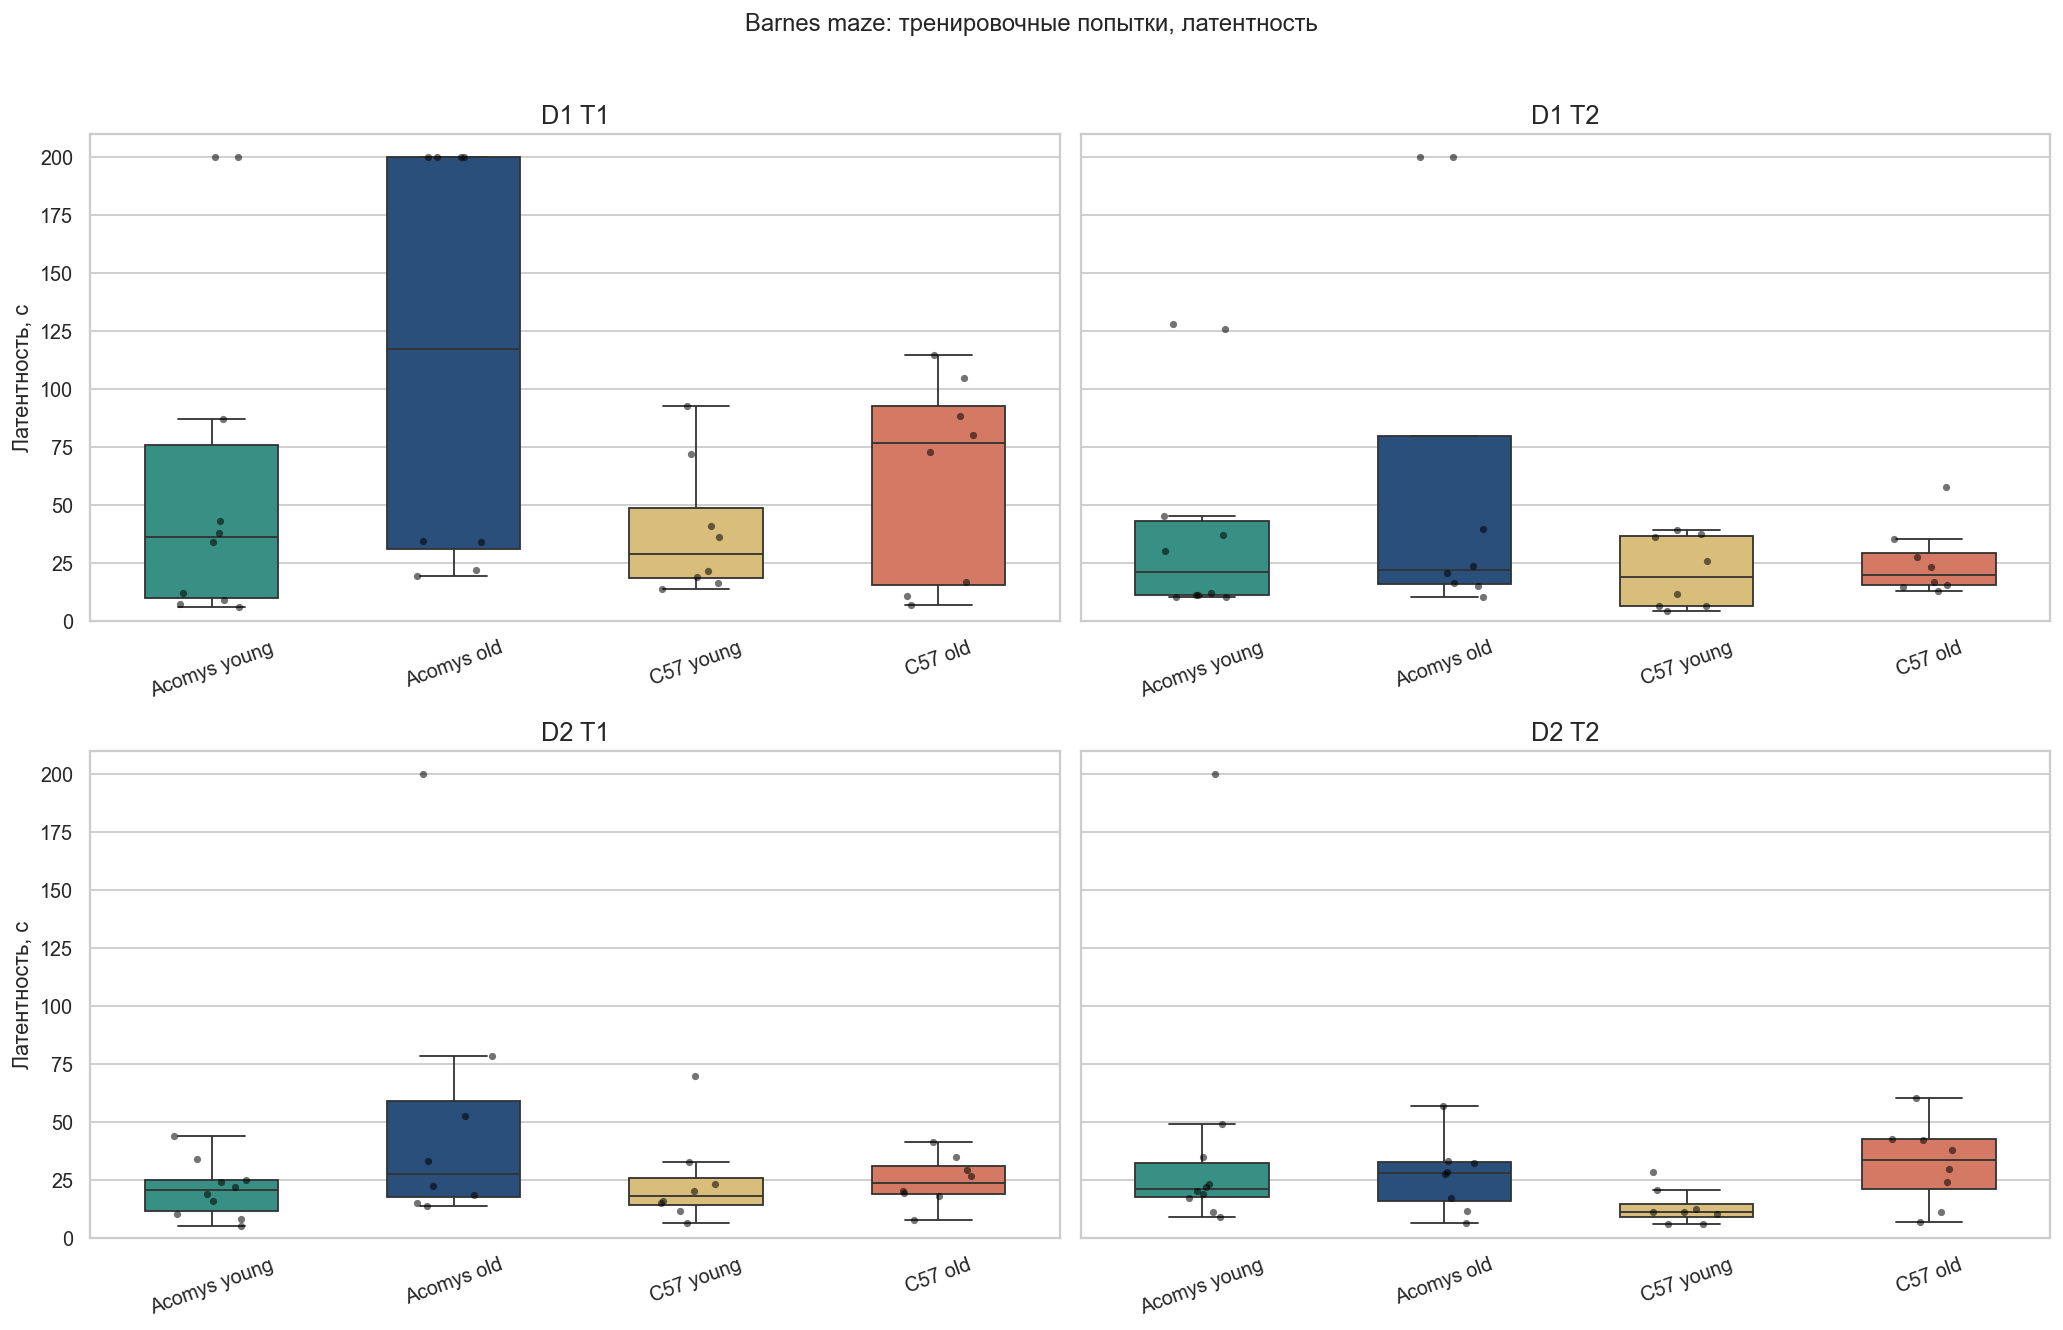

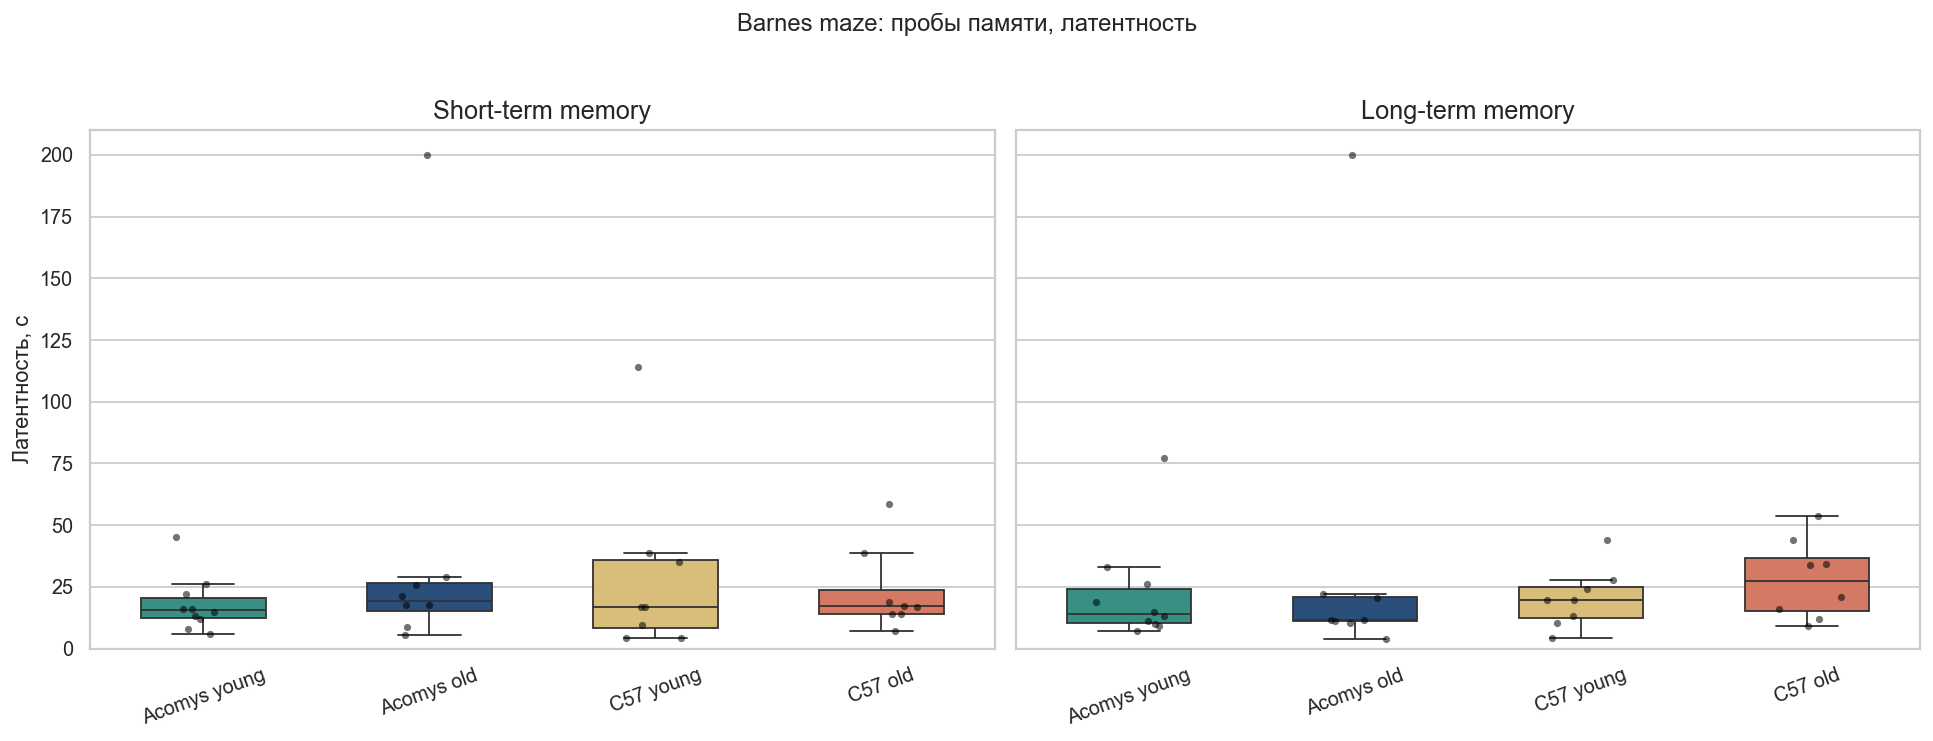

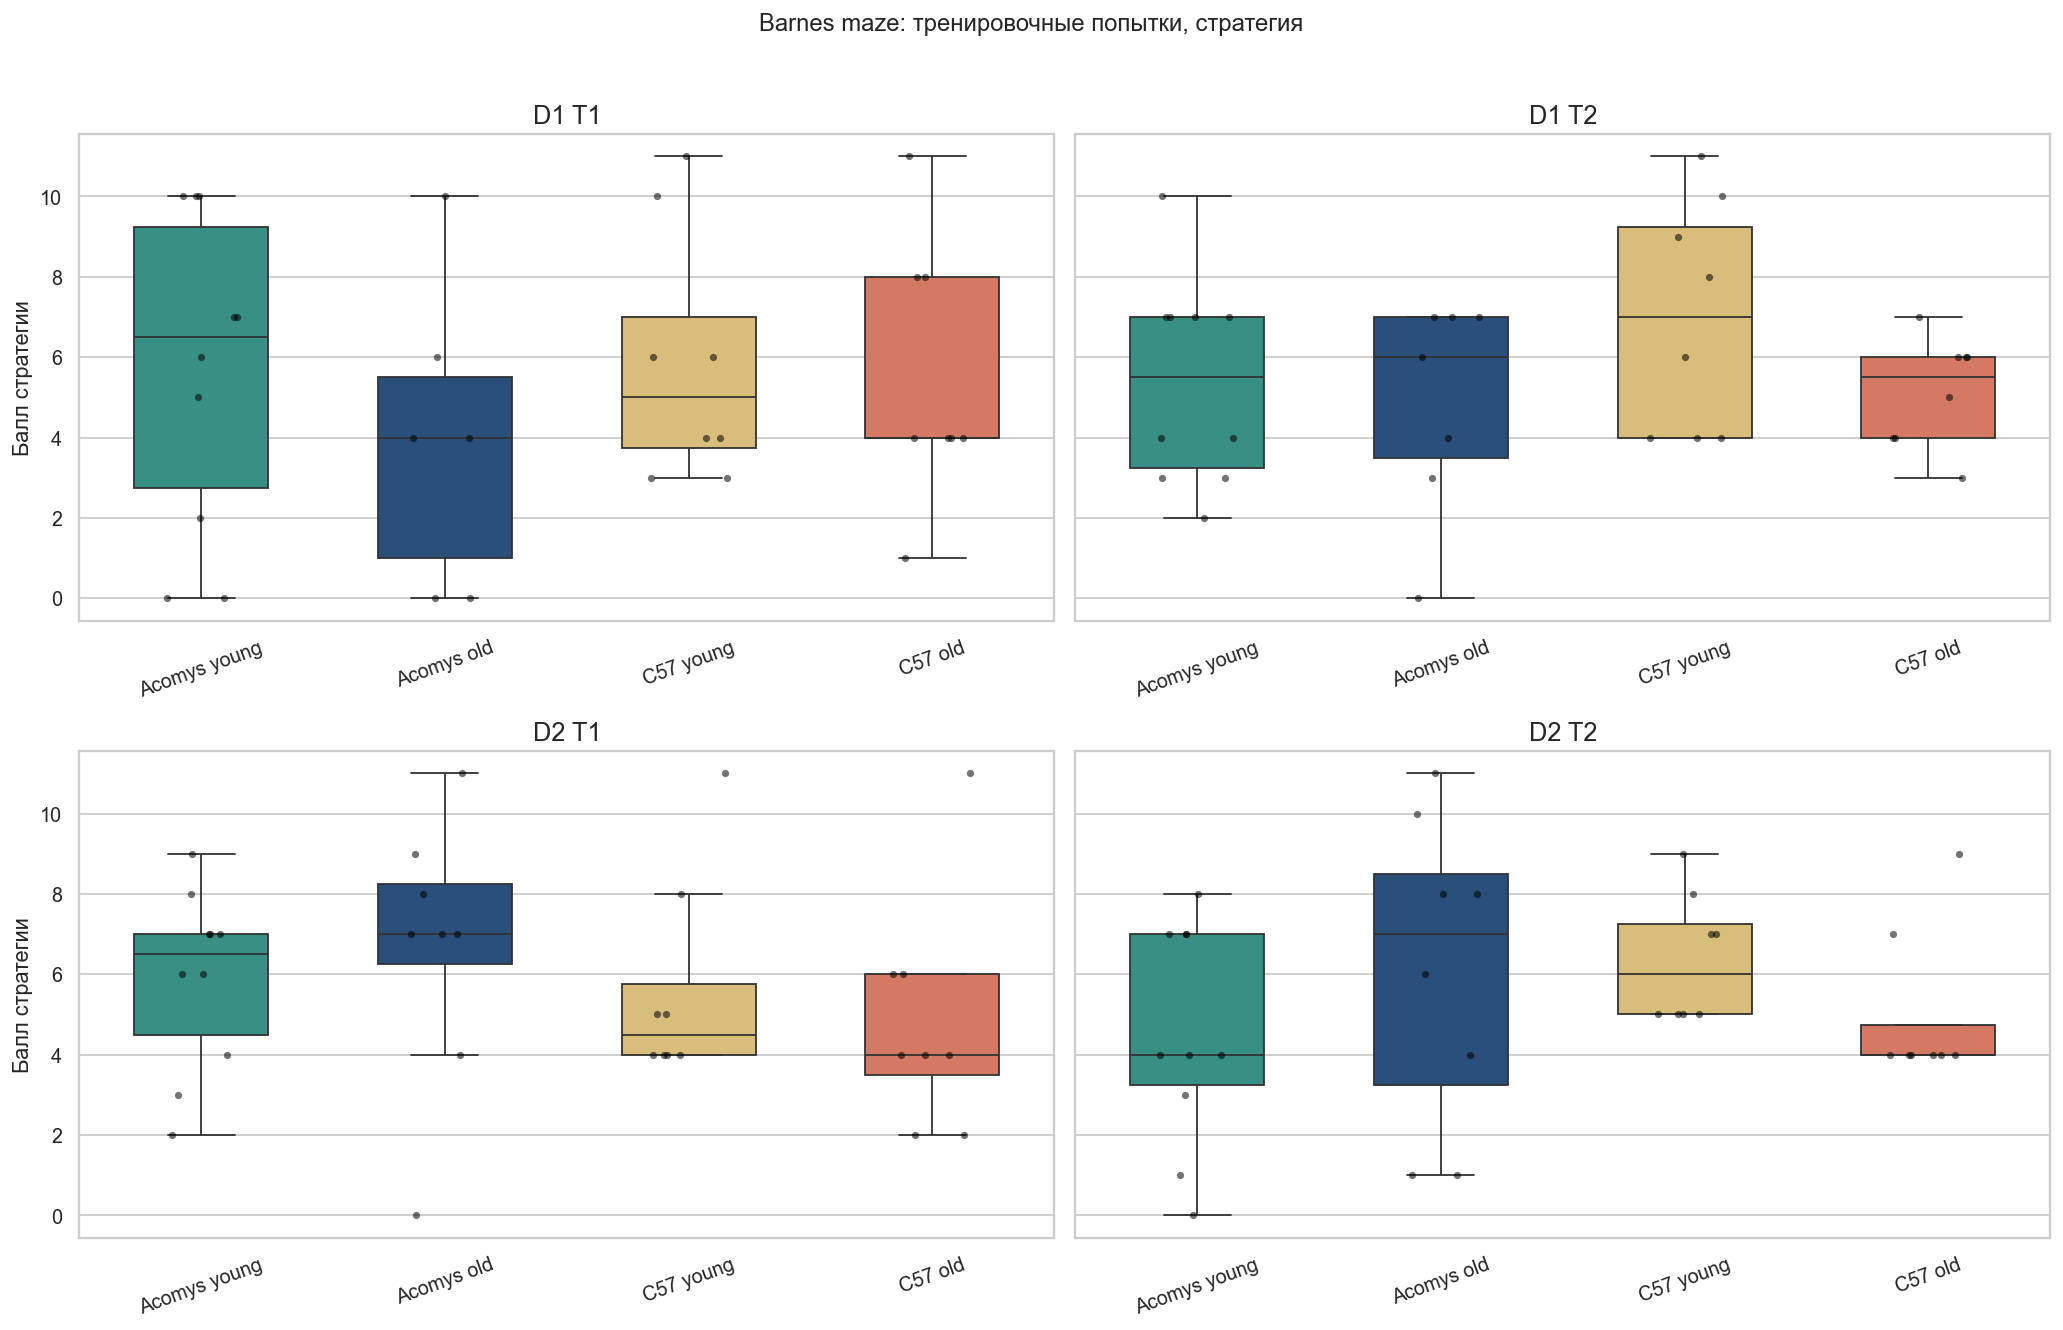

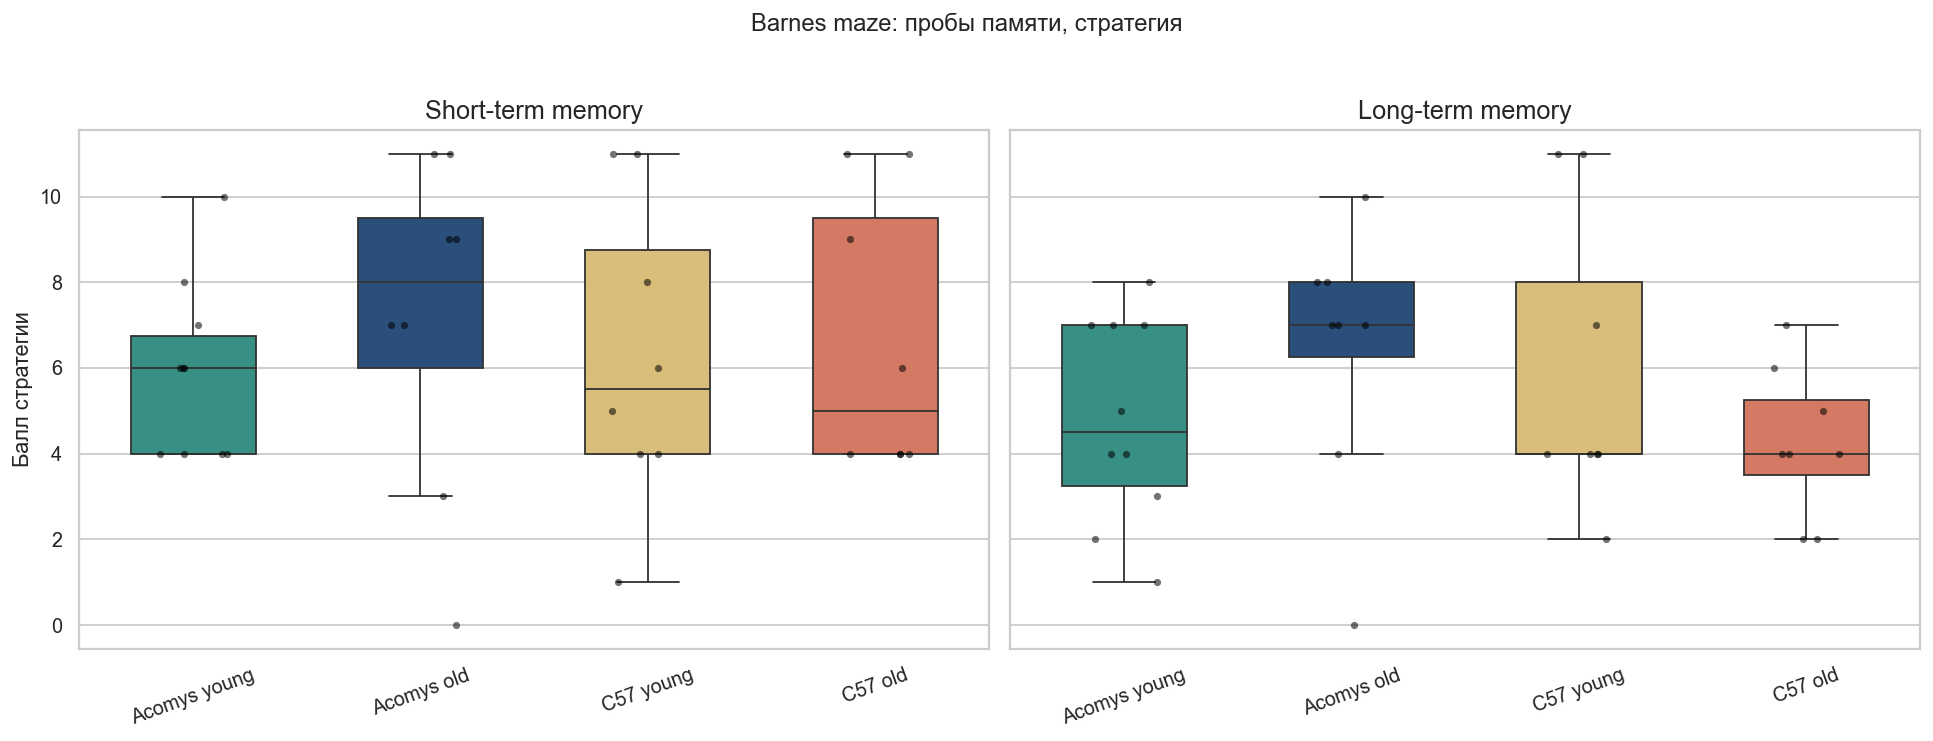

In [6]:
training_phases = [('td1_t1', 'D1 T1'), ('td1_t2', 'D1 T2'), ('td2_t1', 'D2 T1'), ('td2_t2', 'D2 T2')]
memory_phases = [('short_memory', 'Short-term memory'), ('long_memory', 'Long-term memory')]

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
for axis, (phase, title) in zip(axes.flat, training_phases):
    phase_data = barnes_long[barnes_long['phase'] == phase]
    plot_box_strip(phase_data, 'latency_find_censored_s', 'Латентность, с', title, axis)
    axis.set_ylim(0, BARNES_TIMEOUT_SECONDS * 1.05)
fig.suptitle('Barnes maze: тренировочные попытки, латентность', y=1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for axis, (phase, title) in zip(axes, memory_phases):
    phase_data = barnes_long[barnes_long['phase'] == phase]
    plot_box_strip(phase_data, 'latency_find_censored_s', 'Латентность, с', title, axis)
    axis.set_ylim(0, BARNES_TIMEOUT_SECONDS * 1.05)
fig.suptitle('Barnes maze: пробы памяти, латентность', y=1.03)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
for axis, (phase, title) in zip(axes.flat, training_phases):
    phase_data = barnes_long[(barnes_long['phase'] == phase) & barnes_long['strategy_score'].notna()]
    plot_box_strip(phase_data, 'strategy_score', 'Балл стратегии', title, axis)
fig.suptitle('Barnes maze: тренировочные попытки, стратегия', y=1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for axis, (phase, title) in zip(axes, memory_phases):
    phase_data = barnes_long[(barnes_long['phase'] == phase) & barnes_long['strategy_score'].notna()]
    plot_box_strip(phase_data, 'strategy_score', 'Балл стратегии', title, axis)
fig.suptitle('Barnes maze: пробы памяти, стратегия', y=1.03)
fig.tight_layout()
plt.show()


In [7]:
barnes_metric_titles = {
    'barnes_first_training_find_latency_s': 'Barnes: латентность первой тренировки',
    'barnes_last_training_find_latency_s': 'Barnes: латентность последней тренировки',
    'barnes_training_find_latency_change_s': 'Barnes: изменение латентности D2 T2 - D1 T1',
    'barnes_short_find_latency_s': 'Barnes: краткосрочная память, латентность',
    'barnes_short_strategy_score': 'Barnes: краткосрочная память, стратегия',
    'barnes_long_find_latency_s': 'Barnes: долговременная память, латентность',
    'barnes_long_strategy_score': 'Barnes: долговременная память, стратегия',
}
barnes_tests = planned_continuous_tests(barnes_subject, list(barnes_metric_titles), 'barnes')
barnes_tests['metric_title'] = barnes_tests['metric'].map(barnes_metric_titles)
barnes_tests = barnes_tests[['family', 'metric', 'metric_title', 'contrast', 'contrast_title', 'group_a', 'group_b', 'n_a', 'n_b', 'median_a', 'median_b', 'median_diff_a_minus_b', 'cliffs_delta_a_minus_b', 'u_statistic', 'p_value', 'q_value']]
barnes_tests.to_csv(RESULTS_DIR / 'barnes_planned_tests.csv', index=False)
display(barnes_tests.head(24))

best_barnes = barnes_tests.sort_values(['q_value', 'p_value'], na_position='last').iloc[0]
if best_barnes['q_value'] < 0.1:
    barnes_conclusion = f"**Вывод по Barnes maze.** Есть плановое различие после FDR: {best_barnes['metric_title']} ({best_barnes['contrast_title']}), q={best_barnes['q_value']:.3g}, p={best_barnes['p_value']:.3g}."
else:
    barnes_conclusion = f"**Вывод по Barnes maze.** После FDR ни один плановый контраст не проходит q<0.1. Самый сильный сигнал: {best_barnes['metric_title']} ({best_barnes['contrast_title']}), p={best_barnes['p_value']:.3g}, q={best_barnes['q_value']:.3g}."
display(Markdown(barnes_conclusion))


,family,metric,metric_title,contrast,contrast_title,group_a,group_b,n_a,n_b,median_a,median_b,median_diff_a_minus_b,cliffs_delta_a_minus_b,u_statistic,p_value,q_value
0,barnes,barnes_last_training_find_latency_s,Barnes: латентность последней тренировки,age_within_C57,возраст внутри C57,C57 young,C57 old,8,8,11.00,33.65,-22.65,-0.625000,12.0,0.040421,0.576005
1,barnes,barnes_last_training_find_latency_s,Barnes: латентность последней тренировки,species_within_young,вид/линия у молодых,Acomys young,C57 young,10,8,21.00,11.00,10.00,0.550000,62.0,0.055584,0.576005
2,barnes,barnes_long_strategy_score,"Barnes: долговременная память, стратегия",species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,7.00,4.00,3.00,0.562500,50.0,0.061715,0.576005
3,barnes,barnes_training_find_latency_change_s,Barnes: изменение латентности D2 T2 - D1 T1,age_within_Acomys,возраст внутри Acomys,Acomys young,Acomys old,10,8,-6.50,-85.30,78.80,0.450000,58.0,0.121989,0.814291
4,barnes,barnes_long_strategy_score,"Barnes: долговременная память, стратегия",age_within_Acomys,возраст внутри Acomys,Acomys young,Acomys old,10,8,4.50,7.00,-2.50,-0.387500,24.5,0.172763,0.814291
5,barnes,barnes_long_find_latency_s,"Barnes: долговременная память, латентность",species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,11.45,27.45,-16.00,-0.406250,19.0,0.194872,0.814291
6,barnes,barnes_first_training_find_latency_s,Barnes: латентность первой тренировки,species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,117.25,76.60,40.65,0.375000,44.0,0.223710,0.814291
7,barnes,barnes_first_training_find_latency_s,Barnes: латентность первой тренировки,age_within_Acomys,возраст внутри Acomys,Acomys young,Acomys old,10,8,36.00,117.25,-81.25,-0.325000,27.0,0.257940,0.814291
8,barnes,barnes_short_strategy_score,"Barnes: краткосрочная память, стратегия",age_within_Acomys,возраст внутри Acomys,Acomys young,Acomys old,10,8,6.00,8.00,-2.00,-0.325000,27.0,0.261736,0.814291
9,barnes,barnes_training_find_latency_change_s,Barnes: изменение латентности D2 T2 - D1 T1,species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,-85.30,-36.50,-48.80,-0.312500,22.0,0.328205,0.890095


**Вывод по Barnes maze.** После FDR ни один плановый контраст не проходит q<0.1. Самый сильный сигнал: Barnes: латентность последней тренировки (возраст внутри C57), p=0.0404, q=0.576.

### Barnes maze: успешность выполнения и вход в escape box

Нахождение цели и вход в escape box — разные бинарные исходы: животное могло найти нужное отверстие, но не войти в укрытие. Для каждой фазы ниже показаны число и доля успешных животных. Значения `No data`, соответствующие невыполнению за 200 секунд, учитываются как неуспех.

Межгрупповые сравнения выполняются отдельно для `D1 T1`, `D2 T2`, краткосрочной и долговременной памяти двусторонним точным критерием Фишера. Он проверяет связь между группой и бинарным исходом по таблице 2×2 и подходит для малых выборок. FDR контролируется методом Benjamini—Hochberg одновременно по 32 тестам (`2 исхода × 4 фазы × 4 плановых контраста`).

Изменение от `D1 T1` к `D2 T2` внутри каждой группы проверяется точным критерием Мак-Немара по дискордантным парам одного животного: отдельно считаются переходы неуспех → успех и успех → неуспех. Эти восемь тестов (`2 исхода × 4 группы`) образуют отдельное семейство FDR. Попытки одного животного не рассматриваются как независимые наблюдения.


In [8]:
BARNES_BINARY_OUTCOMES = {
    'found_target': 'Нашло цель',
    'entered_escape': 'Вошло в escape box',
}
BARNES_BINARY_ENDPOINTS = [
    ('td1_t1', 'D1 T1'),
    ('td2_t2', 'D2 T2'),
    ('short_memory', 'Short-term memory'),
    ('long_memory', 'Long-term memory'),
]

binary_summary_rows = []
for outcome, outcome_title in BARNES_BINARY_OUTCOMES.items():
    for phase, phase_title, _, phase_order in BARNES_PHASES:
        phase_data = barnes_long[barnes_long['phase'] == phase]
        for group in GROUP_ORDER:
            values = phase_data.loc[phase_data['group'] == group, outcome].dropna().astype(int)
            success_n = int(values.sum())
            n = int(len(values))
            binary_summary_rows.append({
                'outcome': outcome, 'outcome_title': outcome_title,
                'phase': phase, 'phase_title': phase_title, 'phase_order': phase_order,
                'group': group, 'n': n, 'success_n': success_n,
                'success_rate': success_n / n if n else np.nan,
            })

barnes_binary_summary = pd.DataFrame(binary_summary_rows)
barnes_binary_summary['success_display'] = barnes_binary_summary.apply(
    lambda row: f"{int(row['success_n'])}/{int(row['n'])} ({100 * row['success_rate']:.1f}%)" if row['n'] else 'нет данных',
    axis=1,
)
barnes_binary_summary.to_csv(RESULTS_DIR / 'barnes_binary_group_summary.csv', index=False)
binary_summary_display = barnes_binary_summary.pivot(
    index=['outcome_title', 'phase_order', 'phase_title'], columns='group', values='success_display',
).reset_index().sort_values(['outcome_title', 'phase_order']).drop(columns='phase_order').rename(columns={
    'outcome_title': 'Исход', 'phase_title': 'Фаза',
})
binary_summary_display.columns.name = None
display(binary_summary_display)

binary_test_rows = []
for outcome, outcome_title in BARNES_BINARY_OUTCOMES.items():
    for phase, phase_title in BARNES_BINARY_ENDPOINTS:
        phase_data = barnes_long[barnes_long['phase'] == phase]
        for contrast, contrast_title, group_a, group_b in PLANNED_CONTRASTS:
            values_a = phase_data.loc[phase_data['group'] == group_a, outcome].dropna().astype(int)
            values_b = phase_data.loc[phase_data['group'] == group_b, outcome].dropna().astype(int)
            success_a = int(values_a.sum())
            success_b = int(values_b.sum())
            n_a = int(len(values_a))
            n_b = int(len(values_b))
            contingency = [[success_a, n_a - success_a], [success_b, n_b - success_b]]
            odds_ratio, p_value = stats.fisher_exact(contingency, alternative='two-sided')
            binary_test_rows.append({
                'outcome': outcome, 'outcome_title': outcome_title,
                'phase': phase, 'phase_title': phase_title,
                'contrast': contrast, 'contrast_title': contrast_title,
                'group_a': group_a, 'group_b': group_b,
                'n_a': n_a, 'success_a': success_a, 'success_rate_a': success_a / n_a,
                'n_b': n_b, 'success_b': success_b, 'success_rate_b': success_b / n_b,
                'risk_difference_a_minus_b': success_a / n_a - success_b / n_b,
                'odds_ratio_a_vs_b': odds_ratio, 'p_value': p_value,
            })

barnes_binary_tests = pd.DataFrame(binary_test_rows)
barnes_binary_tests['q_value'] = bh_q(barnes_binary_tests['p_value'])
barnes_binary_tests = barnes_binary_tests.sort_values(['q_value', 'p_value']).reset_index(drop=True)
barnes_binary_tests.to_csv(RESULTS_DIR / 'barnes_binary_planned_tests.csv', index=False)
binary_tests_display = barnes_binary_tests[[
    'outcome_title', 'phase_title', 'contrast_title', 'group_a', 'success_a', 'n_a',
    'group_b', 'success_b', 'n_b', 'risk_difference_a_minus_b', 'p_value', 'q_value',
]].rename(columns={
    'outcome_title': 'Исход', 'phase_title': 'Фаза', 'contrast_title': 'Сравнение',
    'group_a': 'Группа A', 'success_a': 'Успех A', 'n_a': 'n A',
    'group_b': 'Группа B', 'success_b': 'Успех B', 'n_b': 'n B',
    'risk_difference_a_minus_b': 'Разность долей A−B',
    'p_value': 'p_value', 'q_value': 'q_value',
})
display(binary_tests_display.round(5))

mcnemar_rows = []
for outcome, outcome_title in BARNES_BINARY_OUTCOMES.items():
    first_last = barnes_long[barnes_long['phase'].isin(['td1_t1', 'td2_t2'])].pivot_table(
        index=['species', 'age', 'group', 'animal_id'], columns='phase', values=outcome, aggfunc='first',
    ).reset_index()
    for group in GROUP_ORDER:
        group_pairs = first_last[first_last['group'] == group].dropna(subset=['td1_t1', 'td2_t2'])
        first = group_pairs['td1_t1'].astype(int)
        last = group_pairs['td2_t2'].astype(int)
        failure_to_success = int(((first == 0) & (last == 1)).sum())
        success_to_failure = int(((first == 1) & (last == 0)).sum())
        discordant = failure_to_success + success_to_failure
        p_value = stats.binomtest(
            min(failure_to_success, success_to_failure), n=discordant, p=0.5, alternative='two-sided',
        ).pvalue if discordant else 1.0
        mcnemar_rows.append({
            'outcome': outcome, 'outcome_title': outcome_title, 'group': group,
            'n_pairs': int(len(group_pairs)),
            'success_first': int(first.sum()), 'success_last': int(last.sum()),
            'failure_to_success': failure_to_success, 'success_to_failure': success_to_failure,
            'success_rate_change': float(last.mean() - first.mean()), 'p_value': float(p_value),
        })

barnes_binary_changes = pd.DataFrame(mcnemar_rows)
barnes_binary_changes['q_value'] = bh_q(barnes_binary_changes['p_value'])
barnes_binary_changes = barnes_binary_changes.sort_values(['q_value', 'p_value']).reset_index(drop=True)
barnes_binary_changes.to_csv(RESULTS_DIR / 'barnes_binary_within_group_changes.csv', index=False)
binary_changes_display = barnes_binary_changes[[
    'outcome_title', 'group', 'n_pairs', 'success_first', 'success_last',
    'failure_to_success', 'success_to_failure', 'success_rate_change', 'p_value', 'q_value',
]].rename(columns={
    'outcome_title': 'Исход', 'group': 'Группа', 'n_pairs': 'Пар',
    'success_first': 'Успех D1 T1', 'success_last': 'Успех D2 T2',
    'failure_to_success': 'Неуспех→успех', 'success_to_failure': 'Успех→неуспех',
    'success_rate_change': 'Изменение доли', 'p_value': 'p_value', 'q_value': 'q_value',
})
display(binary_changes_display.round(5))


,Исход,Фаза,Acomys old,Acomys young,C57 old,C57 young
0,Вошло в escape box,Training Day 1 Trial 1,3/8 (37.5%),8/10 (80.0%),3/8 (37.5%),2/8 (25.0%)
1,Вошло в escape box,Training Day 1 Trial 2,5/8 (62.5%),10/10 (100.0%),5/8 (62.5%),4/8 (50.0%)
2,Вошло в escape box,Training Day 2 Trial 1,6/8 (75.0%),10/10 (100.0%),6/8 (75.0%),3/8 (37.5%)
3,Вошло в escape box,Training Day 2 Trial 2,8/8 (100.0%),9/10 (90.0%),7/8 (87.5%),4/8 (50.0%)
4,Вошло в escape box,Short-term memory,6/8 (75.0%),10/10 (100.0%),5/8 (62.5%),4/8 (50.0%)
5,Вошло в escape box,Long-term memory,6/8 (75.0%),10/10 (100.0%),8/8 (100.0%),5/8 (62.5%)
6,Нашло цель,Training Day 1 Trial 1,4/8 (50.0%),8/10 (80.0%),8/8 (100.0%),8/8 (100.0%)
7,Нашло цель,Training Day 1 Trial 2,6/8 (75.0%),10/10 (100.0%),8/8 (100.0%),8/8 (100.0%)
8,Нашло цель,Training Day 2 Trial 1,7/8 (87.5%),10/10 (100.0%),8/8 (100.0%),8/8 (100.0%)
9,Нашло цель,Training Day 2 Trial 2,8/8 (100.0%),9/10 (90.0%),8/8 (100.0%),8/8 (100.0%)


,Исход,Фаза,Сравнение,Группа A,Успех A,n A,Группа B,Успех B,n B,Разность долей A−B,p_value,q_value
0,Вошло в escape box,Short-term memory,вид/линия у молодых,Acomys young,10,10,C57 young,4,8,0.500,0.02288,0.61538
1,Вошло в escape box,D1 T1,вид/линия у молодых,Acomys young,8,10,C57 young,2,8,0.550,0.05361,0.61538
2,Вошло в escape box,Long-term memory,вид/линия у молодых,Acomys young,10,10,C57 young,5,8,0.375,0.06863,0.61538
3,Нашло цель,D1 T1,вид/линия у старых,Acomys old,4,8,C57 old,8,8,-0.500,0.07692,0.61538
4,Вошло в escape box,D2 T2,вид/линия у молодых,Acomys young,9,10,C57 young,4,8,0.400,0.11765,0.71111
5,Вошло в escape box,D1 T1,возраст внутри Acomys,Acomys young,8,10,Acomys old,3,8,0.425,0.14480,0.71111
6,Вошло в escape box,Short-term memory,возраст внутри Acomys,Acomys young,10,10,Acomys old,6,8,0.250,0.18301,0.71111
7,Вошло в escape box,Long-term memory,возраст внутри Acomys,Acomys young,10,10,Acomys old,6,8,0.250,0.18301,0.71111
8,Вошло в escape box,Long-term memory,возраст внутри C57,C57 young,5,8,C57 old,8,8,-0.375,0.20000,0.71111
9,Вошло в escape box,D2 T2,возраст внутри C57,C57 young,4,8,C57 old,7,8,-0.375,0.28205,0.90256


,Исход,Группа,Пар,Успех D1 T1,Успех D2 T2,Неуспех→успех,Успех→неуспех,Изменение доли,p_value,q_value
0,Вошло в escape box,Acomys old,8,3,8,5,0,0.625,0.06250,0.50000
1,Нашло цель,Acomys old,8,4,8,4,0,0.500,0.12500,0.50000
2,Вошло в escape box,C57 old,8,3,7,5,1,0.500,0.21875,0.58333
3,Вошло в escape box,C57 young,8,2,4,3,1,0.250,0.62500,1.00000
4,Нашло цель,Acomys young,10,8,9,2,1,0.100,1.00000,1.00000
5,Нашло цель,C57 young,8,8,8,0,0,0.000,1.00000,1.00000
6,Нашло цель,C57 old,8,8,8,0,0,0.000,1.00000,1.00000
7,Вошло в escape box,Acomys young,10,8,9,2,1,0.100,1.00000,1.00000


**Вывод по успешности Barnes maze.** Нахождение цели почти достигает потолка: начиная с `D1 T2` её находят практически все животные. Вход в escape box различает поведение лучше. Наиболее заметное межгрупповое различие наблюдается в краткосрочной памяти: вошли 10/10 молодых Acomys и 4/8 молодых C57 (`p=0,0229`), однако после общей поправки по 32 бинарным сравнениям оно незначимо (`q=0,615`). Ни один другой межгрупповой бинарный контраст также не проходит FDR.

От первой к последней тренировке наиболее выраженное зависимое изменение видно у старых Acomys: доля вошедших в escape box увеличивается с 3/8 до 8/8, причём пять животных переходят от неуспеха к успеху и ни одно — обратно. Для точного критерия Мак-Немара `p=0,0625`, после поправки по восьми внутригрупповым тестам `q=0,500`. Таким образом, данные описательно указывают на обучение и на различия между нахождением цели и фактическим входом в укрытие, но при текущем размере выборок статистически устойчивого бинарного эффекта нет. Результат для молодых Acomys остаётся предварительным до утверждения состава группы из восьми животных.


In [9]:
rotarod = rotarod_raw.rename(columns={
    'young/old': 'age_source', '1 trial, s': 'rotarod_trial1_s', '2 trial, s': 'rotarod_trial2_s',
    '1 trial': 'rotarod_trial1_s', '2 trial': 'rotarod_trial2_s',
}).copy()
for col in ['rotarod_trial1_s', 'rotarod_trial2_s']:
    rotarod[col] = rotarod[col].map(to_number)
rotarod['rotarod_improvement_s'] = rotarod['rotarod_trial2_s'] - rotarod['rotarod_trial1_s']
rotarod.to_csv(RESULTS_DIR / 'rotarod_subject_metrics.csv', index=False)

rotarod_metric_titles = {
    'rotarod_trial1_s': 'Rotarod: 1 попытка', 'rotarod_trial2_s': 'Rotarod: 2 попытка',
    'rotarod_improvement_s': 'Rotarod: изменение 2-1 попытка',
}
rotarod_group_summary = group_summary(rotarod, list(rotarod_metric_titles))
rotarod_group_summary.to_csv(RESULTS_DIR / 'rotarod_group_summary.csv', index=False)
display(rotarod_group_summary)


,metric,group,n,mean,median,std,iqr,min,max
0,rotarod_trial1_s,Acomys old,8,25.125000,27.0,7.735586,8.00,14,39
1,rotarod_trial1_s,Acomys young,11,35.363636,39.0,9.604923,12.50,16,49
2,rotarod_trial1_s,C57 old,8,10.625000,9.5,7.029276,5.00,5,27
3,rotarod_trial1_s,C57 young,8,10.375000,9.5,4.340425,2.25,5,20
4,rotarod_trial2_s,Acomys old,8,28.125000,28.5,9.140764,7.00,11,43
5,rotarod_trial2_s,Acomys young,11,30.454545,26.0,10.671116,17.00,18,49
6,rotarod_trial2_s,C57 old,8,15.750000,16.0,5.391793,8.50,10,24
7,rotarod_trial2_s,C57 young,8,14.625000,13.5,5.370222,5.50,9,25
8,rotarod_improvement_s,Acomys old,8,3.000000,3.0,6.740072,6.25,-7,12
9,rotarod_improvement_s,Acomys young,11,-4.909091,-4.0,10.967721,17.00,-23,11


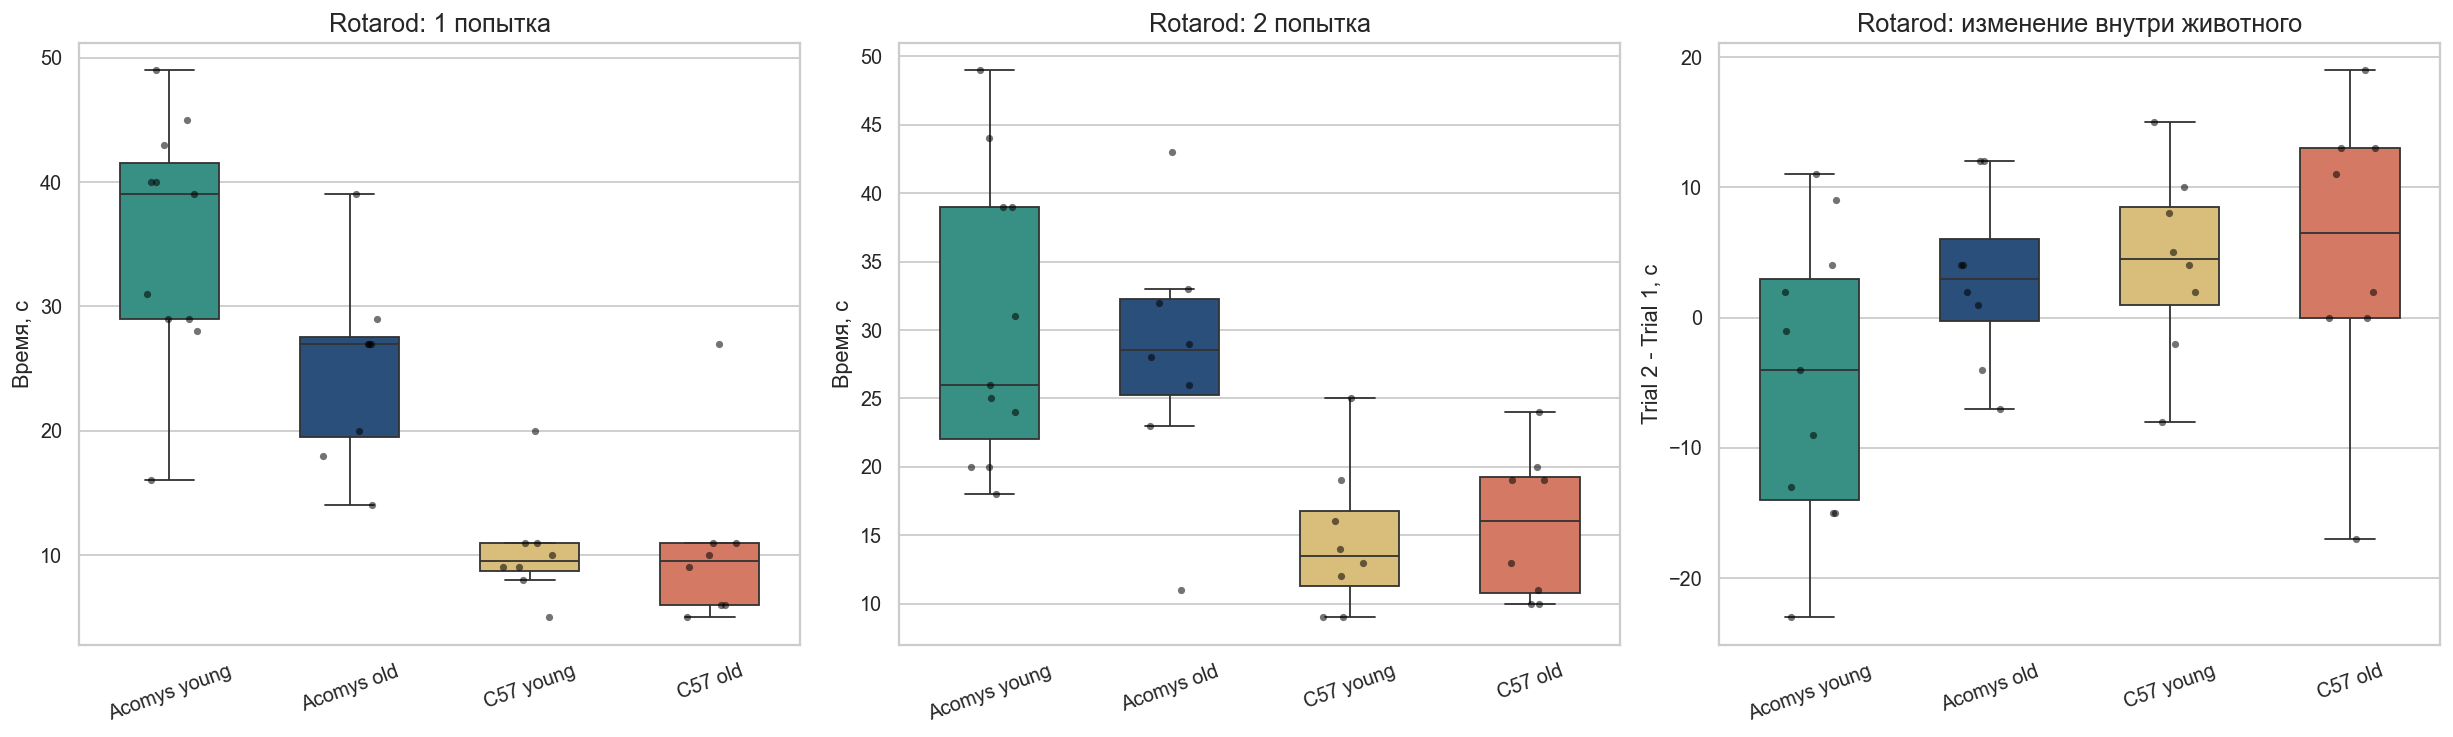

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
plot_box_strip(rotarod, 'rotarod_trial1_s', 'Время, с', 'Rotarod: 1 попытка', axes[0])
plot_box_strip(rotarod, 'rotarod_trial2_s', 'Время, с', 'Rotarod: 2 попытка', axes[1])
plot_box_strip(rotarod, 'rotarod_improvement_s', 'Trial 2 - Trial 1, с', 'Rotarod: изменение внутри животного', axes[2])
fig.tight_layout()
plt.show()


In [11]:
rotarod_tests = planned_continuous_tests(rotarod, list(rotarod_metric_titles), 'rotarod')
rotarod_tests['metric_title'] = rotarod_tests['metric'].map(rotarod_metric_titles)
rotarod_tests = rotarod_tests[['family', 'metric', 'metric_title', 'contrast', 'contrast_title', 'group_a', 'group_b', 'n_a', 'n_b', 'median_a', 'median_b', 'median_diff_a_minus_b', 'cliffs_delta_a_minus_b', 'u_statistic', 'p_value', 'q_value']]
rotarod_tests.to_csv(RESULTS_DIR / 'rotarod_planned_tests.csv', index=False)
display(rotarod_tests.head(24))

best_rotarod = rotarod_tests.sort_values(['q_value', 'p_value'], na_position='last').iloc[0]
rotarod_hits = rotarod_tests[rotarod_tests['q_value'] < 0.1]
rotarod_conclusion = f"**Вывод по rotarod.** Значимых после FDR контрастов q<0.1: {len(rotarod_hits)}. Самый сильный сигнал: {best_rotarod['metric_title']} ({best_rotarod['contrast_title']}), медианы {best_rotarod['group_a']}={best_rotarod['median_a']:.2f}, {best_rotarod['group_b']}={best_rotarod['median_b']:.2f}, p={best_rotarod['p_value']:.3g}, q={best_rotarod['q_value']:.3g}."
display(Markdown(rotarod_conclusion))


,family,metric,metric_title,contrast,contrast_title,group_a,group_b,n_a,n_b,median_a,median_b,median_diff_a_minus_b,cliffs_delta_a_minus_b,u_statistic,p_value,q_value
0,rotarod,rotarod_trial1_s,Rotarod: 1 попытка,species_within_young,вид/линия у молодых,Acomys young,C57 young,11,8,39.0,9.5,29.5,0.977273,87.0,0.000439,0.005267
1,rotarod,rotarod_trial2_s,Rotarod: 2 попытка,species_within_young,вид/линия у молодых,Acomys young,C57 young,11,8,26.0,13.5,12.5,0.875000,82.5,0.001671,0.010024
2,rotarod,rotarod_trial1_s,Rotarod: 1 попытка,species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,27.0,9.5,17.5,0.859375,59.5,0.004224,0.016896
3,rotarod,rotarod_trial2_s,Rotarod: 2 попытка,species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,28.5,16.0,12.5,0.796875,57.5,0.008505,0.025515
4,rotarod,rotarod_trial1_s,Rotarod: 1 попытка,age_within_Acomys,возраст внутри Acomys,Acomys young,Acomys old,11,8,39.0,27.0,12.0,0.693182,74.5,0.012843,0.030822
5,rotarod,rotarod_improvement_s,Rotarod: изменение 2-1 попытка,species_within_young,вид/линия у молодых,Acomys young,C57 young,11,8,-4.0,4.5,-8.5,-0.500000,22.0,0.075462,0.150924
6,rotarod,rotarod_improvement_s,Rotarod: изменение 2-1 попытка,age_within_Acomys,возраст внутри Acomys,Acomys young,Acomys old,11,8,-4.0,3.0,-7.0,-0.454545,24.0,0.106129,0.181936
7,rotarod,rotarod_improvement_s,Rotarod: изменение 2-1 попытка,species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,3.0,6.5,-3.5,-0.171875,26.5,0.598161,0.897111
8,rotarod,rotarod_trial2_s,Rotarod: 2 попытка,age_within_C57,возраст внутри C57,C57 young,C57 old,8,8,13.5,16.0,-2.5,-0.140625,27.5,0.672833,0.897111
9,rotarod,rotarod_improvement_s,Rotarod: изменение 2-1 попытка,age_within_C57,возраст внутри C57,C57 young,C57 old,8,8,4.5,6.5,-2.0,-0.109375,28.5,0.752184,0.902621


**Вывод по rotarod.** Значимых после FDR контрастов q<0.1: 5. Самый сильный сигнал: Rotarod: 1 попытка (вид/линия у молодых), медианы Acomys young=39.00, C57 young=9.50, p=0.000439, q=0.00527.

### Rotarod: модель повторных измерений

Две попытки одного животного не являются независимыми. Поэтому используется линейная mixed-effects model: фиксированные эффекты описывают систематические различия между видом/линией, возрастом и попытками, а случайный intercept животного учитывает индивидуальный исходный уровень и корреляцию двух измерений одного животного.

Формула основной модели: `time_s ~ species * age * trial + (1 | animal)`. Запись со звёздочками разворачивается в основные эффекты `species`, `age`, `trial`, все три двухфакторных взаимодействия (`species:age`, `species:trial`, `age:trial`) и трёхфакторное взаимодействие `species:age:trial`. Таким образом модель проверяет не только общие различия вида/линии, возраста и попытки, но и зависит ли изменение между попытками от возраста и вида/линии.

Коэффициенты фиксированных эффектов проверяются двусторонними Wald z-тестами. Глобальный вклад каждого фактора проверяется likelihood-ratio test: полная модель, оценённая методом максимального правдоподобия, сравнивается с вложенной моделью, из которой удалён соответствующий основной эффект и все включённые взаимодействия с ним; p-value получают по χ²-распределению разности логарифмических правдоподобий. FDR контролируется методом Benjamini—Hochberg отдельно для таблицы коэффициентов фиксированных эффектов и для трёх глобальных likelihood-ratio тестов; поэтому в обеих таблицах показаны `p_value` и `q_value`. Пока в `Acomys young` присутствуют 11 животных вместо ожидаемых 8, результаты модели предварительные.


In [12]:
rotarod_long = rotarod.melt(
    id_vars=['species', 'age_clean', 'group', 'animal_id'],
    value_vars=['rotarod_trial1_s', 'rotarod_trial2_s'],
    var_name='trial_label', value_name='time_s',
)
rotarod_long['trial'] = rotarod_long['trial_label'].map({'rotarod_trial1_s': '1', 'rotarod_trial2_s': '2'})
rotarod_long['subject_key'] = rotarod_long['species'].astype(str) + '_' + rotarod_long['age_clean'].astype(str) + '_' + rotarod_long['animal_id'].astype(str)

species_term = "C(species, Treatment(reference='C57'))"
age_term = "C(age_clean, Treatment(reference='young'))"
trial_term = "C(trial, Treatment(reference='1'))"
rotarod_full_formula = f'time_s ~ {species_term} * {age_term} * {trial_term}'

def fit_rotarod_mixed(formula):
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        fitted = smf.mixedlm(formula, data=rotarod_long, groups=rotarod_long['subject_key']).fit(reml=False, method='lbfgs')
    return fitted, sorted({str(item.message) for item in captured})

rotarod_mixed, rotarod_mixed_warnings = fit_rotarod_mixed(rotarod_full_formula)
rotarod_model_diagnostics = pd.DataFrame([
    {'diagnostic': 'n observations', 'value': int(rotarod_mixed.nobs)},
    {'diagnostic': 'n animals', 'value': rotarod_long['subject_key'].nunique()},
    {'diagnostic': 'converged', 'value': bool(rotarod_mixed.converged)},
    {'diagnostic': 'random intercept variance', 'value': float(rotarod_mixed.cov_re.iloc[0, 0])},
    {'diagnostic': 'residual variance', 'value': float(rotarod_mixed.scale)},
])
rotarod_fixed_effects = pd.DataFrame({
    'term': rotarod_mixed.fe_params.index,
    'estimate_s': rotarod_mixed.fe_params.values,
    'std_error': rotarod_mixed.bse_fe.values,
    'p_value': rotarod_mixed.pvalues.loc[rotarod_mixed.fe_params.index].values,
})
rotarod_fixed_effects['q_value'] = bh_q(rotarod_fixed_effects['p_value'])
rotarod_model_diagnostics.to_csv(RESULTS_DIR / 'rotarod_mixed_model_diagnostics.csv', index=False)
rotarod_fixed_effects.to_csv(RESULTS_DIR / 'rotarod_mixed_model_fixed_effects.csv', index=False)
display(rotarod_model_diagnostics)
display(pd.DataFrame({'model warning': rotarod_mixed_warnings or ['нет предупреждений']}))
display(rotarod_fixed_effects.round(5))


,diagnostic,value
0,n observations,70
1,n animals,35
2,converged,True
3,random intercept variance,16.669361
4,residual variance,39.732714


,model warning
0,Random effects covariance is singular


,term,estimate_s,std_error,p_value,q_value
0,Intercept,10.37500,2.65523,0.00009,0.00037
1,"C(species, Treatment(reference='C57'))[T.Acomys]",24.98864,3.48966,0.00000,0.00000
2,"C(age_clean, Treatment(reference='young'))[T.old]",0.25000,3.75507,0.94692,0.94692
3,"C(trial, Treatment(reference='1'))[T.2]",4.25000,3.15169,0.17750,0.28401
4,"C(species, Treatment(reference='C57'))[T.Acomys]:C(age_clean, Treatment(reference='young'))[T.old]",-10.48864,5.12623,0.04075,0.08150
5,"C(species, Treatment(reference='C57'))[T.Acomys]:C(trial, Treatment(reference='1'))[T.2]",-9.15909,4.14214,0.02702,0.07206
6,"C(age_clean, Treatment(reference='young'))[T.old]:C(trial, Treatment(reference='1'))[T.2]",0.87500,4.45717,0.84437,0.94692
7,"C(species, Treatment(reference='C57'))[T.Acomys]:C(age_clean, Treatment(reference='young'))[T.old]:C(trial, Treatmen...",7.03409,6.08471,0.24767,0.33023


In [13]:
rotarod_model_formulas = {
    'full': rotarod_full_formula,
    'no_species': f'time_s ~ {age_term} * {trial_term}',
    'no_age': f'time_s ~ {species_term} * {trial_term}',
    'no_trial': f'time_s ~ {species_term} * {age_term}',
}
rotarod_model_results = {'full': rotarod_mixed}
for model_name, formula in rotarod_model_formulas.items():
    if model_name != 'full':
        rotarod_model_results[model_name], _ = fit_rotarod_mixed(formula)

rotarod_lrt_rows = []
for effect, reduced_name in [('species', 'no_species'), ('age', 'no_age'), ('trial', 'no_trial')]:
    reduced = rotarod_model_results[reduced_name]
    lr = 2 * (rotarod_mixed.llf - reduced.llf)
    df = rotarod_mixed.df_modelwc - reduced.df_modelwc
    rotarod_lrt_rows.append({'effect_with_interactions': effect, 'LR': lr, 'df': df, 'p_value': stats.chi2.sf(lr, df)})
rotarod_lrt = pd.DataFrame(rotarod_lrt_rows)
rotarod_lrt['q_value'] = bh_q(rotarod_lrt['p_value'])
rotarod_lrt.to_csv(RESULTS_DIR / 'rotarod_mixed_model_global_tests.csv', index=False)
display(rotarod_lrt.round(6))

species_p = rotarod_lrt.loc[rotarod_lrt['effect_with_interactions'] == 'species', 'p_value'].iloc[0]
species_q = rotarod_lrt.loc[rotarod_lrt['effect_with_interactions'] == 'species', 'q_value'].iloc[0]
age_p = rotarod_lrt.loc[rotarod_lrt['effect_with_interactions'] == 'age', 'p_value'].iloc[0]
age_q = rotarod_lrt.loc[rotarod_lrt['effect_with_interactions'] == 'age', 'q_value'].iloc[0]
trial_p = rotarod_lrt.loc[rotarod_lrt['effect_with_interactions'] == 'trial', 'p_value'].iloc[0]
trial_q = rotarod_lrt.loc[rotarod_lrt['effect_with_interactions'] == 'trial', 'q_value'].iloc[0]
mixed_warning_note = (
    " При подборе модели возникло предупреждение `Random effects covariance is singular`: модель не вполне устойчиво разделяет межиндивидуальную вариабельность животных и остаточный шум. Поэтому оценки random intercept, стандартные ошибки и p-value следует интерпретировать осторожно."
    if any('singular' in warning.lower() for warning in rotarod_mixed_warnings) else ''
)
display(Markdown(f"**Вывод mixed model.** Глобальный вклад вида/линии: p={species_p:.3g}, q={species_q:.3g}; возраста: p={age_p:.3g}, q={age_q:.3g}; попытки: p={trial_p:.3g}, q={trial_q:.3g}. Для трёх глобальных тестов q рассчитаны методом Benjamini—Hochberg. Модель учитывает две связанные попытки.{mixed_warning_note} Результат должен быть пересчитан после утверждения восьми молодых Acomys."))


,effect_with_interactions,LR,df,p_value,q_value
0,species,44.073880,4,0.000000,0.000000
1,age,8.227266,4,0.083599,0.100228
2,trial,7.773712,4,0.100228,0.100228


**Вывод mixed model.** Глобальный вклад вида/линии: p=6.19e-09, q=1.86e-08; возраста: p=0.0836, q=0.1; попытки: p=0.1, q=0.1. Для трёх глобальных тестов q рассчитаны методом Benjamini—Hochberg. Модель учитывает две связанные попытки. При подборе модели возникло предупреждение `Random effects covariance is singular`: модель не вполне устойчиво разделяет межиндивидуальную вариабельность животных и остаточный шум. Поэтому оценки random intercept, стандартные ошибки и p-value следует интерпретировать осторожно. Результат должен быть пересчитан после утверждения восьми молодых Acomys.

## Силомер

У каждого животного выполнены три повторные попытки силомера. В каждой попытке используется `Maxvalue` — пиковая сила до отпускания захвата. Анализируются четыре показателя: `Maxvalue` каждой из трёх попыток отдельно и среднее трёх `Maxvalue`. Усреднение повторных пиковых измерений рекомендуется в методическом обзоре [Assessment of muscle mass and strength in mice](https://pmc.ncbi.nlm.nih.gov/articles/PMC4549925/), использовалось в межлабораторном исследовании воспроизводимости [Reliability, robustness, and reproducibility in mouse behavioral phenotyping](https://pmc.ncbi.nlm.nih.gov/articles/PMC2519962/) и указано как основной endpoint в рекомендациях [NIEHS](https://www.ncbi.nlm.nih.gov/books/NBK591139/). Поле `Averagevalue` внутри отдельной попытки не используется: оно описывает среднюю силу на протяжении одного натяжения, а не среднее трёх пиков.

Каждый из четырёх показателей делится на массу того же животного. Калибровка протокола выполняется раздельно по возрасту и показателю: `young/old × Trial 1/Trial 2/Trial 3/среднее`. В каждой возрастной группе есть две C57, измеренные и хвостом, и со шлейкой. Для каждой из этих двух мышей вычисляется отношение `нормированное значение со шлейкой / нормированное значение с хвоста`; медиана двух отношений становится коэффициентом соответствующего возраста и показателя. Всего рассчитывается восемь коэффициентов, каждый по `n=2` парным животным.

Нормированное хвостовое значение каждой C57 умножается на коэффициент её возрастной группы и соответствующего показателя. После этого основной набор содержит только harness-equivalent значения на грамм: фактические значения Acomys со шлейкой и приведённые значения C57. Хвостовые значения нужны только для расчёта коэффициентов и не показываются в основной таблице или групповых сравнениях.

Для каждого из четырёх показателей группы сравниваются двусторонним критерием Манна—Уитни; единица наблюдения — животное. FDR контролируется методом Benjamini—Hochberg одновременно для всех 16 сравнений (`4 показателя × 4 плановых контраста`). `cliffs_delta_a_minus_b` имеет направление A минус B: положительное значение означает более высокие значения в группе A, отрицательное — в группе B.


In [14]:
def parse_grip_metadata(path):
    relative_path = path.relative_to(GRIP_DATA_ROOT)
    text = str(relative_path).lower()
    species = 'Acomys' if 'acomys' in text else 'C57'
    age = 'old' if 'old' in text or 'c57old' in text else 'young'
    protocol = 'harness' if 'shleika' in relative_path.parts else 'tail'
    match = re.search(r'(?:acomys|black)(\d+)_?(\d+)g', path.stem.lower())
    animal_id = int(match.group(1)) if match else np.nan
    weight_g = float(match.group(2)) if match else np.nan
    return {'relative_path': str(relative_path), 'file_name': path.name, 'species': species, 'age': age, 'group': make_group(species, age), 'animal_id': animal_id, 'weight_g': weight_g, 'protocol': protocol}


def parse_grip_file(path):
    raw = pd.read_excel(path, sheet_name=0, header=None)
    header_idx = None
    for idx, row in raw.iterrows():
        if row.astype(str).str.strip().eq('Seq').any():
            header_idx = idx
            break
    if header_idx is None:
        return []
    header = raw.loc[header_idx].tolist()
    col_map = {str(value).strip(): col_idx for col_idx, value in enumerate(header) if pd.notna(value)}
    trial_rows = []
    for _, row in raw.iloc[header_idx + 1:].iterrows():
        seq = to_number(row.iloc[col_map['Seq']])
        if pd.isna(seq):
            continue
        trial_rows.append({'trial': int(seq), 'max_force': to_number(row.iloc[col_map['Maxvalue']])})
    return trial_rows


grip_rows = []
for path in sorted(GRIP_DATA_ROOT.rglob('*.xlsx')):
    metadata = parse_grip_metadata(path)
    for trial_row in parse_grip_file(path):
        grip_rows.append({**metadata, **trial_row})

grip_trials = pd.DataFrame(grip_rows)
grip_trials['max_force_per_g'] = grip_trials['max_force'] / grip_trials['weight_g']
grip_trials['endpoint'] = 'trial_' + grip_trials['trial'].astype(str)

GRIP_ENDPOINT_ORDER = ['trial_1', 'trial_2', 'trial_3', 'mean']
GRIP_ENDPOINT_LABELS = {
    'trial_1': 'Trial 1', 'trial_2': 'Trial 2', 'trial_3': 'Trial 3',
    'mean': 'Среднее трёх попыток',
}
grip_file_columns = ['relative_path', 'file_name', 'species', 'age', 'group', 'animal_id', 'weight_g', 'protocol']
grip_mean = grip_trials.groupby(grip_file_columns, as_index=False).agg(max_force=('max_force', 'mean'))
grip_mean['max_force_per_g'] = grip_mean['max_force'] / grip_mean['weight_g']
grip_mean['endpoint'] = 'mean'
grip_endpoints = pd.concat([
    grip_trials[grip_file_columns + ['endpoint', 'max_force', 'max_force_per_g']],
    grip_mean[grip_file_columns + ['endpoint', 'max_force', 'max_force_per_g']],
], ignore_index=True)


In [15]:
c57_paired_protocols = grip_endpoints[grip_endpoints['species'] == 'C57'].pivot_table(
    index=['species', 'age', 'group', 'animal_id', 'weight_g', 'endpoint'], columns='protocol',
    values='max_force_per_g', aggfunc='first',
)
c57_paired_protocols.columns = [f'max_force_per_g_{protocol}' for protocol in c57_paired_protocols.columns]
c57_paired_protocols = c57_paired_protocols.reset_index().dropna(subset=['max_force_per_g_tail', 'max_force_per_g_harness'])

paired_rows = []
for age in ['young', 'old']:
    age_pairs = c57_paired_protocols[c57_paired_protocols['age'] == age]
    for endpoint in GRIP_ENDPOINT_ORDER:
        endpoint_pairs = age_pairs[age_pairs['endpoint'] == endpoint].copy()
        ratio = endpoint_pairs['max_force_per_g_harness'] / endpoint_pairs['max_force_per_g_tail']
        paired_rows.append({
            'age': age, 'endpoint': endpoint, 'endpoint_title': GRIP_ENDPOINT_LABELS[endpoint],
            'n_paired_animals': len(endpoint_pairs),
            'calibration_factor_harness_to_tail': ratio.median(),
        })
paired_protocol_summary = pd.DataFrame(paired_rows)
paired_protocol_summary.to_csv(RESULTS_DIR / 'grip_calibration_coefficients_by_age_endpoint.csv', index=False)
display(paired_protocol_summary.round(5))


,age,endpoint,endpoint_title,n_paired_animals,calibration_factor_harness_to_tail
0,young,trial_1,Trial 1,2,0.47067
1,young,trial_2,Trial 2,2,1.02741
2,young,trial_3,Trial 3,2,0.47575
3,young,mean,Среднее трёх попыток,2,0.59485
4,old,trial_1,Trial 1,2,0.54564
5,old,trial_2,Trial 2,2,0.43902
6,old,trial_3,Trial 3,2,0.55922
7,old,mean,Среднее трёх попыток,2,0.51473


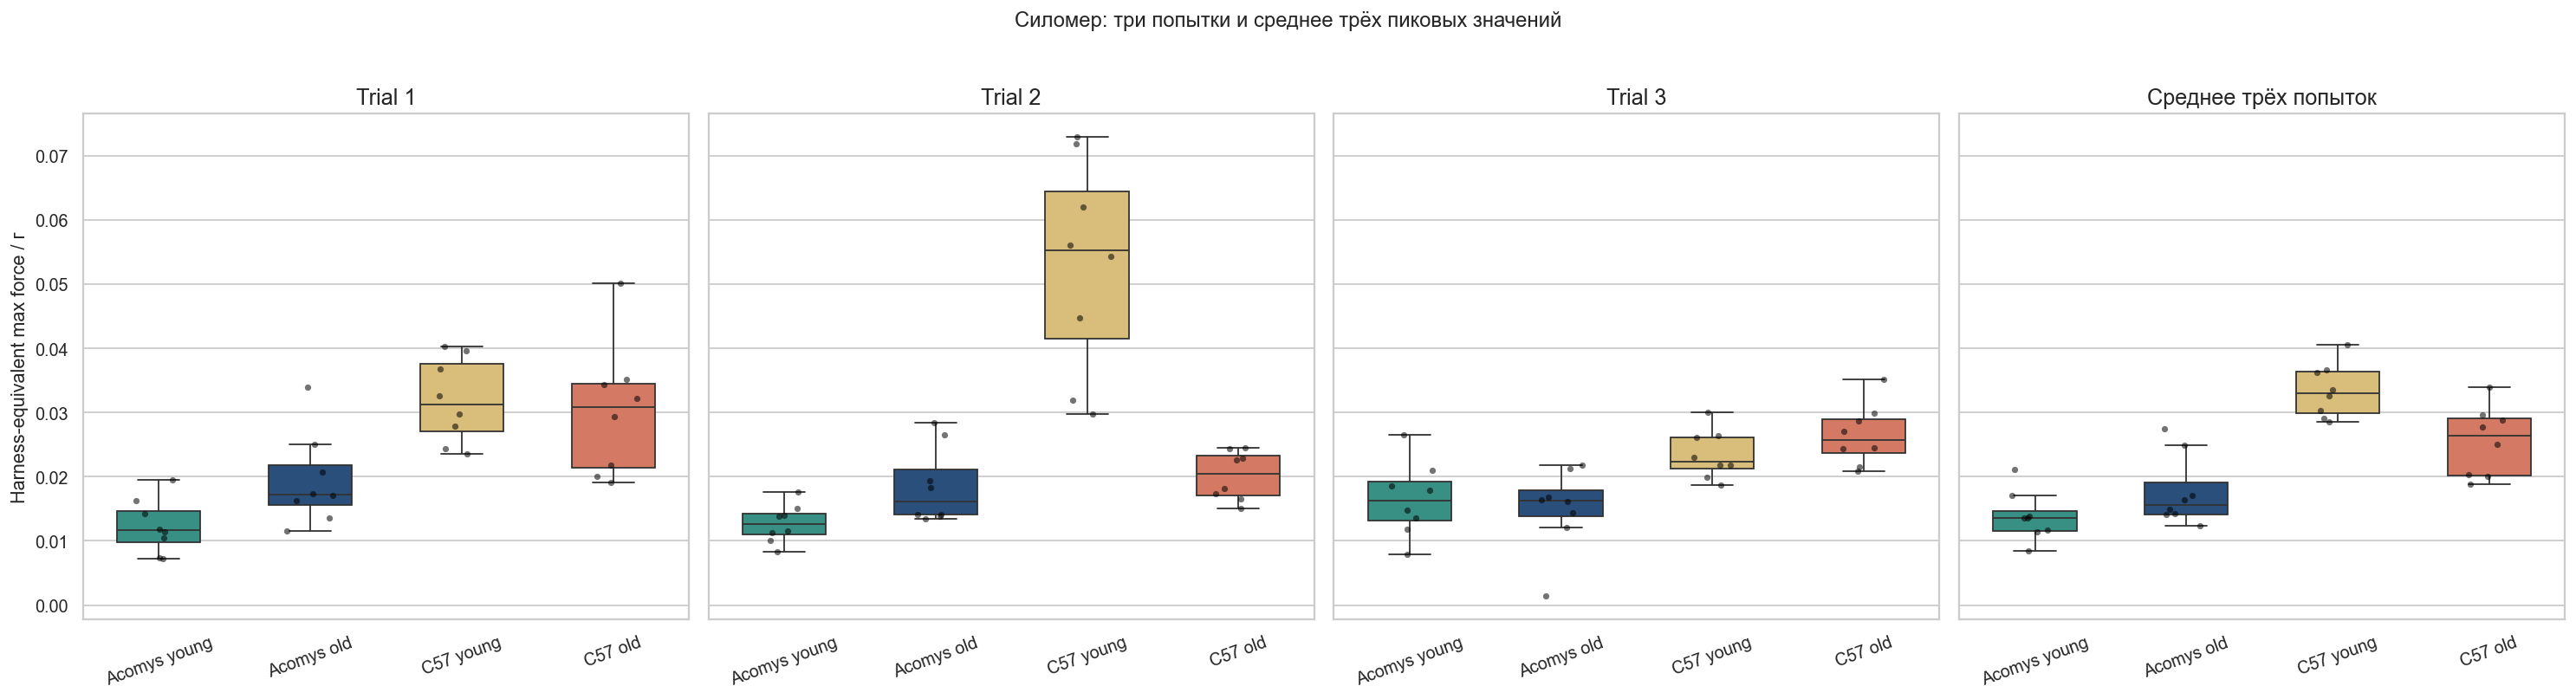

In [16]:
calibration_factors = paired_protocol_summary.set_index(['age', 'endpoint'])['calibration_factor_harness_to_tail'].to_dict()

grip_c57_harness_equivalent = grip_endpoints[(grip_endpoints['species'] == 'C57') & (grip_endpoints['protocol'] == 'tail')].copy()
grip_acomys_harness = grip_endpoints[(grip_endpoints['species'] == 'Acomys') & (grip_endpoints['protocol'] == 'harness')].copy()
grip_c57_harness_equivalent['max_force_per_g_harness_equivalent'] = [
    value * calibration_factors[(age, endpoint)]
    for value, age, endpoint in zip(
        grip_c57_harness_equivalent['max_force_per_g'],
        grip_c57_harness_equivalent['age'],
        grip_c57_harness_equivalent['endpoint'],
    )
]
grip_acomys_harness['max_force_per_g_harness_equivalent'] = grip_acomys_harness['max_force_per_g']

primary_columns = ['species', 'age', 'group', 'animal_id', 'weight_g', 'endpoint', 'max_force_per_g_harness_equivalent']
grip_primary = pd.concat([grip_acomys_harness[primary_columns], grip_c57_harness_equivalent[primary_columns]], ignore_index=True)
grip_primary['measurement_scale'] = 'harness_equivalent_force_per_g'
grip_primary.to_csv(RESULTS_DIR / 'grip_primary_harness_equivalent_endpoints.csv', index=False)

fig, axes = plt.subplots(1, 4, figsize=(23, 6), sharey=True)
for axis, endpoint in zip(axes, GRIP_ENDPOINT_ORDER):
    endpoint_data = grip_primary[grip_primary['endpoint'] == endpoint]
    plot_box_strip(endpoint_data, 'max_force_per_g_harness_equivalent', 'Harness-equivalent max force / г', GRIP_ENDPOINT_LABELS[endpoint], axis)
fig.suptitle('Силомер: три попытки и среднее трёх пиковых значений', y=1.03)
fig.tight_layout()
plt.show()


In [17]:
grip_primary_metric_titles = {
    'max_force_per_g_harness_equivalent': 'Силомер: максимальная сила / г, harness-equivalent',
}
grip_test_rows = []
for endpoint in GRIP_ENDPOINT_ORDER:
    endpoint_data = grip_primary[grip_primary['endpoint'] == endpoint]
    for metric, metric_title in grip_primary_metric_titles.items():
        for contrast, contrast_title, group_a, group_b in PLANNED_CONTRASTS:
            values_a = endpoint_data.loc[endpoint_data['group'] == group_a, metric].dropna()
            values_b = endpoint_data.loc[endpoint_data['group'] == group_b, metric].dropna()
            test = stats.mannwhitneyu(values_a, values_b, alternative='two-sided') if len(values_a) >= 2 and len(values_b) >= 2 else None
            grip_test_rows.append({
                'family': 'grip_harness_equivalent_by_endpoint',
                'endpoint': endpoint, 'endpoint_title': GRIP_ENDPOINT_LABELS[endpoint],
                'metric': metric, 'metric_title': metric_title,
                'contrast': contrast, 'contrast_title': contrast_title,
                'group_a': group_a, 'group_b': group_b, 'n_a': len(values_a), 'n_b': len(values_b),
                'median_a': values_a.median() if len(values_a) else np.nan,
                'median_b': values_b.median() if len(values_b) else np.nan,
                'cliffs_delta_a_minus_b': cliffs_delta(values_a, values_b),
                'u_statistic': test.statistic if test is not None else np.nan,
                'p_value': test.pvalue if test is not None else np.nan,
            })
grip_primary_tests = pd.DataFrame(grip_test_rows)
grip_primary_tests['q_value'] = bh_q(grip_primary_tests['p_value'])
grip_primary_tests = grip_primary_tests.sort_values(['q_value', 'p_value', 'endpoint']).reset_index(drop=True)
grip_primary_tests.to_csv(RESULTS_DIR / 'grip_primary_planned_tests_by_endpoint.csv', index=False)
display(grip_primary_tests.head(24))

best_grip = grip_primary_tests.iloc[0]
factor_min = paired_protocol_summary['calibration_factor_harness_to_tail'].min()
factor_max = paired_protocol_summary['calibration_factor_harness_to_tail'].max()
grip_conclusion = f"**Вывод по силомеру.** Анализируются `Maxvalue` трёх попыток и среднее трёх `Maxvalue`; все четыре показателя нормированы на массу тела. Коэффициент `шлейка / хвост` рассчитан отдельно для возраста и показателя по двум парным C57; диапазон восьми коэффициентов {factor_min:.2f}-{factor_max:.2f}. В основном анализе используются только harness-equivalent значения на грамм. Самый сильный контраст: {best_grip['endpoint_title']}, {best_grip['metric_title']} ({best_grip['contrast_title']}), p={best_grip['p_value']:.3g}, q={best_grip['q_value']:.3g}. В каждой возрастной группе калибровка основана только на двух животных и остаётся предварительной."
display(Markdown(grip_conclusion))


,family,endpoint,endpoint_title,metric,metric_title,contrast,contrast_title,group_a,group_b,n_a,n_b,median_a,median_b,cliffs_delta_a_minus_b,u_statistic,p_value,q_value
0,grip_harness_equivalent_by_endpoint,mean,Среднее трёх попыток,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.013540,0.033021,-1.00000,0.0,0.000155,0.000622
1,grip_harness_equivalent_by_endpoint,trial_1,Trial 1,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.011646,0.031182,-1.00000,0.0,0.000155,0.000622
2,grip_harness_equivalent_by_endpoint,trial_2,Trial 2,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",age_within_C57,возраст внутри C57,C57 young,C57 old,8,8,0.055209,0.020398,1.00000,64.0,0.000155,0.000622
3,grip_harness_equivalent_by_endpoint,trial_2,Trial 2,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.012681,0.055209,-1.00000,0.0,0.000155,0.000622
4,grip_harness_equivalent_by_endpoint,trial_3,Trial 3,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,0.016264,0.025752,-0.90625,3.0,0.001088,0.003481
5,grip_harness_equivalent_by_endpoint,mean,Среднее трёх попыток,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,0.015645,0.026395,-0.78125,7.0,0.006993,0.018648
6,grip_harness_equivalent_by_endpoint,mean,Среднее трёх попыток,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",age_within_C57,возраст внутри C57,C57 young,C57 old,8,8,0.033021,0.026395,0.75000,56.0,0.010412,0.023798
7,grip_harness_equivalent_by_endpoint,trial_3,Trial 3,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.016301,0.022371,-0.71875,9.0,0.014763,0.029526
8,grip_harness_equivalent_by_endpoint,trial_1,Trial 1,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",age_within_Acomys,возраст внутри Acomys,Acomys young,Acomys old,8,8,0.011646,0.017191,-0.68750,10.0,0.020668,0.033069
9,grip_harness_equivalent_by_endpoint,trial_1,Trial 1,max_force_per_g_harness_equivalent,"Силомер: максимальная сила / г, harness-equivalent",species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,0.017191,0.030778,-0.68750,10.0,0.020668,0.033069


**Вывод по силомеру.** Анализируются `Maxvalue` трёх попыток и среднее трёх `Maxvalue`; все четыре показателя нормированы на массу тела. Коэффициент `шлейка / хвост` рассчитан отдельно для возраста и показателя по двум парным C57; диапазон восьми коэффициентов 0.44-1.03. В основном анализе используются только harness-equivalent значения на грамм. Самый сильный контраст: Среднее трёх попыток, Силомер: максимальная сила / г, harness-equivalent (вид/линия у молодых), p=0.000155, q=0.000622. В каждой возрастной группе калибровка основана только на двух животных и остаётся предварительной.

## Кровоток: расчёт CWT по исходным EDR-записям

Все используемые ниже признаки кровотока рассчитываются в этом ноутбуке непосредственно из `Ch.1` каждого EDR-файла. Сигнал ресемплируется с 1000 до 25 Гц методом полифазной фильтрации. Для CWT используется относительный сигнал `(Ch.1 − медиана) / медиана`; дополнительный анализ формы использует относительный сигнал после удаления медленного тренда центрированной скользящей медианой с окном 180 секунд.

Непрерывное вейвлет-преобразование, или CWT, выполняется комплексным вейвлетом Морле `cmor1.5-1.0` на 160 логарифмически расположенных частотах от 0,005 до 10 Гц. Квадрат модуля коэффициента CWT интерпретируется как мощность на соответствующей частоте и в соответствующий момент времени. По каждому животному рассчитываются глобальный спектр и показатели заранее заданных физиологических полос.

Перед CWT размечаются резкие отрицательные провалы. Эта маска используется только для контроля качества: размеченные точки не заменяются, не исключаются и входят в расчёт CWT без изменений. Остальные каналы не используются как физиологический сигнал: они выглядят как отключённые входы с константой и шумом.

Плановые попарные сравнения выполняются двусторонним критерием Манна—Уитни; единица наблюдения — запись одного животного. FDR контролируется методом Benjamini—Hochberg одновременно по всем 112 тестам (`4 метрики × 7 полос × 4 контраста`). Для факторного анализа `log10(mean power)` используется обычная линейная модель `value ~ species * age` и ANOVA типа II с F-критерием; Benjamini—Hochberg применяется отдельно к 21 эффекту (`7 полос × species/age/species:age`). `cliffs_delta_a_minus_b` в попарной таблице положительна, когда значения группы A в целом выше группы B, и отрицательна при обратном направлении.


In [18]:
BLOOD_FLOW_CHANNEL = 1
WAVELET_NAME = 'cmor1.5-1.0'
TARGET_FS_HZ = 25.0
CWT_MIN_FREQUENCY_HZ = 0.005
CWT_MAX_FREQUENCY_HZ = 10.0
CWT_FREQUENCY_COUNT = 160
DETREND_WINDOW_SECONDS = 180
ARTIFACT_REFERENCE_WINDOW_SECONDS = 31
ARTIFACT_DROP_FRACTION_OF_BASELINE = 0.10
ARTIFACT_DROP_MAD_THRESHOLD = 8
ARTIFACT_MARGIN_SECONDS = 2
EPSILON = np.finfo(float).eps

frequency_bands = pd.DataFrame([
    {'band_order': 1, 'band': 'endothelial_NO_independent', 'band_title': 'эндотелиальная NO-независимая', 'f_min_hz': 0.0050, 'f_max_hz': 0.0095, 'band_kind': 'physiology'},
    {'band_order': 2, 'band': 'endothelial_NO_dependent', 'band_title': 'эндотелиальная NO-зависимая', 'f_min_hz': 0.0095, 'f_max_hz': 0.0400, 'band_kind': 'physiology'},
    {'band_order': 3, 'band': 'neurogenic', 'band_title': 'нейрогенная', 'f_min_hz': 0.0400, 'f_max_hz': 0.1500, 'band_kind': 'physiology'},
    {'band_order': 4, 'band': 'myogenic', 'band_title': 'миогенная', 'f_min_hz': 0.1500, 'f_max_hz': 0.4000, 'band_kind': 'physiology'},
    {'band_order': 5, 'band': 'respiratory', 'band_title': 'дыхательная', 'f_min_hz': 0.4000, 'f_max_hz': 2.0000, 'band_kind': 'physiology'},
    {'band_order': 6, 'band': 'cardiac', 'band_title': 'сердечная 2-5 Гц', 'f_min_hz': 2.0000, 'f_max_hz': 5.0000, 'band_kind': 'physiology'},
    {'band_order': 7, 'band': 'high_frequency_5_10', 'band_title': 'контроль 5-10 Гц', 'f_min_hz': 5.0000, 'f_max_hz': 10.0000, 'band_kind': 'control'},
])
frequency_grid_hz = np.geomspace(CWT_MIN_FREQUENCY_HZ, CWT_MAX_FREQUENCY_HZ, CWT_FREQUENCY_COUNT)


def parse_file_metadata(path):
    '''Извлекает группу, возраст, номер животного и массу из пути к EDR-файлу.'''
    folder = path.parent.name
    file_name = path.name
    folder_lower = folder.lower()
    species = 'Acomys' if 'acomys' in folder_lower else 'C57' if 'c57' in folder_lower else 'unknown'
    age = 'young' if 'young' in folder_lower else 'old' if 'old' in folder_lower else 'unknown'
    animal_match = re.search(r'(?:Acomys\s+(?:young|old)|black)\s+(\d+)', file_name, flags=re.IGNORECASE)
    weight_match = re.search(r'(\d+)g', file_name, flags=re.IGNORECASE)
    return {
        'path': path,
        'relative_path': str(path.relative_to(BLOOD_FLOW_DATA_ROOT)),
        'file_name': file_name,
        'folder': folder,
        'species': species,
        'age': age,
        'group': f'{species} {age}',
        'animal_id': int(animal_match.group(1)) if animal_match else pd.NA,
        'weight_g': int(weight_match.group(1)) if weight_match else pd.NA,
        'file_size_mb': path.stat().st_size / 1024**2,
    }


blood_edr_paths = sorted(BLOOD_FLOW_DATA_ROOT.rglob('*.EDR'))
if not blood_edr_paths:
    raise FileNotFoundError(f'В папке не найдены EDR-файлы: {BLOOD_FLOW_DATA_ROOT}')

blood_file_table = pd.DataFrame([parse_file_metadata(path) for path in blood_edr_paths])
blood_file_table['group'] = pd.Categorical(blood_file_table['group'], categories=GROUP_ORDER, ordered=True)
blood_file_table = blood_file_table.sort_values(['group', 'animal_id', 'file_name']).reset_index(drop=True)

observed_blood_counts = blood_file_table.groupby('group', observed=False).size().reindex(GROUP_ORDER, fill_value=0)
if len(blood_file_table) != 32 or not (observed_blood_counts == 8).all():
    warnings.warn(f'Ожидались 32 EDR-файла, по 8 на группу; найдено: {observed_blood_counts.to_dict()}')


In [19]:
def safe_log10(values):
    """Считает log10 с защитой от нулей."""
    return np.log10(np.asarray(values, dtype=float) + EPSILON)


def ensure_odd(value):
    """Возвращает нечётное целое окно для центрированного rolling median."""
    integer_value = max(int(round(value)), 3)
    return integer_value + 1 if integer_value % 2 == 0 else integer_value


def robust_mad(values):
    """Возвращает робастную оценку стандартного отклонения через MAD."""
    values = np.asarray(values, dtype=float)
    median_value = np.nanmedian(values)
    return 1.4826 * np.nanmedian(np.abs(values - median_value))


def public_metadata(metadata):
    """Убирает объект Path из метаданных перед сохранением в таблицы."""
    return {key: value for key, value in metadata.items() if key != "path"}


def load_blood_flow_signal(path):
    """Загружает канал кровотока Ch.1 из EDR-файла через Neo."""
    reader = WinEdrIO(filename=str(path))
    signal_proxy = reader.read_segment(lazy=True).analogsignals[0]
    blood_flow_signal = signal_proxy.load(channel_indexes=[BLOOD_FLOW_CHANNEL])
    values = blood_flow_signal[:, 0].magnitude.reshape(-1).astype(float)
    fs_hz = float(blood_flow_signal.sampling_rate.rescale("Hz").magnitude)
    return values, fs_hz, signal_proxy.shape


def dilate_boolean_mask(mask, radius_points):
    """Расширяет булеву маску на заданный радиус по времени."""
    mask = np.asarray(mask, dtype=bool)
    radius_points = int(round(radius_points))
    if radius_points <= 0 or not mask.any():
        return mask.copy()
    kernel = np.ones(2 * radius_points + 1, dtype=int)
    return np.convolve(mask.astype(int), kernel, mode="same") > 0


def summarize_boolean_segments(mask, fs_hz):
    """Возвращает число сегментов маски и длительность самого длинного сегмента."""
    mask = np.asarray(mask, dtype=bool)
    if not mask.any():
        return 0, 0.0
    padded = np.concatenate([[False], mask, [False]])
    edges = np.flatnonzero(padded[1:] != padded[:-1])
    lengths = edges[1::2] - edges[::2]
    return int(lengths.size), float(lengths.max() / fs_hz)


def detect_blood_flow_artifacts(downsampled, fs_hz):
    """Размечает резкие отрицательные провалы Ch.1 на ресемплированном сигнале."""
    reference_window_points = ensure_odd(ARTIFACT_REFERENCE_WINDOW_SECONDS * fs_hz)
    local_reference = (
        pd.Series(downsampled)
        .rolling(window=reference_window_points, center=True, min_periods=max(reference_window_points // 4, 3))
        .median()
        .interpolate(limit_direction="both")
        .to_numpy()
    )
    residual = downsampled - local_reference
    residual_scale_mV = robust_mad(residual)
    baseline_mV = max(abs(np.nanmedian(downsampled)), EPSILON)
    drop_threshold_mV = max(
        ARTIFACT_DROP_MAD_THRESHOLD * residual_scale_mV,
        ARTIFACT_DROP_FRACTION_OF_BASELINE * baseline_mV,
    )
    core_mask = residual < -drop_threshold_mV
    artifact_mask = dilate_boolean_mask(core_mask, ARTIFACT_MARGIN_SECONDS * fs_hz)
    core_segments, max_core_segment_s = summarize_boolean_segments(core_mask, fs_hz)
    artifact_segments, max_artifact_segment_s = summarize_boolean_segments(artifact_mask, fs_hz)

    return {
        "artifact_reference": local_reference,
        "artifact_residual": residual,
        "artifact_core_mask": core_mask,
        "artifact_mask": artifact_mask,
        "artifact_core_fraction": float(core_mask.mean()),
        "artifact_mask_fraction": float(artifact_mask.mean()),
        "artifact_core_segments": core_segments,
        "artifact_segments": artifact_segments,
        "max_core_segment_s": max_core_segment_s,
        "max_artifact_segment_s": max_artifact_segment_s,
        "artifact_drop_threshold_mV": float(drop_threshold_mV),
        "artifact_residual_scale_mV": float(residual_scale_mV),
        "artifact_min_residual_mV": float(np.nanmin(residual)),
    }


def prepare_blood_flow(values, fs_hz):
    """Ресемплирует сигнал без очистки и строит варианты для CWT и анализа формы."""
    downsample_factor = max(int(round(fs_hz / TARGET_FS_HZ)), 1)
    analysis_fs_hz = fs_hz / downsample_factor

    if downsample_factor > 1:
        raw_downsampled = signal.resample_poly(values, up=1, down=downsample_factor, padtype="line")
    else:
        raw_downsampled = values.copy()

    artifact_info = detect_blood_flow_artifacts(raw_downsampled, analysis_fs_hz)
    downsampled = raw_downsampled

    time_s = np.arange(downsampled.size) / analysis_fs_hz
    baseline_median = np.nanmedian(downsampled)
    relative_centered = (downsampled - baseline_median) / baseline_median

    trend_window_points = ensure_odd(DETREND_WINDOW_SECONDS * analysis_fs_hz)
    trend = (
        pd.Series(downsampled)
        .rolling(window=trend_window_points, center=True, min_periods=max(trend_window_points // 4, 3))
        .median()
        .interpolate(limit_direction="both")
        .to_numpy()
    )
    relative_detrended = (downsampled - trend) / trend
    relative_detrended = relative_detrended - np.nanmedian(relative_detrended)

    return {
        "downsample_factor": downsample_factor,
        "analysis_fs_hz": analysis_fs_hz,
        "raw_downsampled": raw_downsampled,
        "downsampled": downsampled,
        "time_s": time_s,
        "trend": trend,
        "relative_centered": relative_centered,
        "relative_detrended": relative_detrended,
        "trend_window_points": trend_window_points,
        **artifact_info,
    }


In [20]:
def summarize_signal(metadata, values, fs_hz, signal_shape, prepared):
    """Считает базовые QC-признаки исходного и анализируемого канала кровотока."""
    duration_s = values.size / fs_hz
    first_minute_count = min(int(round(60 * fs_hz)), values.size)
    last_minute_count = min(int(round(60 * fs_hz)), values.size)
    first_median = np.nanmedian(values[:first_minute_count])
    last_median = np.nanmedian(values[-last_minute_count:])
    diff_values = np.diff(values)
    diff_mad = robust_mad(diff_values)
    diff_threshold = np.nanmedian(np.abs(diff_values)) + 8 * diff_mad
    spike_fraction = float(np.nanmean(np.abs(diff_values) > diff_threshold)) if diff_threshold > 0 else 0.0
    same_sample = np.abs(diff_values) < 1e-9
    flat_fraction = float(np.nanmean(same_sample))
    if same_sample.any():
        padded = np.concatenate([[False], same_sample, [False]])
        run_edges = np.flatnonzero(padded[1:] != padded[:-1])
        flat_run_lengths = run_edges[1::2] - run_edges[::2]
        max_flat_run_s = float(flat_run_lengths.max() / fs_hz)
    else:
        max_flat_run_s = 0.0
    median_value = np.nanmedian(values)
    analysis_median_value = np.nanmedian(prepared["downsampled"])
    std_value = np.nanstd(values)
    analysis_std_value = np.nanstd(prepared["downsampled"])
    drift_mV = last_median - first_median
    drift_percent = 100 * drift_mV / median_value

    quality_notes = []
    if duration_s < 14 * 60 or duration_s > 16 * 60:
        quality_notes.append("duration")
    if abs(drift_percent) > 8:
        quality_notes.append("drift")
    if spike_fraction > 0.01:
        quality_notes.append("spikes")
    if max_flat_run_s > 2:
        quality_notes.append("flat")

    return {
        **public_metadata(metadata),
        "neo_shape": str(signal_shape),
        "original_samples": int(values.size),
        "original_fs_hz": float(fs_hz),
        "duration_min": duration_s / 60,
        "downsample_factor": prepared["downsample_factor"],
        "analysis_fs_hz": prepared["analysis_fs_hz"],
        "analysis_samples": int(prepared["downsampled"].size),
        "trend_window_points": prepared["trend_window_points"],
        "mean_mV": float(np.nanmean(values)),
        "median_mV": float(median_value),
        "std_mV": float(std_value),
        "mad_mV": float(robust_mad(values)),
        "cv": float(std_value / np.nanmean(values)),
        "iqr_mV": float(np.nanpercentile(values, 75) - np.nanpercentile(values, 25)),
        "min_mV": float(np.nanmin(values)),
        "max_mV": float(np.nanmax(values)),
        "analysis_median_mV": float(analysis_median_value),
        "analysis_std_mV": float(analysis_std_value),
        "analysis_cv": float(analysis_std_value / np.nanmean(prepared["downsampled"])),
        "first_minute_median_mV": float(first_median),
        "last_minute_median_mV": float(last_median),
        "drift_mV": float(drift_mV),
        "drift_percent_of_median": float(drift_percent),
        "spike_fraction": spike_fraction,
        "flat_fraction": flat_fraction,
        "max_flat_run_s": max_flat_run_s,
        "artifact_core_fraction": prepared["artifact_core_fraction"],
        "artifact_mask_fraction": prepared["artifact_mask_fraction"],
        "artifact_segments": prepared["artifact_segments"],
        "max_artifact_segment_s": prepared["max_artifact_segment_s"],
        "artifact_drop_threshold_mV": prepared["artifact_drop_threshold_mV"],
        "artifact_residual_scale_mV": prepared["artifact_residual_scale_mV"],
        "artifact_min_residual_mV": prepared["artifact_min_residual_mV"],
        "artifact_action": "flag_only" if prepared["artifact_mask_fraction"] > 0 else "none",
        "quality_flag": "ok" if not quality_notes else ", ".join(quality_notes),
    }


def compute_cwt_power(signal_values, fs_hz):
    '''Считает CWT и возвращает частоты и мощность коэффициентов.'''
    scales = pywt.frequency2scale(WAVELET_NAME, frequency_grid_hz / fs_hz)
    coefficients, frequencies_hz = pywt.cwt(
        signal_values,
        scales,
        WAVELET_NAME,
        sampling_period=1 / fs_hz,
        method='fft',
    )
    return frequencies_hz, np.abs(coefficients) ** 2


def band_mask(frequencies_hz, band_row):
    '''Возвращает маску частот для заданной полосы.'''
    is_last_band = band_row.band_order == frequency_bands['band_order'].max()
    if is_last_band:
        return (frequencies_hz >= band_row.f_min_hz) & (frequencies_hz <= band_row.f_max_hz)
    return (frequencies_hz >= band_row.f_min_hz) & (frequencies_hz < band_row.f_max_hz)


def summarize_wavelet_metrics(metadata, frequencies_hz, power, time_s):
    '''Сводит CWT к глобальному спектру и показателям частотных полос.'''
    meta = public_metadata(metadata)
    total_mask = np.zeros_like(frequencies_hz, dtype=bool)
    for band_row in frequency_bands.itertuples(index=False):
        total_mask |= band_mask(frequencies_hz, band_row)
    total_integrated_power_ts = np.nansum(power[total_mask], axis=0)

    global_power = np.nanmean(power, axis=1)
    spectrum_rows = [
        {
            **meta,
            'frequency_hz': float(frequency_hz),
            'global_mean_power': float(mean_power),
            'log10_global_mean_power': float(safe_log10(mean_power)),
        }
        for frequency_hz, mean_power in zip(frequencies_hz, global_power)
    ]

    band_rows = []
    for band_row in frequency_bands.itertuples(index=False):
        mask = band_mask(frequencies_hz, band_row)
        band_frequencies = frequencies_hz[mask]
        band_power = power[mask]
        band_power_ts = np.nanmean(band_power, axis=0)
        integrated_band_power_ts = np.nansum(band_power, axis=0)
        integrated_share_ts = np.divide(
            integrated_band_power_ts,
            total_integrated_power_ts,
            out=np.full_like(integrated_band_power_ts, np.nan, dtype=float),
            where=total_integrated_power_ts > 0,
        )
        band_global_power = np.nanmean(band_power, axis=1)
        mean_power = float(np.nanmean(band_power_ts))
        first_window = time_s <= min(5 * 60, time_s[-1])
        last_window = time_s >= max(time_s[-1] - 5 * 60, 0)
        early_mean_power = float(np.nanmean(band_power_ts[first_window]))
        late_mean_power = float(np.nanmean(band_power_ts[last_window]))
        peak_index = int(np.nanargmax(band_global_power))
        spectral_weight_sum = np.nansum(band_global_power)
        band_rows.append({
            **meta,
            'band_order': int(band_row.band_order),
            'band': band_row.band,
            'band_title': band_row.band_title,
            'band_kind': band_row.band_kind,
            'f_min_hz': float(band_row.f_min_hz),
            'f_max_hz': float(band_row.f_max_hz),
            'frequencies_in_band': int(mask.sum()),
            'mean_power': mean_power,
            'median_power': float(np.nanmedian(band_power_ts)),
            'integrated_power': float(np.nanmean(integrated_band_power_ts)),
            'integrated_power_share': float(np.nanmean(integrated_share_ts)),
            'log10_mean_power': float(safe_log10(mean_power)),
            'log10_integrated_power': float(safe_log10(np.nanmean(integrated_band_power_ts))),
            'peak_frequency_hz': float(band_frequencies[peak_index]),
            'spectral_centroid_hz': float(np.nansum(band_frequencies * band_global_power) / spectral_weight_sum) if spectral_weight_sum > 0 else np.nan,
            'temporal_cv_power': float(np.nanstd(band_power_ts) / np.nanmean(band_power_ts)) if np.nanmean(band_power_ts) > 0 else np.nan,
            'early_5min_mean_power': early_mean_power,
            'late_5min_mean_power': late_mean_power,
            'late_to_early_power_ratio': float(late_mean_power / early_mean_power) if early_mean_power > 0 else np.nan,
            'time_of_max_power_min': float(time_s[int(np.nanargmax(band_power_ts))] / 60),
        })
    return band_rows, spectrum_rows


qc_rows = []
band_rows = []
spectrum_rows = []
blood_signal_cache = {}

for path in blood_file_table['path']:
    metadata = parse_file_metadata(path)
    values, fs_hz, signal_shape = load_blood_flow_signal(path)
    prepared = prepare_blood_flow(values, fs_hz)
    frequencies_hz, power = compute_cwt_power(prepared['relative_centered'], prepared['analysis_fs_hz'])
    qc_rows.append(summarize_signal(metadata, values, fs_hz, signal_shape, prepared))
    file_band_rows, file_spectrum_rows = summarize_wavelet_metrics(metadata, frequencies_hz, power, prepared['time_s'])
    band_rows.extend(file_band_rows)
    spectrum_rows.extend(file_spectrum_rows)
    blood_signal_cache[metadata['relative_path']] = {
        'metadata': public_metadata(metadata),
        'analysis_fs_hz': prepared['analysis_fs_hz'],
        'relative_detrended': prepared['relative_detrended'],
        'artifact_mask_fraction': prepared['artifact_mask_fraction'],
    }

blood_qc = pd.DataFrame(qc_rows)
blood_band = pd.DataFrame(band_rows)
blood_spectrum = pd.DataFrame(spectrum_rows)
for table in [blood_qc, blood_band, blood_spectrum]:
    table['group'] = pd.Categorical(table['group'], categories=GROUP_ORDER, ordered=True)

artifact_columns = [
    'relative_path', 'file_name', 'folder', 'species', 'age', 'group', 'animal_id', 'weight_g',
    'file_size_mb', 'analysis_fs_hz', 'artifact_core_fraction', 'artifact_mask_fraction',
    'artifact_segments', 'max_artifact_segment_s', 'artifact_drop_threshold_mV',
    'artifact_residual_scale_mV', 'artifact_min_residual_mV', 'artifact_action',
]
blood_artifacts = blood_qc[artifact_columns].copy()

blood_frequency_bands = frequency_bands.copy()
blood_frequency_bands['frequencies_in_grid'] = [
    int(band_mask(frequency_grid_hz, row).sum()) for row in blood_frequency_bands.itertuples(index=False)
]
blood_frequency_bands['period_at_f_min_s'] = 1 / blood_frequency_bands['f_min_hz']
blood_frequency_bands['period_at_f_max_s'] = 1 / blood_frequency_bands['f_max_hz']
blood_frequency_bands['cycles_at_f_min_in_15min'] = 15 * 60 * blood_frequency_bands['f_min_hz']
blood_frequency_bands['cycles_at_f_max_in_15min'] = 15 * 60 * blood_frequency_bands['f_max_hz']
blood_frequency_bands['rough_edge_safe_fraction'] = (
    (15 * 60 - 2 * blood_frequency_bands['period_at_f_min_s']) / (15 * 60)
).clip(lower=0)



In [21]:
blood_pairwise_metric_titles = {
    'log10_mean_power': 'log10 средней мощности',
    'integrated_power_share': 'доля интегральной мощности',
    'peak_frequency_hz': 'пиковая частота',
    'late_to_early_power_ratio': 'отношение поздняя/ранняя мощность',
}

pairwise_parts = []
for band_row in frequency_bands.itertuples(index=False):
    band_data = blood_band[blood_band['band'] == band_row.band]
    band_tests = planned_continuous_tests(
        band_data,
        list(blood_pairwise_metric_titles),
        family='blood_flow_cwt',
    )
    band_tests['metric_title'] = band_tests['metric'].map(blood_pairwise_metric_titles)
    band_tests['band_order'] = int(band_row.band_order)
    band_tests['band'] = band_row.band
    band_tests['band_title'] = band_row.band_title
    pairwise_parts.append(band_tests)

blood_pairwise_tests = pd.concat(pairwise_parts, ignore_index=True)
blood_pairwise_tests['q_value'] = bh_q(blood_pairwise_tests['p_value'])
blood_pairwise_tests = blood_pairwise_tests[[
    'metric', 'metric_title', 'contrast', 'contrast_title', 'band_order', 'band', 'band_title',
    'group_a', 'group_b', 'n_a', 'n_b', 'median_a', 'median_b', 'median_diff_a_minus_b',
    'cliffs_delta_a_minus_b', 'u_statistic', 'p_value', 'q_value',
]].sort_values(['q_value', 'p_value', 'metric', 'band_order']).reset_index(drop=True)

factor_rows = []
for band_row in frequency_bands.itertuples(index=False):
    model_data = blood_band.loc[
        (blood_band['band'] == band_row.band) & np.isfinite(blood_band['log10_mean_power']),
        ['species', 'age', 'log10_mean_power'],
    ].rename(columns={'log10_mean_power': 'value'})
    model = smf.ols('value ~ C(species) * C(age)', data=model_data).fit()
    anova_table = anova_lm(model, typ=2)
    mean_by_species = model_data.groupby('species')['value'].mean()
    mean_by_age = model_data.groupby('age')['value'].mean()
    for effect_name in ['C(species)', 'C(age)', 'C(species):C(age)']:
        factor_rows.append({
            'band_order': int(band_row.band_order),
            'band': band_row.band,
            'band_title': band_row.band_title,
            'effect': effect_name,
            'sum_sq': float(anova_table.loc[effect_name, 'sum_sq']),
            'df': float(anova_table.loc[effect_name, 'df']),
            'f_value': float(anova_table.loc[effect_name, 'F']),
            'p_value': float(anova_table.loc[effect_name, 'PR(>F)']),
            'mean_log10_Acomys_minus_C57': float(mean_by_species.get('Acomys', np.nan) - mean_by_species.get('C57', np.nan)),
            'mean_log10_old_minus_young': float(mean_by_age.get('old', np.nan) - mean_by_age.get('young', np.nan)),
            'model_r2': float(model.rsquared),
        })

blood_factor_tests = pd.DataFrame(factor_rows)
blood_factor_tests['q_value'] = bh_q(blood_factor_tests['p_value'])
blood_factor_tests = blood_factor_tests.sort_values(['q_value', 'p_value', 'band_order', 'effect']).reset_index(drop=True)

blood_file_counts = blood_band[['relative_path', 'group']].drop_duplicates().groupby('group', observed=False).size().rename('n_files').reset_index()
artifact_summary = blood_artifacts.assign(has_artifact=lambda data: data['artifact_segments'] > 0).groupby('group', observed=False).agg(
    n_files=('relative_path', 'count'),
    files_with_artifacts=('has_artifact', 'sum'),
    median_mask_fraction=('artifact_mask_fraction', 'median'),
    max_mask_fraction=('artifact_mask_fraction', 'max'),
).reset_index()
quality_summary = blood_qc.groupby(['group', 'quality_flag'], observed=False).size().rename('n').reset_index()

blood_file_counts.to_csv(RESULTS_DIR / 'blood_flow_file_counts.csv', index=False)
artifact_summary.to_csv(RESULTS_DIR / 'blood_flow_artifact_summary.csv', index=False)
quality_summary.to_csv(RESULTS_DIR / 'blood_flow_quality_summary.csv', index=False)
display(blood_file_counts)
display(artifact_summary)
display(quality_summary)
display(blood_frequency_bands)


,group,n_files
0,Acomys young,8
1,Acomys old,8
2,C57 young,8
3,C57 old,8


,group,n_files,files_with_artifacts,median_mask_fraction,max_mask_fraction
0,Acomys young,8,0,0.000000,0.000000
1,Acomys old,8,0,0.000000,0.000000
2,C57 young,8,7,0.015485,0.053766
3,C57 old,8,1,0.000000,0.009586


,group,quality_flag,n
0,Acomys young,drift,3
1,Acomys young,ok,5
2,Acomys old,drift,1
3,Acomys old,ok,7
4,C57 young,drift,1
5,C57 young,ok,7
6,C57 old,drift,1
7,C57 old,ok,7


,band_order,band,band_title,f_min_hz,f_max_hz,band_kind,frequencies_in_grid,period_at_f_min_s,period_at_f_max_s,cycles_at_f_min_in_15min,cycles_at_f_max_in_15min,rough_edge_safe_fraction
0,1,endothelial_NO_independent,эндотелиальная NO-независимая,0.0050,0.0095,physiology,14,200.000000,105.263158,4.50,8.55,0.555556
1,2,endothelial_NO_dependent,эндотелиальная NO-зависимая,0.0095,0.0400,physiology,30,105.263158,25.000000,8.55,36.00,0.766082
2,3,neurogenic,нейрогенная,0.0400,0.1500,physiology,28,25.000000,6.666667,36.00,135.00,0.944444
3,4,myogenic,миогенная,0.1500,0.4000,physiology,20,6.666667,2.500000,135.00,360.00,0.985185
4,5,respiratory,дыхательная,0.4000,2.0000,physiology,34,2.500000,0.500000,360.00,1800.00,0.994444
5,6,cardiac,сердечная 2-5 Гц,2.0000,5.0000,physiology,19,0.500000,0.200000,1800.00,4500.00,0.998889
6,7,high_frequency_5_10,контроль 5-10 Гц,5.0000,10.0000,control,15,0.200000,0.100000,4500.00,9000.00,0.999556


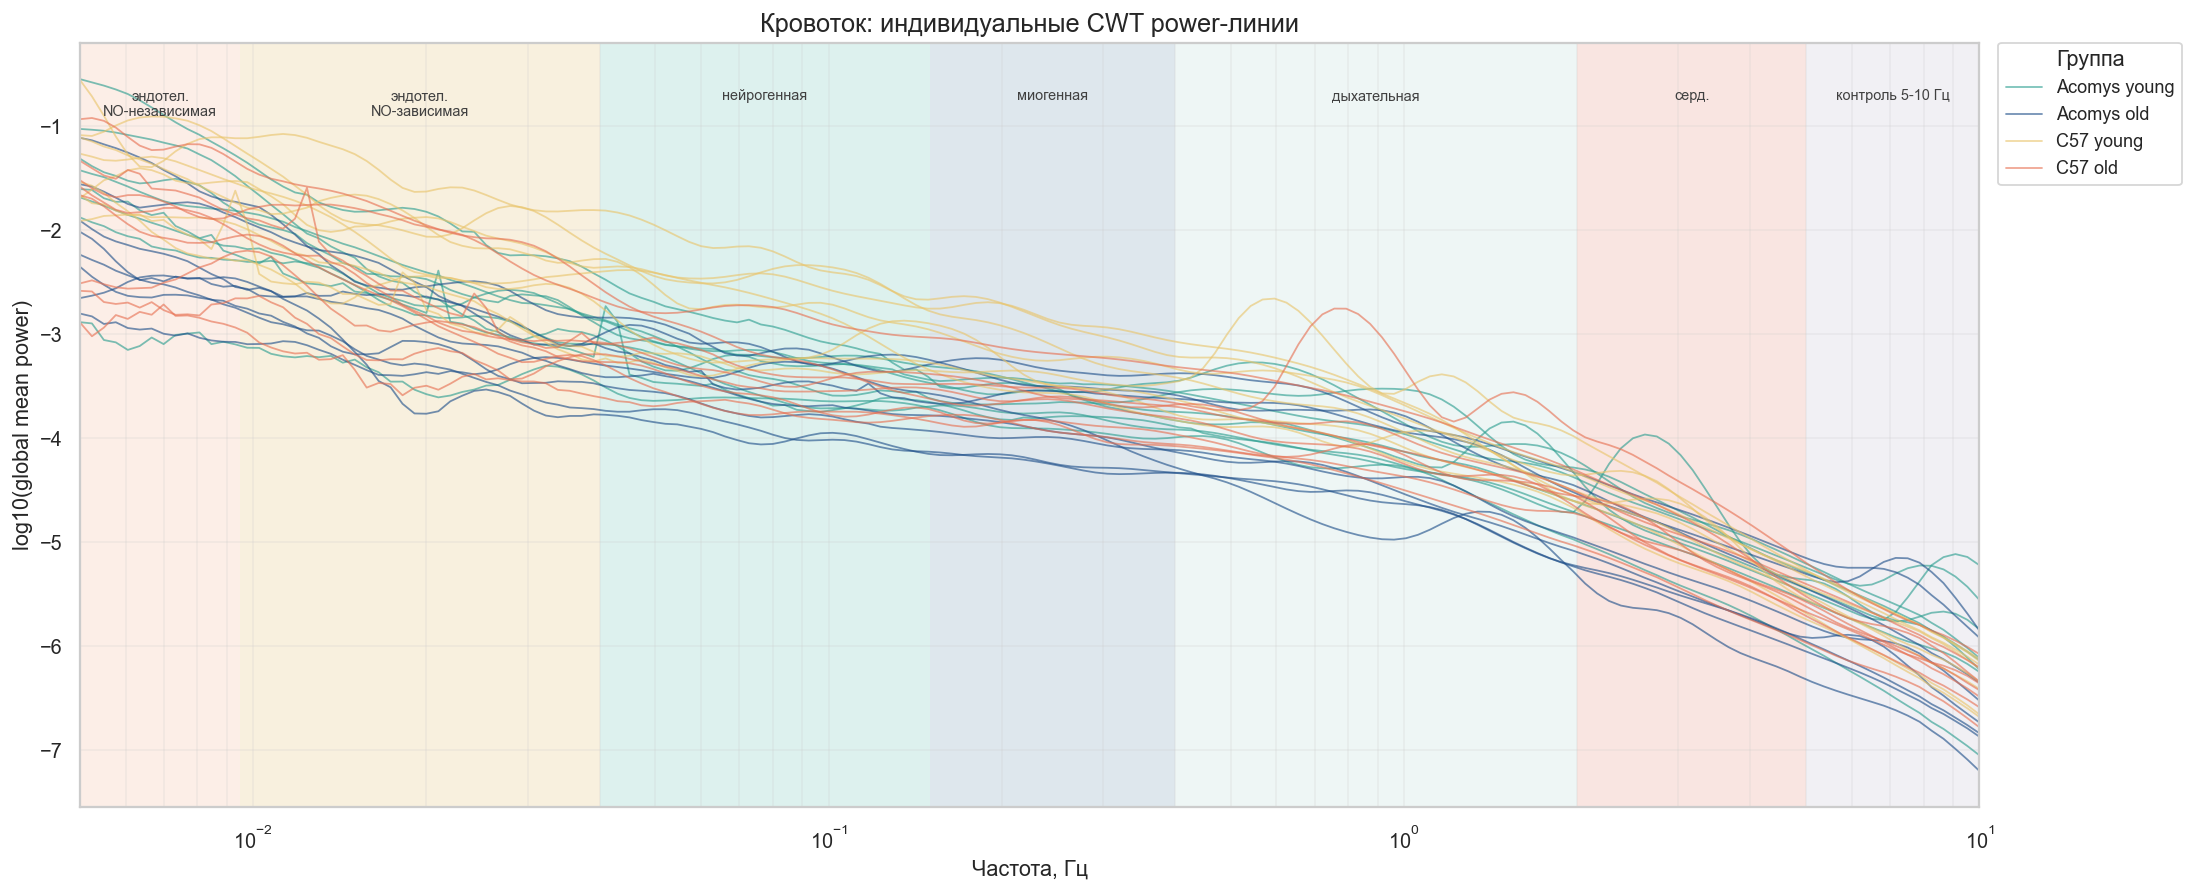

In [22]:
def add_frequency_band_background(axis, bands=blood_frequency_bands):
    colors = ['#f6cdb7', '#ead49b', '#9ad6cd', '#9bb7ca', '#cde4e1', '#efb0a4', '#d6d4de']
    y_min, y_max = axis.get_ylim()
    for idx, (_, row) in enumerate(bands.iterrows()):
        axis.axvspan(row['f_min_hz'], row['f_max_hz'], color=colors[idx % len(colors)], alpha=0.33, lw=0, zorder=0)
        label = str(row['band_title']).replace('эндотелиальная ', 'эндотел.\n').replace('сердечная 2-5 Гц', 'серд.')
        x_middle = np.sqrt(row['f_min_hz'] * row['f_max_hz'])
        axis.text(x_middle, y_max - 0.06 * (y_max - y_min), label, ha='center', va='top', fontsize=8, color='0.25')

fig, axis = plt.subplots(figsize=(17, 7))
for group in GROUP_ORDER:
    group_data = blood_spectrum[blood_spectrum['group'] == group]
    for line_index, (_, animal_data) in enumerate(group_data.groupby('relative_path', sort=False)):
        axis.plot(animal_data['frequency_hz'], animal_data['log10_global_mean_power'], color=GROUP_PALETTE[group], alpha=0.62, linewidth=1.0, label=group if line_index == 0 else None, zorder=2)
axis.set_xscale('log')
axis.set_xlabel('Частота, Гц')
axis.set_ylabel('log10(global mean power)')
axis.set_title('Кровоток: индивидуальные CWT power-линии')
axis.set_xlim(blood_spectrum['frequency_hz'].min(), blood_spectrum['frequency_hz'].max())
axis.set_ylim(blood_spectrum['log10_global_mean_power'].min() - 0.35, blood_spectrum['log10_global_mean_power'].max() + 0.35)
axis.grid(True, which='both', alpha=0.22, zorder=1)
add_frequency_band_background(axis)
axis.legend(title='Группа', loc='upper left', bbox_to_anchor=(1.01, 1.0), borderaxespad=0)
fig.tight_layout()
plt.show()


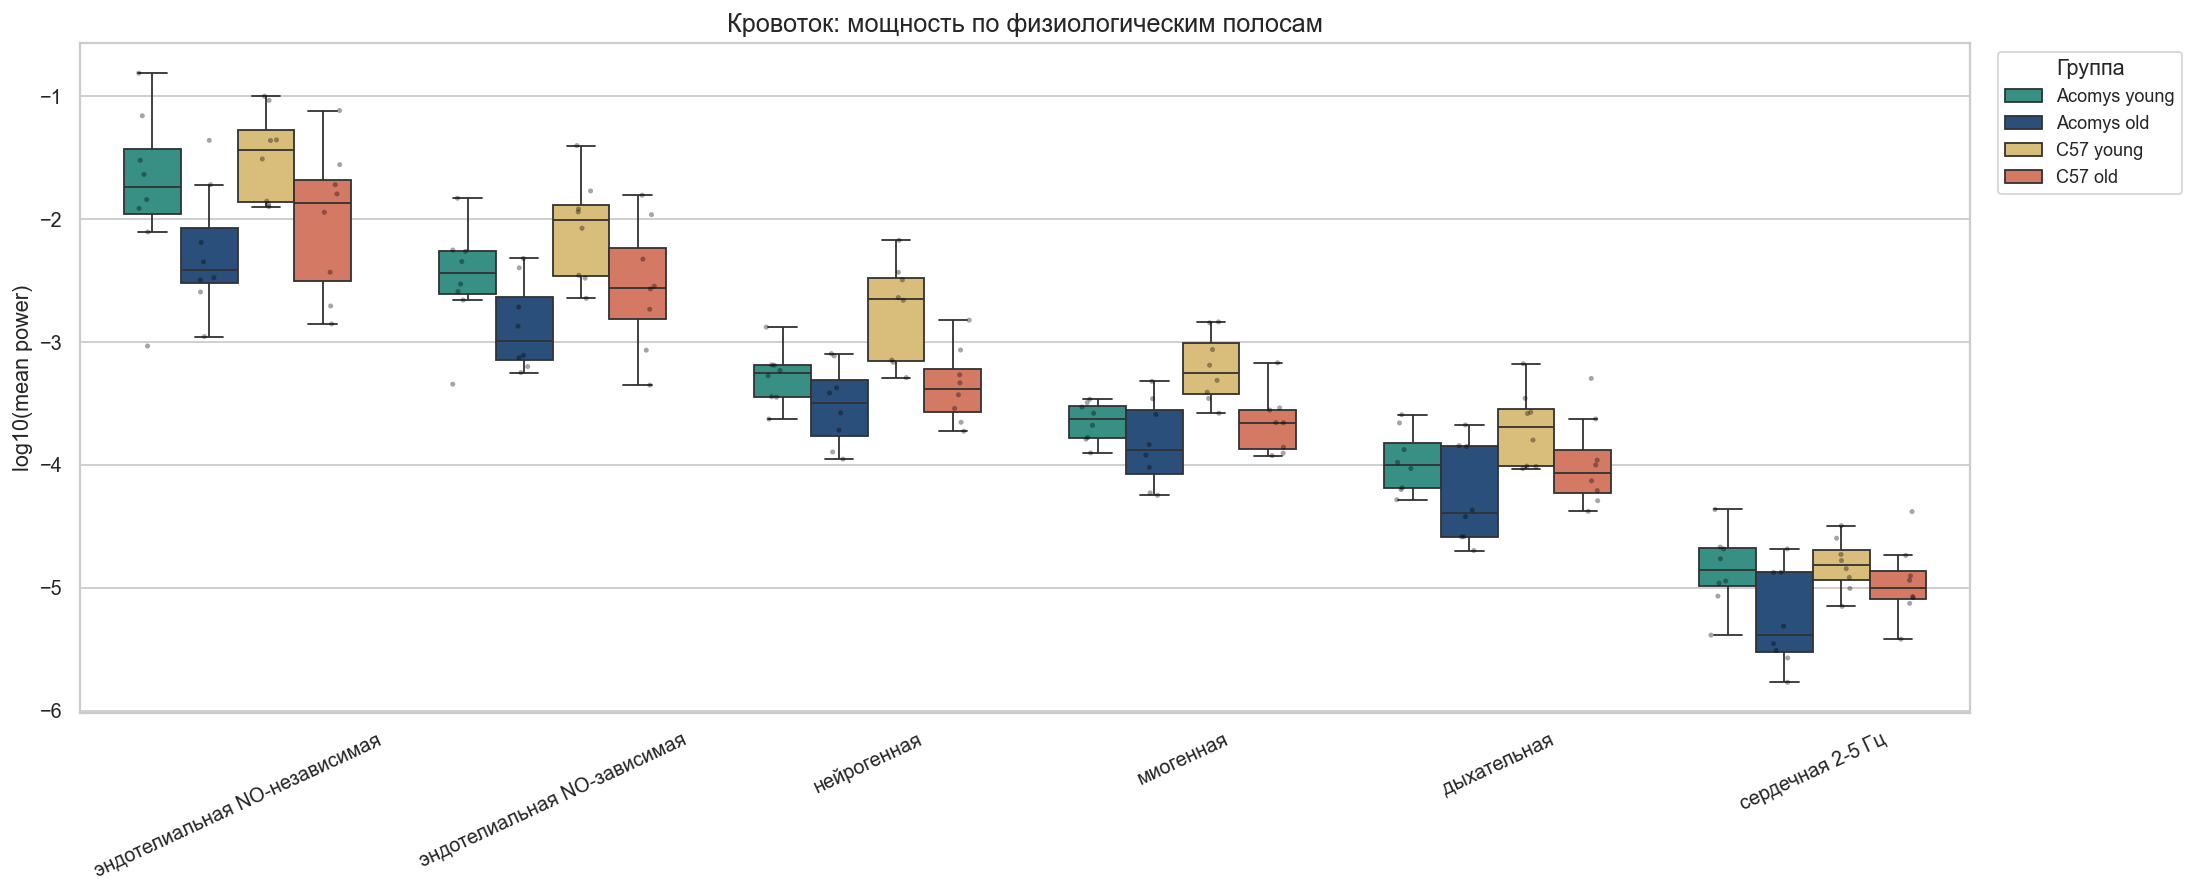

In [23]:
plot_data = blood_band[blood_band['band_kind'] == 'physiology'].copy()
plot_data['band_title'] = pd.Categorical(plot_data['band_title'], categories=blood_frequency_bands.loc[blood_frequency_bands['band_kind'] == 'physiology', 'band_title'], ordered=True)
fig, axis = plt.subplots(figsize=(17, 7))
sns.boxplot(data=plot_data, x='band_title', y='log10_mean_power', hue='group', hue_order=GROUP_ORDER, palette=GROUP_PALETTE, fliersize=0, width=0.72, ax=axis)
sns.stripplot(data=plot_data, x='band_title', y='log10_mean_power', hue='group', hue_order=GROUP_ORDER, dodge=True, palette={group: 'black' for group in GROUP_ORDER}, alpha=0.35, size=2.8, legend=False, ax=axis)
axis.set_xlabel('')
axis.set_ylabel('log10(mean power)')
axis.set_title('Кровоток: мощность по физиологическим полосам')
axis.tick_params(axis='x', rotation=25)
axis.legend(title='Группа', bbox_to_anchor=(1.01, 1), loc='upper left')
fig.tight_layout()
plt.show()


### PCA физиологических полос кровотока

PCA, или анализ главных компонент, нужен для компактного описания шести взаимосвязанных показателей `log10(mean power)`. Перед расчётом мощность каждой физиологической полосы стандартизируется по всем 32 животным: из значения вычитается среднее этой полосы и результат делится на её стандартное отклонение. Поэтому полосы с разным абсолютным масштабом вносят сопоставимый вклад.

PCA заменяет исходные полосы новыми взаимно перпендикулярными осями. `PC1` — линейная комбинация шести полос, объясняющая максимальную возможную долю различий между животными. `PC2` объясняет максимальную долю оставшихся различий и не коррелирует с `PC1`. Процент в подписи оси показывает, какая часть общей вариабельности стандартизированных признаков описана компонентой. Точка на графике — одно животное, а её координаты `PC1` и `PC2` — проекции его спектрального профиля на эти две оси.

`PC1_loading` и `PC2_loading` в таблице — веса исходных частотных полос в формулах компонент. Чем больше модуль веса, тем сильнее полоса влияет на соответствующую компоненту; одинаковые знаки означают совместное изменение полос, противоположные — их противопоставление. Общий знак компоненты математически произволен, поэтому важны относительные знаки и модули весов. PCA здесь является описательным разведочным методом: он помогает увидеть общие спектральные направления, сходство животных и возможное разделение групп, но сам по себе не проверяет статистическую значимость групповых различий.


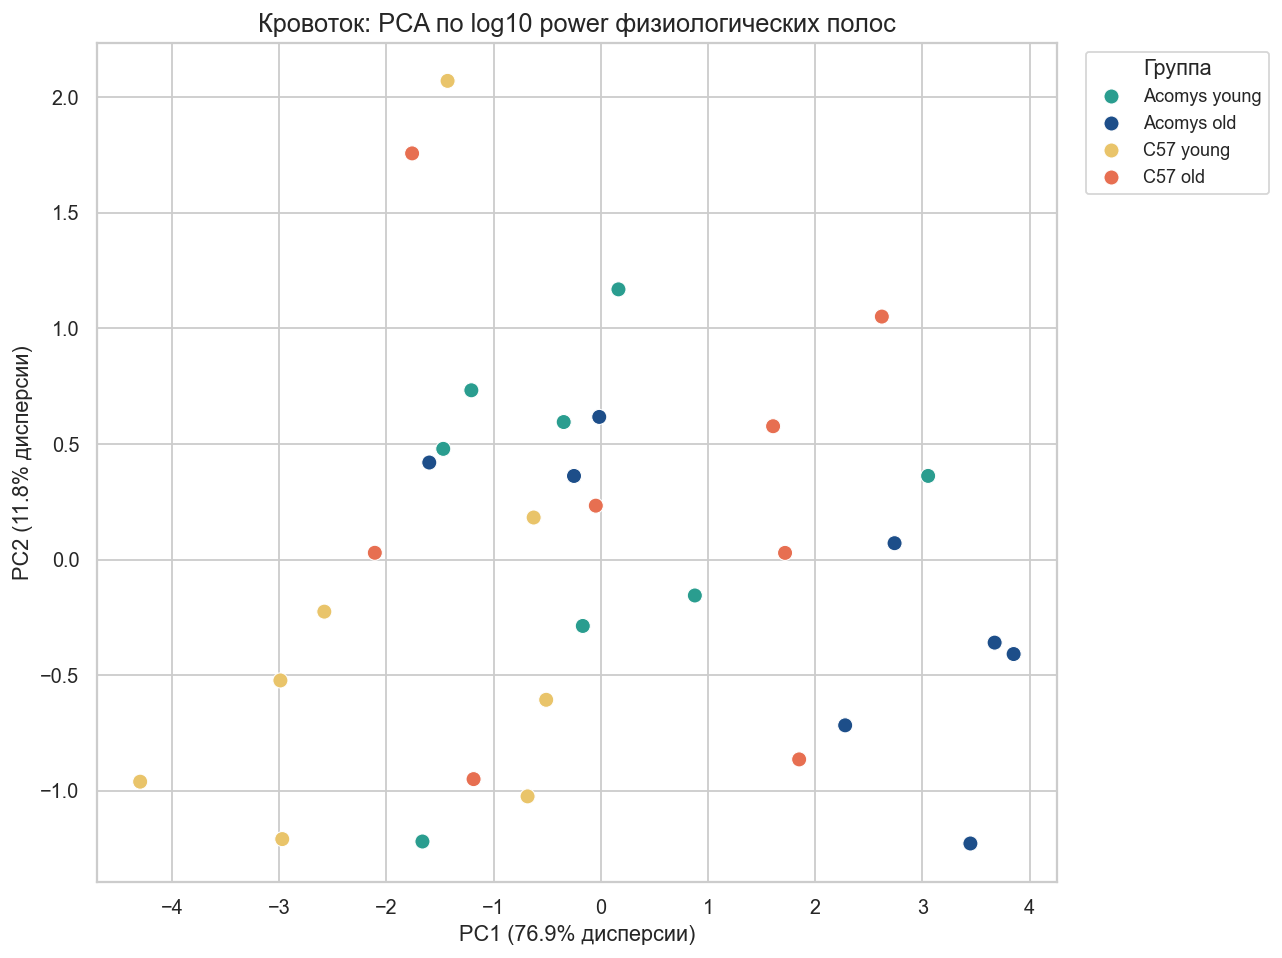

,Физиологическая полоса,Вес полосы в PC1,Вес полосы в PC2
0,сердечная 2-5 Гц,-0.370758,0.643085
1,эндотелиальная NO-зависимая,-0.427995,-0.375556
2,эндотелиальная NO-независимая,-0.404099,-0.268474
3,миогенная,-0.427655,-0.054166
4,нейрогенная,-0.411790,-0.354714
5,дыхательная,-0.404479,0.494536


In [24]:
blood_metadata_columns = ['relative_path', 'file_name', 'species', 'age', 'group', 'animal_id', 'weight_g']
blood_metadata = blood_band[blood_metadata_columns].drop_duplicates('relative_path')
blood_power_wide = blood_band[blood_band['band_kind'] == 'physiology'].pivot_table(
    index='relative_path', columns='band', values='log10_mean_power', aggfunc='first',
).reset_index().merge(blood_metadata, on='relative_path', how='left')
feature_cols = [col for col in blood_power_wide.columns if col in set(blood_band['band'])]
feature_matrix = blood_power_wide[feature_cols].to_numpy(dtype=float)
feature_matrix = (feature_matrix - np.nanmean(feature_matrix, axis=0)) / np.nanstd(feature_matrix, axis=0, ddof=1)
feature_matrix = np.nan_to_num(feature_matrix, nan=0.0)
u, s, vt = np.linalg.svd(feature_matrix, full_matrices=False)
scores = feature_matrix @ vt.T
explained = (s ** 2) / np.sum(s ** 2)

pca_scores = blood_power_wide[['relative_path', 'species', 'age', 'group', 'animal_id']].copy()
pca_scores['PC1'] = scores[:, 0]
pca_scores['PC2'] = scores[:, 1]
pca_loadings = pd.DataFrame({'band': feature_cols, 'PC1_loading': vt[0, :], 'PC2_loading': vt[1, :]})
pca_loadings['band_title'] = pca_loadings['band'].map(
    blood_frequency_bands.drop_duplicates('band').set_index('band')['band_title']
)
pca_loadings = pca_loadings[['band', 'band_title', 'PC1_loading', 'PC2_loading']]
pca_scores.to_csv(RESULTS_DIR / 'blood_flow_pca_scores.csv', index=False)
pca_loadings.to_csv(RESULTS_DIR / 'blood_flow_pca_loadings.csv', index=False)

fig, axis = plt.subplots(figsize=(10, 7.5))
sns.scatterplot(data=add_group_order(pca_scores), x='PC1', y='PC2', hue='group', hue_order=GROUP_ORDER, palette=GROUP_PALETTE, s=70, edgecolor='white', linewidth=0.6, ax=axis)
axis.set_title('Кровоток: PCA по log10 power физиологических полос')
axis.set_xlabel(f'PC1 ({explained[0] * 100:.1f}% дисперсии)')
axis.set_ylabel(f'PC2 ({explained[1] * 100:.1f}% дисперсии)')
axis.legend(title='Группа', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()
display(pca_loadings[['band_title', 'PC1_loading', 'PC2_loading']].rename(columns={
    'band_title': 'Физиологическая полоса',
    'PC1_loading': 'Вес полосы в PC1',
    'PC2_loading': 'Вес полосы в PC2',
}))


In [25]:
blood_pairwise_tests.to_csv(RESULTS_DIR / 'blood_flow_pairwise_tests.csv', index=False)
blood_factor_tests.to_csv(RESULTS_DIR / 'blood_flow_factor_tests.csv', index=False)
display(blood_pairwise_tests.sort_values(['q_value', 'p_value'], na_position='last').head(24))
display(blood_factor_tests.sort_values(['q_value', 'p_value'], na_position='last'))

best_blood = blood_pairwise_tests.sort_values(['q_value', 'p_value'], na_position='last').iloc[0]
blood_hits_005 = blood_pairwise_tests[blood_pairwise_tests['q_value'] < 0.05]
blood_hits_010 = blood_pairwise_tests[blood_pairwise_tests['q_value'] < 0.1]
blood_conclusion = f"**Вывод по кровотоку.** По неинтерполированному сигналу плановых парных различий с q<0.05: {len(blood_hits_005)}; с q<0.1: {len(blood_hits_010)}. Минимальное q={best_blood['q_value']:.3g}: {best_blood['metric_title']}, полоса `{best_blood['band_title']}`, {best_blood['contrast_title']}, p={best_blood['p_value']:.3g}. Размеченные провалы сохранены в сигнале, поэтому особенно осторожно нужно интерпретировать группу C57 young, где они встречаются в 7 из 8 записей."
display(Markdown(blood_conclusion))


,metric,metric_title,contrast,contrast_title,band_order,band,band_title,group_a,group_b,n_a,n_b,median_a,median_b,median_diff_a_minus_b,cliffs_delta_a_minus_b,u_statistic,p_value,q_value
0,integrated_power_share,доля интегральной мощности,species_within_young,вид/линия у молодых,7,high_frequency_5_10,контроль 5-10 Гц,Acomys young,C57 young,8,8,0.000261,0.000063,0.000198,0.87500,60.0,0.001865,0.087024
1,log10_mean_power,log10 средней мощности,species_within_young,вид/линия у молодых,4,myogenic,миогенная,Acomys young,C57 young,8,8,-3.629391,-3.251097,-0.378294,-0.87500,4.0,0.001865,0.087024
2,late_to_early_power_ratio,отношение поздняя/ранняя мощность,species_within_old,вид/линия у старых,6,cardiac,сердечная 2-5 Гц,Acomys old,C57 old,8,8,1.016377,0.604296,0.412082,0.81250,58.0,0.004662,0.087024
3,late_to_early_power_ratio,отношение поздняя/ранняя мощность,age_within_C57,возраст внутри C57,1,endothelial_NO_independent,эндотелиальная NO-независимая,C57 young,C57 old,8,8,3.742269,0.240109,3.502160,0.78125,57.0,0.006993,0.087024
4,late_to_early_power_ratio,отношение поздняя/ранняя мощность,species_within_young,вид/линия у молодых,1,endothelial_NO_independent,эндотелиальная NO-независимая,Acomys young,C57 young,8,8,0.148826,3.742269,-3.593443,-0.78125,7.0,0.006993,0.087024
5,late_to_early_power_ratio,отношение поздняя/ранняя мощность,age_within_C57,возраст внутри C57,2,endothelial_NO_dependent,эндотелиальная NO-зависимая,C57 young,C57 old,8,8,2.470642,0.274838,2.195804,0.78125,57.0,0.006993,0.087024
6,log10_mean_power,log10 средней мощности,age_within_C57,возраст внутри C57,3,neurogenic,нейрогенная,C57 young,C57 old,8,8,-2.650341,-3.381497,0.731157,0.78125,57.0,0.006993,0.087024
7,log10_mean_power,log10 средней мощности,species_within_young,вид/линия у молодых,3,neurogenic,нейрогенная,Acomys young,C57 young,8,8,-3.253740,-2.650341,-0.603400,-0.78125,7.0,0.006993,0.087024
8,log10_mean_power,log10 средней мощности,age_within_C57,возраст внутри C57,4,myogenic,миогенная,C57 young,C57 old,8,8,-3.251097,-3.656920,0.405823,0.78125,57.0,0.006993,0.087024
9,late_to_early_power_ratio,отношение поздняя/ранняя мощность,species_within_young,вид/линия у молодых,2,endothelial_NO_dependent,эндотелиальная NO-зависимая,Acomys young,C57 young,8,8,0.222505,2.470642,-2.248137,-0.75000,8.0,0.010412,0.116612


,band_order,band,band_title,effect,sum_sq,df,f_value,p_value,mean_log10_Acomys_minus_C57,mean_log10_old_minus_young,model_r2,q_value
0,3,neurogenic,нейрогенная,C(age),1.398068,1.0,13.546569,0.000983,-0.348855,-0.418041,0.478220,0.020635
1,4,myogenic,миогенная,C(age),0.772638,1.0,10.871927,0.002659,-0.305451,-0.310773,0.455550,0.021493
2,4,myogenic,миогенная,C(species),0.746402,1.0,10.502754,0.003070,-0.305451,-0.310773,0.455550,0.021493
3,3,neurogenic,нейрогенная,C(species),0.973598,1.0,9.433671,0.004704,-0.348855,-0.418041,0.478220,0.024696
4,2,endothelial_NO_dependent,эндотелиальная NO-зависимая,C(age),1.466664,1.0,7.651754,0.009930,-0.359170,-0.428174,0.318326,0.040685
5,1,endothelial_NO_independent,эндотелиальная NO-независимая,C(age),2.176554,1.0,7.290844,0.011624,-0.258760,-0.521603,0.245008,0.040685
6,6,cardiac,сердечная 2-5 Гц,C(age),0.591705,1.0,6.087002,0.019998,-0.169912,-0.271962,0.260048,0.059994
7,5,respiratory,дыхательная,C(age),0.625002,1.0,5.518817,0.026098,-0.268537,-0.279509,0.274859,0.064930
8,2,endothelial_NO_dependent,эндотелиальная NO-зависимая,C(species),1.032028,1.0,5.384204,0.027827,-0.359170,-0.428174,0.318326,0.064930
9,5,respiratory,дыхательная,C(species),0.576896,1.0,5.094035,0.032000,-0.268537,-0.279509,0.274859,0.067200


**Вывод по кровотоку.** По неинтерполированному сигналу плановых парных различий с q<0.05: 0; с q<0.1: 9. Минимальное q=0.087: доля интегральной мощности, полоса `контроль 5-10 Гц`, вид/линия у молодых, p=0.00186. Размеченные провалы сохранены в сигнале, поэтому особенно осторожно нужно интерпретировать группу C57 young, где они встречаются в 7 из 8 записей.

## Дополнительный анализ формы кровоточного сигнала

CWT описывает распределение мощности по частотам и времени. Здесь отдельно проверяются память сигнала, регулярность, сложность, долгомасштабные корреляции и событийность. Признаки рассчитываются непосредственно в этом ноутбуке по тому же ресемплированному `Ch.1` после удаления 180-секундного медианного тренда. Возможные резкие провалы не заменяются и не исключаются; подготовленные сигналы повторно используются из CWT-блока, поэтому EDR-файлы не загружаются второй раз.

Автокорреляционные признаки характеризуют сохранение формы сигнала во времени; энтропийные — его сложность и предсказуемость; `DFA alpha` — долгомасштабные корреляции. Событийные признаки описывают выраженные отклонения от локального фона. Деконволюционный блок является только разведочным: без известной функции отклика измерительной системы его нельзя трактовать как восстановленный физиологический вход.

Группы сравниваются двусторонним критерием Манна—Уитни по четырём плановым контрастам; единица наблюдения — запись одного животного. FDR контролируется методом Benjamini—Hochberg одновременно по всем 80 тестам формы сигнала. `cliffs_delta_a_minus_b` показывает направление и величину сдвига A относительно B: положительное значение соответствует большим значениям в A, отрицательное — большим значениям в B.


In [26]:
def autocorrelation_fft(values, max_lag_points):
    """Считает нормированную автокорреляцию через FFT до заданного лага."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size < 4:
        return np.full(max_lag_points + 1, np.nan)
    centered = values - np.nanmean(values)
    variance = np.nanvar(centered)
    if variance <= 0:
        return np.full(max_lag_points + 1, np.nan)
    fft_size = 1 << int(np.ceil(np.log2(2 * centered.size - 1)))
    spectrum = np.fft.rfft(centered, n=fft_size)
    autocovariance = np.fft.irfft(spectrum * np.conjugate(spectrum), n=fft_size)[: centered.size]
    autocovariance = autocovariance / np.arange(centered.size, 0, -1)
    autocorrelation = autocovariance / autocovariance[0]
    return autocorrelation[: max_lag_points + 1]


def first_threshold_lag(acf_values, fs_hz, threshold):
    """Возвращает первый лаг, где ACF стала ниже заданного порога."""
    acf_values = np.asarray(acf_values, dtype=float)
    candidates = np.flatnonzero(acf_values <= threshold)
    if candidates.size == 0:
        return np.nan
    return float(candidates[0] / fs_hz)


def summarize_autocorrelation(signal_values, fs_hz, max_lag_s=180):
    """Сводит ACF к нескольким признакам памяти сигнала."""
    max_lag_points = int(round(max_lag_s * fs_hz))
    acf_values = autocorrelation_fft(signal_values, max_lag_points)
    positive_acf = np.clip(acf_values, 0, None)
    return {
        'acf_lag1': float(acf_values[1]) if acf_values.size > 1 else np.nan,
        'acf_1s': float(acf_values[min(int(round(1 * fs_hz)), acf_values.size - 1)]),
        'acf_10s': float(acf_values[min(int(round(10 * fs_hz)), acf_values.size - 1)]),
        'acf_60s': float(acf_values[min(int(round(60 * fs_hz)), acf_values.size - 1)]),
        'acf_decay_1e_s': first_threshold_lag(acf_values, fs_hz, 1 / np.e),
        'acf_first_zero_s': first_threshold_lag(acf_values, fs_hz, 0),
        'acf_positive_auc_180s': float(np.trapz(positive_acf, dx=1 / fs_hz)),
    }


def shannon_entropy(values, bins=64):
    """Считает нормированную Shannon entropy распределения амплитуд."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size < bins:
        return np.nan
    robust_scale = robust_mad(values)
    if robust_scale <= 0:
        return np.nan
    standardized = (values - np.nanmedian(values)) / robust_scale
    counts, _ = np.histogram(np.clip(standardized, -8, 8), bins=bins, range=(-8, 8))
    probabilities = counts[counts > 0] / counts.sum()
    entropy = -np.sum(probabilities * np.log2(probabilities))
    return float(entropy / np.log2(bins))


def spectral_entropy(values, fs_hz, f_min_hz=0.005, f_max_hz=10.0):
    """Считает нормированную spectral entropy по Welch PSD."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size < 128:
        return np.nan
    nperseg = min(values.size, int(round(256 * fs_hz)))
    frequencies, psd = signal.welch(values, fs=fs_hz, nperseg=nperseg, detrend='constant')
    mask = (frequencies >= f_min_hz) & (frequencies <= f_max_hz) & np.isfinite(psd) & (psd > 0)
    if mask.sum() < 3:
        return np.nan
    probabilities = psd[mask] / psd[mask].sum()
    entropy = -np.sum(probabilities * np.log2(probabilities))
    return float(entropy / np.log2(probabilities.size))


def permutation_entropy(values, order=3, delay=5):
    """Считает нормированную permutation entropy по порядку значений."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    window_size = (order - 1) * delay + 1
    if values.size < window_size + 1:
        return np.nan
    windows = np.lib.stride_tricks.sliding_window_view(values, window_size)[:, ::delay]
    patterns = np.argsort(windows, axis=1, kind='mergesort')
    _, counts = np.unique(patterns, axis=0, return_counts=True)
    probabilities = counts / counts.sum()
    entropy = -np.sum(probabilities * np.log2(probabilities))
    return float(entropy / np.log2(math.factorial(order)))


def sample_entropy(values, m=2, r_ratio=0.2, max_points=4000):
    """Считает sample entropy через KDTree на ограниченном числе точек."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size > max_points:
        indexes = np.linspace(0, values.size - 1, max_points).astype(int)
        values = values[indexes]
    values = values - np.nanmean(values)
    std_value = np.nanstd(values)
    if values.size < 100 or std_value <= 0:
        return np.nan
    values = values / std_value
    radius = r_ratio

    def embedded(series, dimension):
        return np.lib.stride_tricks.sliding_window_view(series, dimension)

    emb_m = embedded(values, m)
    emb_m1 = embedded(values, m + 1)
    pairs_m = len(scipy.spatial.cKDTree(emb_m).query_pairs(radius, p=np.inf))
    pairs_m1 = len(scipy.spatial.cKDTree(emb_m1).query_pairs(radius, p=np.inf))
    if pairs_m == 0 or pairs_m1 == 0:
        return np.nan
    return float(-np.log(pairs_m1 / pairs_m))


def dfa_alpha(values, fs_hz, scale_seconds=(4, 8, 16, 32, 64, 128)):
    """Оценивает DFA alpha по нескольким временным масштабам."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size < int(max(scale_seconds) * fs_hz):
        return np.nan
    standardized = values - np.nanmean(values)
    std_value = np.nanstd(standardized)
    if std_value <= 0:
        return np.nan
    profile = np.cumsum(standardized / std_value)
    fluctuation_rows = []
    for scale_s in scale_seconds:
        scale_points = int(round(scale_s * fs_hz))
        segment_count = profile.size // scale_points
        if segment_count < 4:
            continue
        trimmed = profile[: segment_count * scale_points].reshape(segment_count, scale_points)
        detrended_segments = signal.detrend(trimmed, axis=1, type='linear')
        fluctuation = np.sqrt(np.mean(detrended_segments**2))
        if np.isfinite(fluctuation) and fluctuation > 0:
            fluctuation_rows.append((scale_s, fluctuation))
    if len(fluctuation_rows) < 3:
        return np.nan
    scales, fluctuations = np.asarray(fluctuation_rows).T
    slope, _ = np.polyfit(np.log10(scales), np.log10(fluctuations), 1)
    return float(slope)


def summarize_segments(mask, values, fs_hz):
    """Сводит булеву маску событий к частоте, длительности и площади."""
    mask = np.asarray(mask, dtype=bool)
    values = np.asarray(values, dtype=float)
    duration_min = values.size / fs_hz / 60
    if not mask.any() or duration_min <= 0:
        return {'rate_per_min': 0.0, 'median_duration_s': 0.0, 'area_per_min': 0.0}
    padded = np.concatenate([[False], mask, [False]])
    edges = np.flatnonzero(padded[1:] != padded[:-1])
    starts = edges[::2]
    stops = edges[1::2]
    durations = (stops - starts) / fs_hz
    areas = [np.trapz(np.abs(values[start:stop]), dx=1 / fs_hz) for start, stop in zip(starts, stops)]
    return {
        'rate_per_min': float(len(starts) / duration_min),
        'median_duration_s': float(np.nanmedian(durations)),
        'area_per_min': float(np.nansum(areas) / duration_min),
    }


def summarize_events(values, fs_hz, z_threshold=2.5, min_duration_s=0.4):
    """Считает положительные и отрицательные события по робастному z-score."""
    values = np.asarray(values, dtype=float)
    robust_scale = robust_mad(values)
    if robust_scale <= 0:
        return {
            'positive_event_rate_per_min': np.nan,
            'negative_event_rate_per_min': np.nan,
            'total_event_rate_per_min': np.nan,
            'median_event_duration_s': np.nan,
            'event_abs_area_per_min': np.nan,
        }
    z_values = (values - np.nanmedian(values)) / robust_scale
    smooth_window = max(int(round(1.0 * fs_hz)), 1)
    smoothed_z = pd.Series(z_values).rolling(smooth_window, center=True, min_periods=1).mean().to_numpy()
    min_points = max(int(round(min_duration_s * fs_hz)), 1)
    positive_mask = dilate_boolean_mask(smoothed_z > z_threshold, 0)
    negative_mask = dilate_boolean_mask(smoothed_z < -z_threshold, 0)

    def remove_short(mask):
        if not mask.any():
            return mask
        padded = np.concatenate([[False], mask, [False]])
        edges = np.flatnonzero(padded[1:] != padded[:-1])
        cleaned = np.zeros_like(mask, dtype=bool)
        for start, stop in zip(edges[::2], edges[1::2]):
            if stop - start >= min_points:
                cleaned[start:stop] = True
        return cleaned

    positive_mask = remove_short(positive_mask)
    negative_mask = remove_short(negative_mask)
    total_mask = positive_mask | negative_mask
    positive_summary = summarize_segments(positive_mask, z_values, fs_hz)
    negative_summary = summarize_segments(negative_mask, z_values, fs_hz)
    total_summary = summarize_segments(total_mask, z_values, fs_hz)
    return {
        'positive_event_rate_per_min': positive_summary['rate_per_min'],
        'negative_event_rate_per_min': negative_summary['rate_per_min'],
        'total_event_rate_per_min': total_summary['rate_per_min'],
        'median_event_duration_s': total_summary['median_duration_s'],
        'event_abs_area_per_min': total_summary['area_per_min'],
    }


def regularized_exponential_deconvolution(values, fs_hz, tau_s=5.0, regularization=0.05):
    """Разведочная деконволюция с экспоненциальным ядром и Tikhonov-регуляризацией."""
    values = np.asarray(values, dtype=float)
    centered = values - np.nanmedian(values)
    centered = np.nan_to_num(centered, nan=0.0)
    frequencies = np.fft.rfftfreq(centered.size, d=1 / fs_hz)
    response = 1 / (1 + 1j * 2 * np.pi * frequencies * tau_s)
    spectrum = np.fft.rfft(centered)
    drive_spectrum = spectrum * np.conjugate(response) / (np.abs(response) ** 2 + regularization)
    drive = np.fft.irfft(drive_spectrum, n=centered.size)
    return drive


def summarize_deconvolution(values, fs_hz, tau_s=5.0):
    """Сводит разведочный деконволюционный drive к робастной амплитуде и событиям."""
    drive = regularized_exponential_deconvolution(values, fs_hz, tau_s=tau_s)
    drive_scale = robust_mad(drive)
    if drive_scale <= 0:
        return {
            'deconv_tau5_drive_mad': np.nan,
            'deconv_tau5_positive_rate_per_min': np.nan,
            'deconv_tau5_negative_rate_per_min': np.nan,
        }
    z_drive = (drive - np.nanmedian(drive)) / drive_scale
    positive_summary = summarize_segments(z_drive > 3.0, z_drive, fs_hz)
    negative_summary = summarize_segments(z_drive < -3.0, z_drive, fs_hz)
    return {
        'deconv_tau5_drive_mad': float(drive_scale),
        'deconv_tau5_positive_rate_per_min': positive_summary['rate_per_min'],
        'deconv_tau5_negative_rate_per_min': negative_summary['rate_per_min'],
    }


In [27]:
def analyze_non_wavelet_record(cached_record):
    '''Считает дополнительные признаки формы уже подготовленного сигнала.'''
    metadata = cached_record['metadata']
    analysis_fs_hz = cached_record['analysis_fs_hz']
    detrended_signal = cached_record['relative_detrended']
    return {
        **metadata,
        'analysis_fs_hz': analysis_fs_hz,
        'analysis_samples': int(detrended_signal.size),
        'artifact_mask_fraction': cached_record['artifact_mask_fraction'],
        **summarize_autocorrelation(detrended_signal, analysis_fs_hz),
        'shannon_entropy_amplitude': shannon_entropy(detrended_signal),
        'spectral_entropy_0p005_10hz': spectral_entropy(detrended_signal, analysis_fs_hz),
        'permutation_entropy_m3_tau5': permutation_entropy(detrended_signal, order=3, delay=5),
        'sample_entropy_m2': sample_entropy(detrended_signal, m=2, r_ratio=0.2),
        'dfa_alpha': dfa_alpha(detrended_signal, analysis_fs_hz),
        **summarize_events(detrended_signal, analysis_fs_hz),
        **summarize_deconvolution(detrended_signal, analysis_fs_hz, tau_s=5.0),
    }


non_wavelet_features = pd.DataFrame([
    analyze_non_wavelet_record(blood_signal_cache[relative_path])
    for relative_path in blood_file_table['relative_path']
])
non_wavelet_features['group'] = pd.Categorical(non_wavelet_features['group'], categories=GROUP_ORDER, ordered=True)

non_wavelet_metric_titles = {
    'acf_lag1': 'ACF lag 1',
    'acf_1s': 'ACF 1 с',
    'acf_10s': 'ACF 10 с',
    'acf_60s': 'ACF 60 с',
    'acf_decay_1e_s': 'время ACF до 1/e, с',
    'acf_first_zero_s': 'первый ноль ACF, с',
    'acf_positive_auc_180s': 'площадь положительной ACF до 180 с',
    'shannon_entropy_amplitude': 'Shannon entropy амплитуд',
    'spectral_entropy_0p005_10hz': 'spectral entropy 0.005-10 Гц',
    'permutation_entropy_m3_tau5': 'permutation entropy m=3 tau=5',
    'sample_entropy_m2': 'sample entropy m=2',
    'dfa_alpha': 'DFA alpha',
    'positive_event_rate_per_min': 'положительные события, 1/мин',
    'negative_event_rate_per_min': 'отрицательные события, 1/мин',
    'total_event_rate_per_min': 'все события, 1/мин',
    'median_event_duration_s': 'медианная длительность события, с',
    'event_abs_area_per_min': 'площадь событий / мин',
    'deconv_tau5_drive_mad': 'деконволюционный drive MAD',
    'deconv_tau5_positive_rate_per_min': 'деконволюционные положительные события, 1/мин',
    'deconv_tau5_negative_rate_per_min': 'деконволюционные отрицательные события, 1/мин',
}

non_wavelet_group_summary = group_summary(non_wavelet_features, list(non_wavelet_metric_titles))
non_wavelet_group_summary['metric_title'] = non_wavelet_group_summary['metric'].map(non_wavelet_metric_titles)
non_wavelet_group_summary = non_wavelet_group_summary[[
    'metric', 'metric_title', 'group', 'n', 'median', 'iqr', 'mean',
]]

non_wavelet_tests = planned_continuous_tests(
    non_wavelet_features,
    list(non_wavelet_metric_titles),
    family='blood_flow_shape',
)
non_wavelet_tests['metric_title'] = non_wavelet_tests['metric'].map(non_wavelet_metric_titles)
non_wavelet_tests = non_wavelet_tests[[
    'metric', 'metric_title', 'contrast', 'contrast_title', 'group_a', 'group_b',
    'n_a', 'n_b', 'median_a', 'median_b', 'median_diff_a_minus_b',
    'cliffs_delta_a_minus_b', 'u_statistic', 'p_value', 'q_value',
]]

shape_metric_reference = {
    'acf_lag1': (
        'ACF — autocorrelation function, автокорреляционная функция; lag 1 — сдвиг на один отсчёт.',
        'Корреляция соседних отсчётов. Чем выше значение, тем медленнее сигнал меняется между соседними точками.',
    ),
    'acf_1s': (
        'ACF — автокорреляционная функция; временной сдвиг 1 секунда.',
        'Сходство сигнала с самим собой через 1 секунду; высокое значение означает выраженную кратковременную память.',
    ),
    'acf_10s': (
        'ACF — автокорреляционная функция; временной сдвиг 10 секунд.',
        'Сходство сигнала с самим собой через 10 секунд; характеризует память на среднем временном масштабе.',
    ),
    'acf_60s': (
        'ACF — автокорреляционная функция; временной сдвиг 60 секунд.',
        'Сходство сигнала с самим собой через 60 секунд; характеризует медленные зависимости.',
    ),
    'acf_decay_1e_s': (
        'ACF — автокорреляционная функция; 1/e ≈ 0,368.',
        'Первое время, когда ACF снижается до 1/e или ниже. Большее значение означает более медленное затухание памяти сигнала.',
    ),
    'acf_first_zero_s': (
        'ACF — автокорреляционная функция; первый ноль — первое значение ACF ≤ 0.',
        'Время первой утраты положительного сходства сигнала с самим собой.',
    ),
    'acf_positive_auc_180s': (
        'ACF — автокорреляционная функция; AUC — area under the curve, площадь под кривой; интервал до 180 секунд.',
        'Суммарная положительная автокорреляция до 180 секунд. Большее значение означает более сильную или длительную память.',
    ),
    'shannon_entropy_amplitude': (
        'Энтропия Шеннона распределения амплитуд, нормированная на диапазон 0–1.',
        'Разнообразие амплитуд сигнала. Высокое значение соответствует более равномерному и разнообразному распределению амплитуд.',
    ),
    'spectral_entropy_0p005_10hz': (
        'Спектральная энтропия PSD в диапазоне 0,005–10 Гц; PSD — power spectral density, спектральная плотность мощности.',
        'Равномерность распределения мощности по частотам. Высокое значение означает широкий спектр, низкое — концентрацию мощности в отдельных частотах.',
    ),
    'permutation_entropy_m3_tau5': (
        'Перестановочная энтропия; m=3 — длина анализируемого порядка значений, τ=5 — задержка между ними в отсчётах.',
        'Разнообразие локальных порядков роста и падения сигнала. Высокое значение означает менее регулярную временную структуру.',
    ),
    'sample_entropy_m2': (
        'Выборочная энтропия; m=2 — длина сопоставляемого шаблона, порог сходства r=0,2 стандартного отклонения.',
        'Вероятность продолжения похожих фрагментов сигнала. Высокое значение означает меньшую предсказуемость и большую нерегулярность.',
    ),
    'dfa_alpha': (
        'DFA — detrended fluctuation analysis, анализ флуктуаций с удалением тренда; α — показатель масштабирования.',
        'Долговременную зависимость флуктуаций на разных масштабах. α около 0,5 соответствует слабой памяти, больше 0,5 — устойчивой положительной зависимости.',
    ),
    'positive_event_rate_per_min': (
        'Частота положительных событий, 1/мин; событие: сглаженный робастный z-score > +2,5 не менее 0,4 секунды.',
        'Количество выраженных положительных отклонений от локального уровня за минуту.',
    ),
    'negative_event_rate_per_min': (
        'Частота отрицательных событий, 1/мин; событие: сглаженный робастный z-score < −2,5 не менее 0,4 секунды.',
        'Количество выраженных отрицательных отклонений от локального уровня за минуту.',
    ),
    'total_event_rate_per_min': (
        'Суммарная частота положительных и отрицательных событий, 1/мин.',
        'Общую событийность сигнала независимо от направления отклонения.',
    ),
    'median_event_duration_s': (
        'Медианная длительность всех положительных и отрицательных событий, секунды.',
        'Типичную продолжительность выраженного отклонения сигнала.',
    ),
    'event_abs_area_per_min': (
        'Сумма площадей под модулем робастного z-score во время событий, делённая на длительность записи в минутах.',
        'Совокупную выраженность событий с учётом их амплитуды и длительности.',
    ),
    'deconv_tau5_drive_mad': (
        'Деконволюция с экспоненциальным откликом τ=5 секунд; drive — оценённый вход; MAD — median absolute deviation, медианное абсолютное отклонение.',
        'Робастную амплитуду колебаний оценённого входа. Это разведочный показатель, а не восстановленный физиологический сигнал.',
    ),
    'deconv_tau5_positive_rate_per_min': (
        'Деконволюционные положительные события при τ=5 секунд: z-score оценённого входа > +3; частота в минуту.',
        'Частоту резких положительных импульсов в разведочной оценке входа системы.',
    ),
    'deconv_tau5_negative_rate_per_min': (
        'Деконволюционные отрицательные события при τ=5 секунд: z-score оценённого входа < −3; частота в минуту.',
        'Частоту резких отрицательных импульсов в разведочной оценке входа системы.',
    ),
}
shape_metric_guide = non_wavelet_group_summary[['metric', 'metric_title']].drop_duplicates().copy()
shape_metric_guide[['abbreviation_or_parameters', 'interpretation']] = shape_metric_guide['metric'].map(shape_metric_reference).apply(pd.Series)
shape_metric_guide = shape_metric_guide[['metric_title', 'abbreviation_or_parameters', 'interpretation']].rename(columns={
    'metric_title': 'Метрика на графике',
    'abbreviation_or_parameters': 'Расшифровка и параметры',
    'interpretation': 'Что показывает',
}).reset_index(drop=True)
non_wavelet_features.to_csv(RESULTS_DIR / 'blood_flow_shape_features_by_file.csv', index=False)
non_wavelet_group_summary.to_csv(RESULTS_DIR / 'blood_flow_shape_group_summary.csv', index=False)
non_wavelet_tests.to_csv(RESULTS_DIR / 'blood_flow_shape_planned_tests.csv', index=False)

with pd.option_context('display.max_colwidth', None):
    display(shape_metric_guide)
display(non_wavelet_tests.sort_values(['q_value', 'p_value'], na_position='last').head(24))


,Метрика на графике,Расшифровка и параметры,Что показывает
0,ACF lag 1,"ACF — autocorrelation function, автокорреляционная функция; lag 1 — сдвиг на один отсчёт.","Корреляция соседних отсчётов. Чем выше значение, тем медленнее сигнал меняется между соседними точками."
1,ACF 1 с,ACF — автокорреляционная функция; временной сдвиг 1 секунда.,Сходство сигнала с самим собой через 1 секунду; высокое значение означает выраженную кратковременную память.
2,ACF 10 с,ACF — автокорреляционная функция; временной сдвиг 10 секунд.,Сходство сигнала с самим собой через 10 секунд; характеризует память на среднем временном масштабе.
3,ACF 60 с,ACF — автокорреляционная функция; временной сдвиг 60 секунд.,Сходство сигнала с самим собой через 60 секунд; характеризует медленные зависимости.
4,"время ACF до 1/e, с","ACF — автокорреляционная функция; 1/e ≈ 0,368.","Первое время, когда ACF снижается до 1/e или ниже. Большее значение означает более медленное затухание памяти сигнала."
5,"первый ноль ACF, с",ACF — автокорреляционная функция; первый ноль — первое значение ACF ≤ 0.,Время первой утраты положительного сходства сигнала с самим собой.
6,площадь положительной ACF до 180 с,"ACF — автокорреляционная функция; AUC — area under the curve, площадь под кривой; интервал до 180 секунд.",Суммарная положительная автокорреляция до 180 секунд. Большее значение означает более сильную или длительную память.
7,Shannon entropy амплитуд,"Энтропия Шеннона распределения амплитуд, нормированная на диапазон 0–1.",Разнообразие амплитуд сигнала. Высокое значение соответствует более равномерному и разнообразному распределению амплитуд.
8,spectral entropy 0.005-10 Гц,"Спектральная энтропия PSD в диапазоне 0,005–10 Гц; PSD — power spectral density, спектральная плотность мощности.","Равномерность распределения мощности по частотам. Высокое значение означает широкий спектр, низкое — концентрацию мощности в отдельных частотах."
9,permutation entropy m=3 tau=5,"Перестановочная энтропия; m=3 — длина анализируемого порядка значений, τ=5 — задержка между ними в отсчётах.",Разнообразие локальных порядков роста и падения сигнала. Высокое значение означает менее регулярную временную структуру.


,metric,metric_title,contrast,contrast_title,group_a,group_b,n_a,n_b,median_a,median_b,median_diff_a_minus_b,cliffs_delta_a_minus_b,u_statistic,p_value,q_value
0,acf_lag1,ACF lag 1,species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.896991,0.978536,-0.081545,-0.968750,1.0,0.000311,0.024864
1,spectral_entropy_0p005_10hz,spectral entropy 0.005-10 Гц,species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.798183,0.653566,0.144617,0.875000,60.0,0.001865,0.049728
2,sample_entropy_m2,sample entropy m=2,species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,1.965799,1.254245,0.711554,0.875000,60.0,0.001865,0.049728
3,acf_lag1,ACF lag 1,age_within_C57,возраст внутри C57,C57 young,C57 old,8,8,0.978536,0.932511,0.046025,0.718750,55.0,0.014763,0.211120
4,shannon_entropy_amplitude,Shannon entropy амплитуд,species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,0.684531,0.692581,-0.008050,-0.718750,9.0,0.014763,0.211120
5,acf_1s,ACF 1 с,species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.251245,0.589041,-0.337796,-0.687500,10.0,0.020668,0.211120
6,deconv_tau5_negative_rate_per_min,"деконволюционные отрицательные события, 1/мин",species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.297382,1.527903,-1.230521,-0.703125,9.5,0.020675,0.211120
7,negative_event_rate_per_min,"отрицательные события, 1/мин",species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,0.000000,0.799083,-0.799083,-0.671875,10.5,0.021112,0.211120
8,event_abs_area_per_min,площадь событий / мин,species_within_young,вид/линия у молодых,Acomys young,C57 young,8,8,2.065036,17.144426,-15.079390,-0.671875,10.5,0.027310,0.242752
9,deconv_tau5_negative_rate_per_min,"деконволюционные отрицательные события, 1/мин",species_within_old,вид/линия у старых,Acomys old,C57 old,8,8,0.566541,1.417143,-0.850602,-0.656250,11.0,0.031200,0.249598


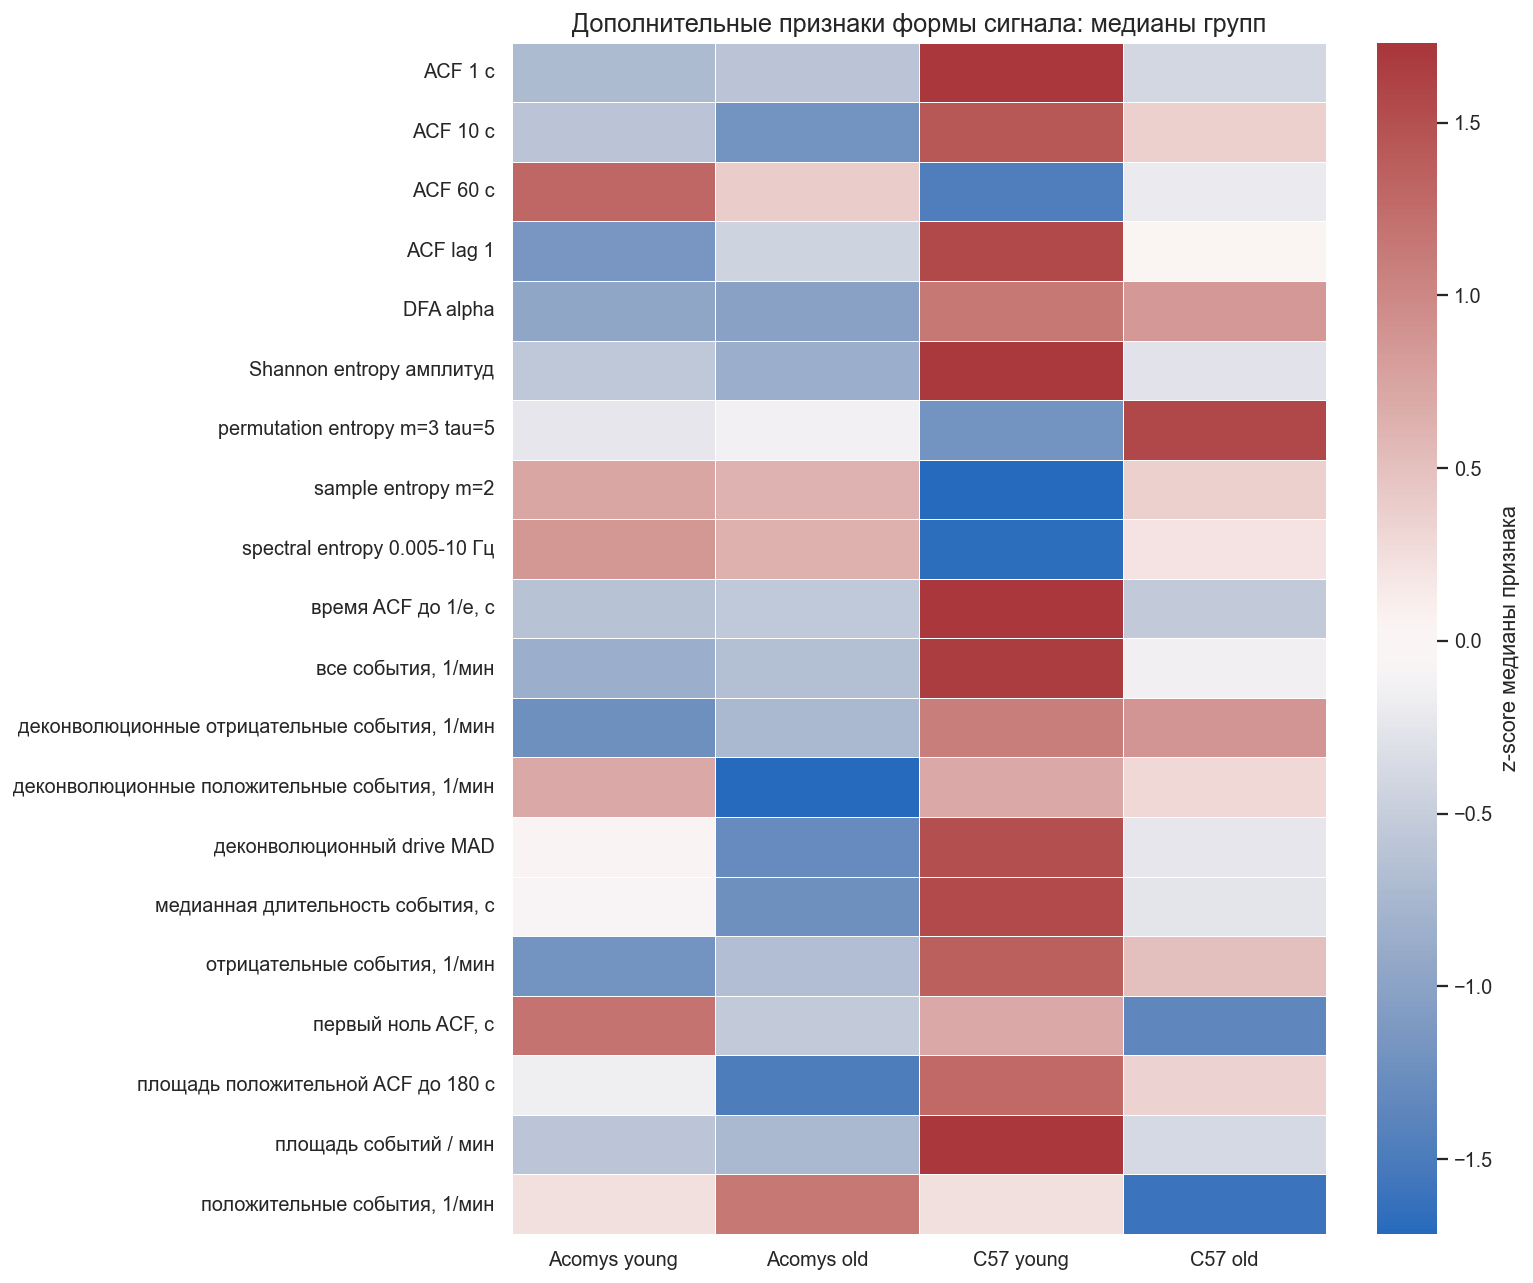

In [28]:
shape_metric_matrix = non_wavelet_group_summary.pivot(index='metric_title', columns='group', values='median').reindex(columns=GROUP_ORDER)
shape_metric_matrix_z = shape_metric_matrix.apply(lambda row: (row - row.mean()) / row.std(ddof=0) if row.std(ddof=0) > 0 else 0, axis=1)

fig, axis = plt.subplots(figsize=(12, 10))
sns.heatmap(shape_metric_matrix_z.astype(float), cmap='vlag', center=0, linewidths=0.4, cbar_kws={'label': 'z-score медианы признака'}, ax=axis)
axis.set_title('Дополнительные признаки формы сигнала: медианы групп')
axis.set_xlabel('')
axis.set_ylabel('')
fig.tight_layout()
plt.show()


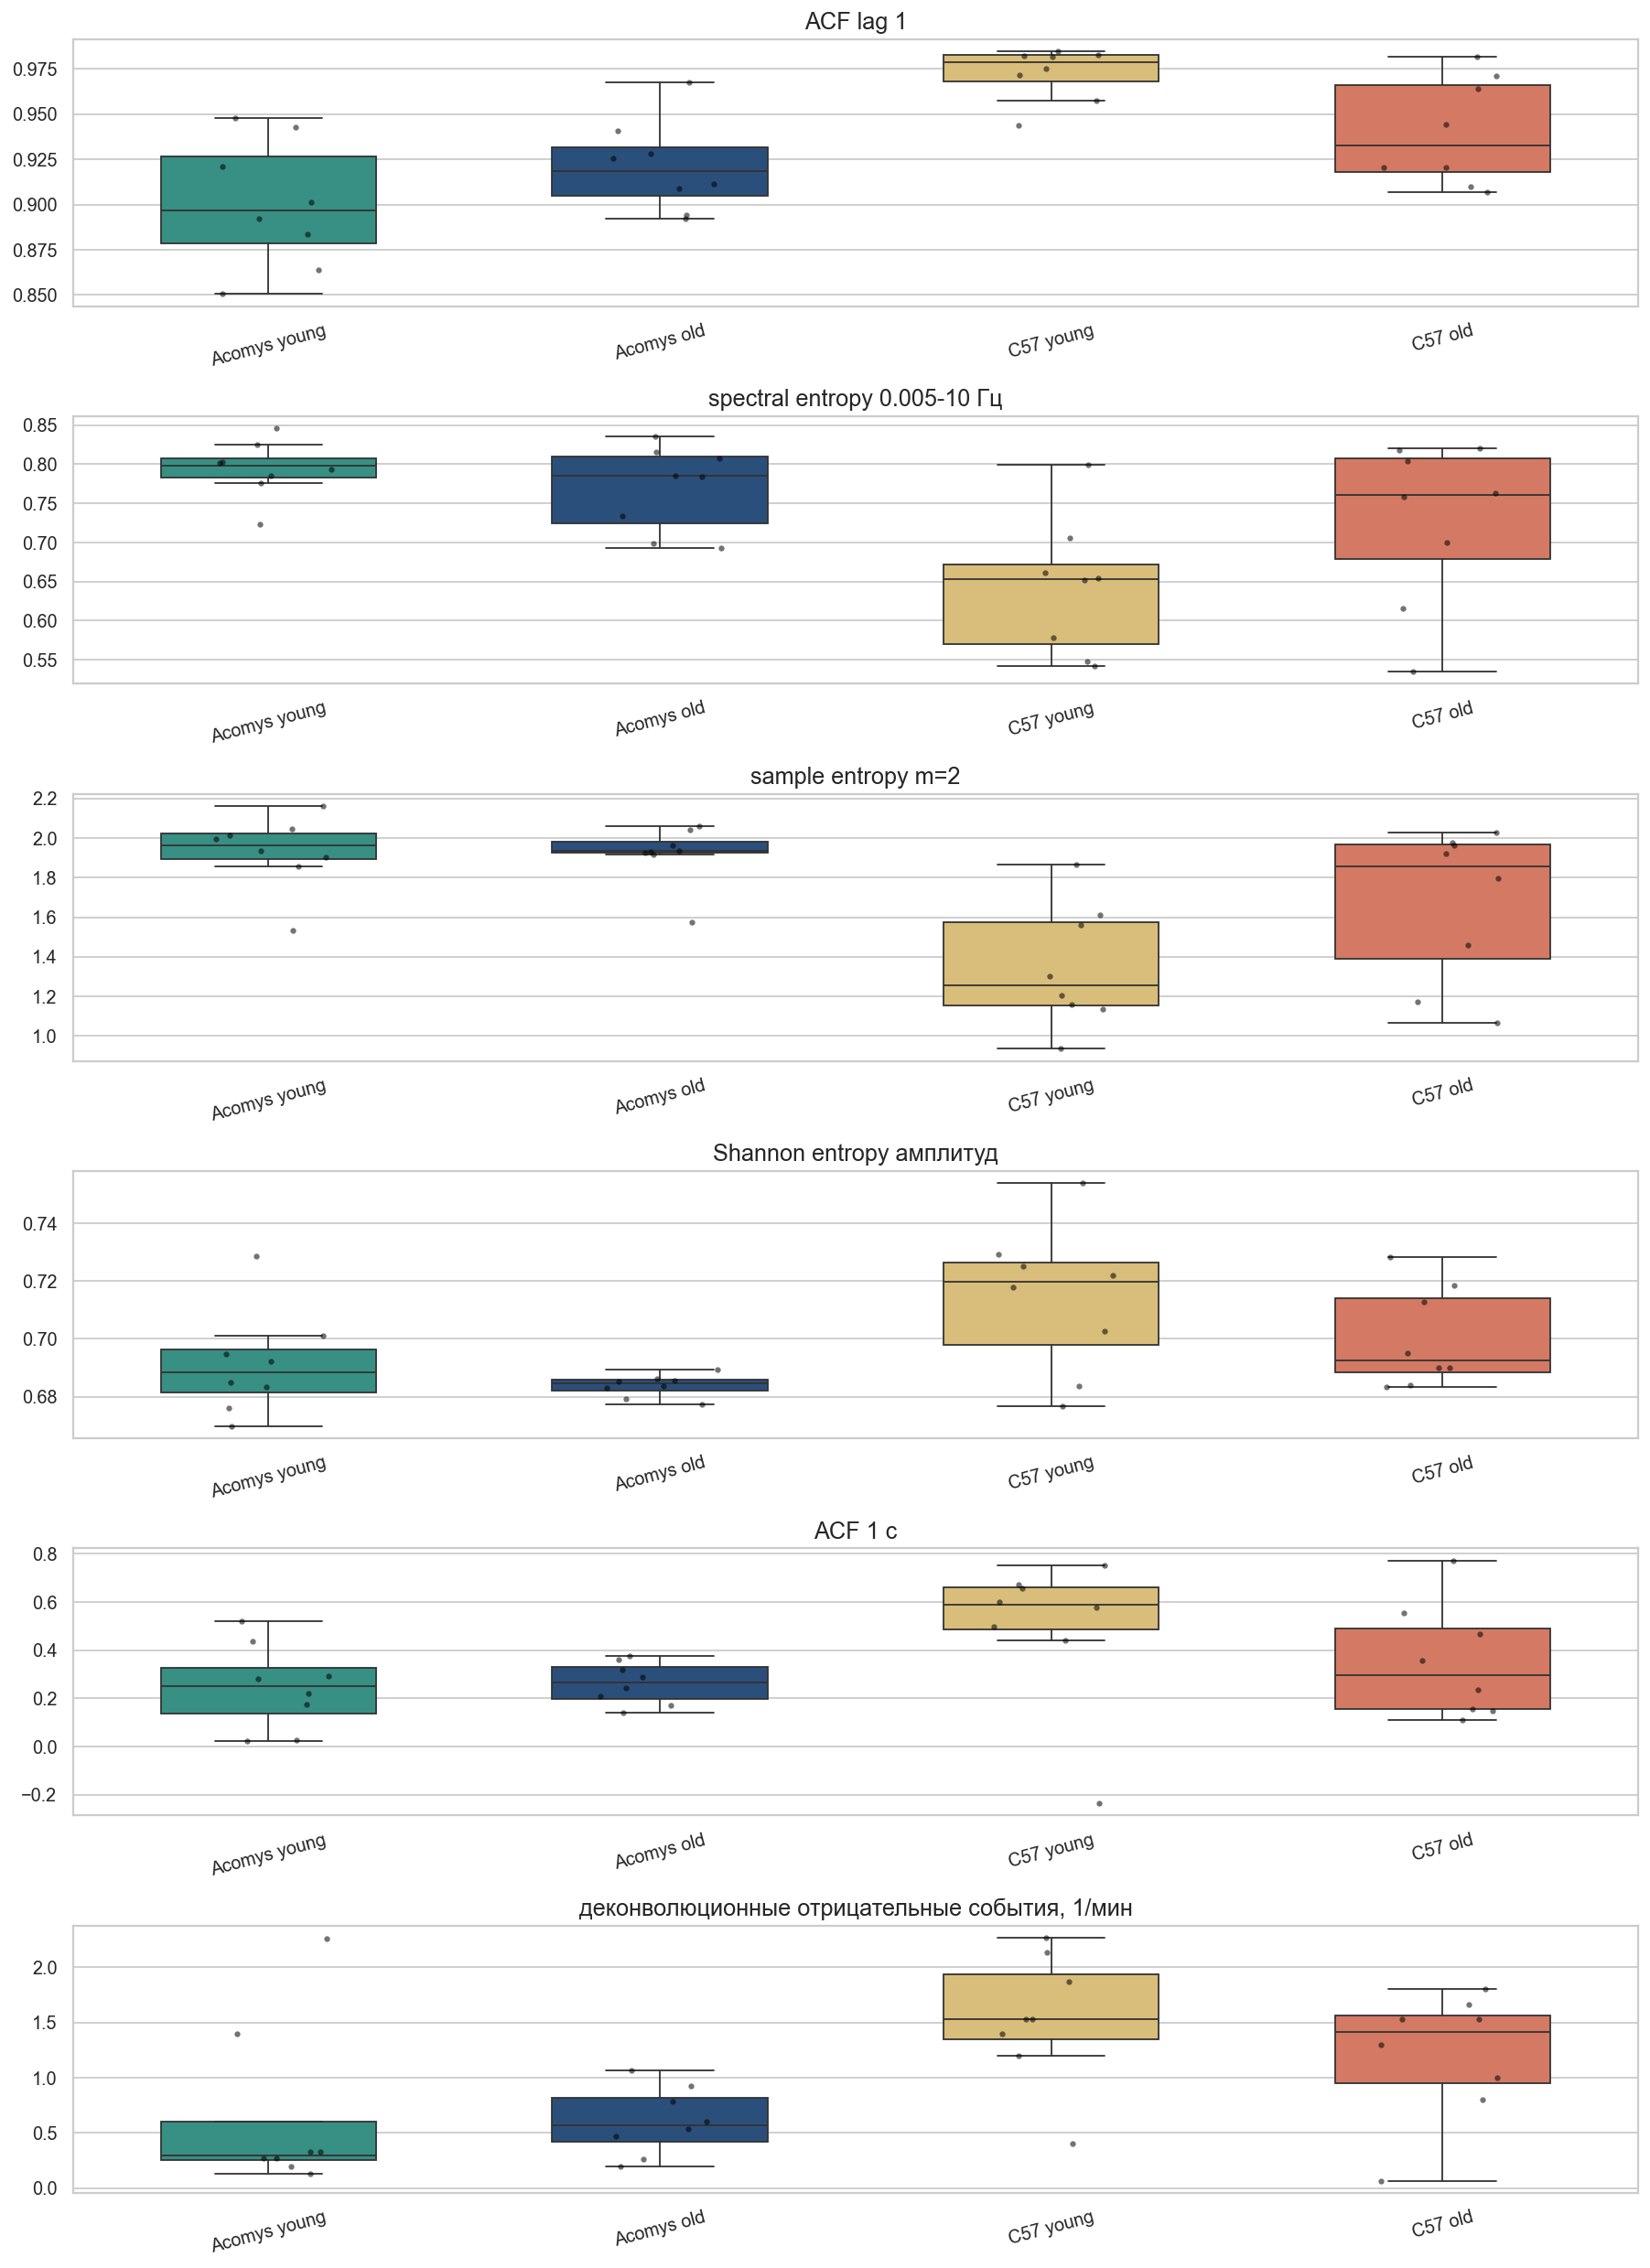

In [29]:
top_shape_metrics = non_wavelet_tests.sort_values(['q_value', 'p_value'], na_position='last')['metric'].drop_duplicates().head(6).tolist()
shape_title_lookup = non_wavelet_group_summary.drop_duplicates('metric').set_index('metric')['metric_title'].to_dict()
shape_plot_data = non_wavelet_features.melt(id_vars=['relative_path', 'group'], value_vars=top_shape_metrics, var_name='metric', value_name='value')

fig, axes = plt.subplots(len(top_shape_metrics), 1, figsize=(14, max(4, 3.2 * len(top_shape_metrics))))
axes = np.atleast_1d(axes)
for axis, metric in zip(axes, top_shape_metrics):
    metric_data = shape_plot_data[shape_plot_data['metric'] == metric]
    sns.boxplot(data=metric_data, x='group', y='value', order=GROUP_ORDER, hue='group', palette=GROUP_PALETTE, legend=False, fliersize=0, width=0.55, ax=axis)
    sns.stripplot(data=metric_data, x='group', y='value', order=GROUP_ORDER, color='black', alpha=0.55, size=3.5, jitter=0.16, ax=axis)
    axis.set_title(shape_title_lookup[metric])
    axis.set_xlabel('')
    axis.set_ylabel('')
    axis.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()


In [30]:
shape_hits = non_wavelet_tests[non_wavelet_tests['q_value'] < 0.05].sort_values(['q_value', 'p_value'])
shape_hit_names = ', '.join(shape_hits['metric_title'].tolist()) if len(shape_hits) else 'нет'
display(Markdown(
    f"**Вывод по дополнительным признакам формы сигнала.** После FDR `q<0.05` проходят {len(shape_hits)} сравнения: {shape_hit_names}. "
    "Все они относятся к сравнению молодых Acomys и молодых C57. У молодых C57 возможные артефакты обнаружены в 7 из 8 записей, поэтому эти признаки характеризуют различие записей, но не доказывают физиологическое различие. Возрастные контрасты после FDR незначимы. Деконволюционные показатели остаются только разведочными индексами резких изменений сигнала."
))


**Вывод по дополнительным признакам формы сигнала.** После FDR `q<0.05` проходят 3 сравнения: ACF lag 1, spectral entropy 0.005-10 Гц, sample entropy m=2. Все они относятся к сравнению молодых Acomys и молодых C57. У молодых C57 возможные артефакты обнаружены в 7 из 8 записей, поэтому эти признаки характеризуют различие записей, но не доказывают физиологическое различие. Возрастные контрасты после FDR незначимы. Деконволюционные показатели остаются только разведочными индексами резких изменений сигнала.

## Чувствительность кровотока к разметке частотных полос

Основной CWT-анализ использует мышиную схему частотных полос. Ниже добавлена проверка чувствительности: те же глобальные CWT-спектры агрегируются по двум схемам. Первая схема совпадает с основной. Вторая делает более узкую нарезку низких частот и переносит дыхательно-сердечную границу ниже; это не заменяет основную схему, а показывает, насколько вывод зависит от выбранных границ.

В каждой полосе `log10(mean power)` сравнивается двусторонним критерием Манна—Уитни по четырём плановым контрастам; единица наблюдения — животное. FDR контролируется методом Benjamini—Hochberg одновременно по всем 52 тестам обеих схем. В итоговой таблице этот результат обозначен `q_value_across_scheme_tests`. `cliffs_delta_a_minus_b` положительна при более высоких значениях в A и отрицательна при более высоких значениях в B.


In [31]:
main_scheme = [{'scheme': 'main_mouse_scheme', 'band': row['band'], 'band_title': row['band_title'], 'f_min_hz': row['f_min_hz'], 'f_max_hz': row['f_max_hz']} for _, row in blood_frequency_bands.iterrows()]
sensitivity_scheme = [
    {'scheme': 'low_frequency_sensitivity', 'band': 'very_low_endothelial', 'band_title': '0.005-0.020 Гц', 'f_min_hz': 0.005, 'f_max_hz': 0.020},
    {'scheme': 'low_frequency_sensitivity', 'band': 'low_neurogenic', 'band_title': '0.020-0.060 Гц', 'f_min_hz': 0.020, 'f_max_hz': 0.060},
    {'scheme': 'low_frequency_sensitivity', 'band': 'low_myogenic', 'band_title': '0.060-0.150 Гц', 'f_min_hz': 0.060, 'f_max_hz': 0.150},
    {'scheme': 'low_frequency_sensitivity', 'band': 'low_respiratory', 'band_title': '0.150-0.400 Гц', 'f_min_hz': 0.150, 'f_max_hz': 0.400},
    {'scheme': 'low_frequency_sensitivity', 'band': 'low_cardiac', 'band_title': '0.400-2.000 Гц', 'f_min_hz': 0.400, 'f_max_hz': 2.000},
    {'scheme': 'low_frequency_sensitivity', 'band': 'high_2_10', 'band_title': '2.000-10.000 Гц', 'f_min_hz': 2.000, 'f_max_hz': 10.000},
]

blood_spectrum_metadata_columns = ['relative_path', 'file_name', 'species', 'age', 'group', 'animal_id', 'weight_g']
blood_spectrum_metadata = blood_spectrum[blood_spectrum_metadata_columns].drop_duplicates('relative_path')

scheme_rows = []
for band_definition in main_scheme + sensitivity_scheme:
    frequency_mask = (blood_spectrum['frequency_hz'] >= band_definition['f_min_hz']) & (blood_spectrum['frequency_hz'] < band_definition['f_max_hz'])
    aggregated = blood_spectrum[frequency_mask].groupby('relative_path', as_index=False).agg(mean_power=('global_mean_power', 'mean'))
    aggregated = aggregated.merge(blood_spectrum_metadata, on='relative_path', how='left')
    for key, value in band_definition.items():
        aggregated[key] = value
    scheme_rows.append(aggregated)

blood_scheme_metrics = pd.concat(scheme_rows, ignore_index=True)
blood_scheme_metrics['log10_mean_power'] = np.log10(blood_scheme_metrics['mean_power'] + 1e-12)
blood_scheme_metrics.to_csv(RESULTS_DIR / 'blood_flow_band_scheme_metrics.csv', index=False)

scheme_test_rows = []
for scheme, scheme_data in blood_scheme_metrics.groupby('scheme'):
    for band, band_data in scheme_data.groupby('band'):
        tests = planned_continuous_tests(band_data, ['log10_mean_power'], f'blood_flow_{scheme}')
        tests['scheme'] = scheme
        tests['band'] = band
        tests['band_title'] = band_data['band_title'].iloc[0]
        scheme_test_rows.append(tests)

blood_scheme_tests = pd.concat(scheme_test_rows, ignore_index=True)
blood_scheme_tests['q_value_across_scheme_tests'] = bh_q(blood_scheme_tests['p_value'])
blood_scheme_tests.to_csv(RESULTS_DIR / 'blood_flow_band_scheme_planned_tests.csv', index=False)
scheme_min_q = blood_scheme_tests.sort_values(['scheme', 'q_value_across_scheme_tests', 'p_value']).groupby('scheme', as_index=False).head(6)
display(scheme_min_q[['scheme', 'band_title', 'contrast_title', 'group_a', 'group_b', 'median_a', 'median_b', 'p_value', 'q_value_across_scheme_tests']])


,scheme,band_title,contrast_title,group_a,group_b,median_a,median_b,p_value,q_value_across_scheme_tests
8,low_frequency_sensitivity,0.060-0.150 Гц,возраст внутри C57,C57 young,C57 old,-2.775184,-3.459153,0.001865,0.032323
16,low_frequency_sensitivity,0.150-0.400 Гц,вид/линия у молодых,Acomys young,C57 young,-3.629391,-3.251097,0.001865,0.032323
9,low_frequency_sensitivity,0.060-0.150 Гц,вид/линия у молодых,Acomys young,C57 young,-3.373145,-2.775184,0.006993,0.045455
17,low_frequency_sensitivity,0.150-0.400 Гц,возраст внутри C57,C57 young,C57 old,-3.251097,-3.656920,0.006993,0.045455
12,low_frequency_sensitivity,0.020-0.060 Гц,возраст внутри C57,C57 young,C57 old,-2.354761,-3.090806,0.014763,0.085297
13,low_frequency_sensitivity,0.020-0.060 Гц,вид/линия у молодых,Acomys young,C57 young,-2.875781,-2.354761,0.064957,0.269697
40,main_mouse_scheme,миогенная,вид/линия у молодых,Acomys young,C57 young,-3.629391,-3.251097,0.001865,0.032323
41,main_mouse_scheme,миогенная,возраст внутри C57,C57 young,C57 old,-3.251097,-3.656920,0.006993,0.045455
44,main_mouse_scheme,нейрогенная,возраст внутри C57,C57 young,C57 old,-2.650341,-3.381497,0.006993,0.045455
45,main_mouse_scheme,нейрогенная,вид/линия у молодых,Acomys young,C57 young,-3.253740,-2.650341,0.006993,0.045455


**Вывод по чувствительности к границам полос.** В расчёт входят все 32 животных. После общей FDR-поправки по 52 тестам восемь сравнений имеют `q<0,05`, ещё одно — `q<0,10`. У молодых C57 мощность выше, чем у старых C57 и молодых Acomys, прежде всего в диапазоне 0,06–0,40 Гц. Эти два контраста проходят FDR как в основной схеме для нейрогенной (0,04–0,15 Гц) и миогенной (0,15–0,40 Гц) полос, так и при альтернативной границе 0,06 Гц. Для диапазона 0,02–0,06 Гц возрастной контраст C57 остаётся только на уровне `q=0,085`, а для более низких и высоких частот устойчивых различий нет. Следовательно, основной сигнал не исчезает при умеренном изменении границ и локализован главным образом в 0,06–0,40 Гц. Однако эта устойчивость не устраняет проблему качества записей: возможные артефакты отмечены у 7 из 8 молодых C57, поэтому результат нельзя однозначно считать физиологическим.


## Межтестовые связи у C57

C57 можно связывать по ID между экспериментами. Здесь объединяются CWT-признаки кровотока, Barnes maze, rotarod и силомер. У Acomys такой блок не строится, потому что номера животных между экспериментами ненадёжны.

Корреляции здесь особенно разведочные: всего 16 C57, а часть связи может отражать возрастную структуру группы. Для каждой пары рассчитывается коэффициент ранговой корреляции Спирмена и его двусторонний p-value. FDR контролируется методом Benjamini—Hochberg одновременно по всем 66 корреляциям; `q_value` — результат этой поправки. Возраст в этой таблице не скорректирован, поэтому связи используются только для генерации гипотез.


In [32]:
c57_blood = blood_band[(blood_band['species'] == 'C57') & (blood_band['band_kind'] == 'physiology')].pivot_table(index=['species', 'age', 'group', 'animal_id'], columns='band', values='log10_mean_power', aggfunc='first').reset_index()
c57_blood = c57_blood.rename(columns={band: f'blood_log10_power_{band}' for band in c57_blood.columns if band not in ['species', 'age', 'group', 'animal_id']})
c57_barnes = barnes_subject[barnes_subject['species'] == 'C57'].copy()
c57_rotarod = rotarod[rotarod['species'] == 'C57'].copy()
c57_grip = grip_primary[grip_primary['species'] == 'C57'].pivot_table(
    index=['species', 'age', 'group', 'animal_id', 'weight_g'], columns='endpoint',
    values='max_force_per_g_harness_equivalent', aggfunc='first',
).reset_index()
c57_grip = c57_grip.rename(columns={
    endpoint: f'grip_max_force_per_g_harness_equivalent_{endpoint}'
    for endpoint in GRIP_ENDPOINT_ORDER
})
grip_correlation_cols = [column for column in c57_grip.columns if column.startswith('grip_')]

c57_merged = c57_blood.merge(c57_barnes.drop(columns=['weight_g'], errors='ignore'), on=['species', 'age', 'group', 'animal_id'], how='left')
c57_merged = c57_merged.merge(c57_rotarod[['species', 'age_clean', 'group', 'animal_id', 'rotarod_trial1_s', 'rotarod_trial2_s', 'rotarod_improvement_s']].rename(columns={'age_clean': 'age'}), on=['species', 'age', 'group', 'animal_id'], how='left')
c57_merged = c57_merged.merge(c57_grip[['species', 'age', 'group', 'animal_id', 'weight_g'] + grip_correlation_cols], on=['species', 'age', 'group', 'animal_id'], how='left')
c57_merged.to_csv(RESULTS_DIR / 'c57_cross_test_merged_table.csv', index=False)
display(c57_merged.head(20))


,species,age,group,animal_id,blood_log10_power_cardiac,blood_log10_power_endothelial_NO_dependent,blood_log10_power_endothelial_NO_independent,blood_log10_power_myogenic,blood_log10_power_neurogenic,blood_log10_power_respiratory,barnes_first_training_find_latency_s,barnes_last_training_find_latency_s,barnes_training_find_latency_change_s,barnes_first_training_strategy_score,barnes_last_training_strategy_score,barnes_training_strategy_change,barnes_short_find_latency_s,barnes_short_found,barnes_short_strategy_score,barnes_long_find_latency_s,barnes_long_found,barnes_long_strategy_score,rotarod_trial1_s,rotarod_trial2_s,rotarod_improvement_s,weight_g,grip_max_force_per_g_harness_equivalent_mean,grip_max_force_per_g_harness_equivalent_trial_1,grip_max_force_per_g_harness_equivalent_trial_2,grip_max_force_per_g_harness_equivalent_trial_3
0,C57,old,C57 old,1,-4.903823,-2.546530,-1.796037,-3.554563,-3.332729,-3.961502,80.3,37.9,-42.4,4.0,4.0,0.0,19.0,1,9.0,33.9,1,4.0,9,20,11,29.0,0.028872,0.035184,0.024373,0.026997
1,C57,old,C57 old,3,-5.080898,-3.067218,-2.707684,-3.657724,-3.430266,-4.129775,104.7,29.4,-75.3,4.0,4.0,0.0,38.7,1,4.0,16.0,1,5.0,5,24,19,32.0,0.029597,0.029328,0.024557,0.035126
2,C57,old,C57 old,6,-4.737030,-1.964705,-1.720461,-3.170030,-2.822554,-3.626469,10.8,6.6,-4.2,8.0,9.0,1.0,14.0,1,4.0,34.3,1,4.0,11,13,2,34.0,0.020286,0.021826,0.015107,0.024507
3,C57,old,C57 old,8,-4.380221,-2.326562,-1.557389,-3.536302,-3.267519,-3.297122,114.5,42.6,-71.9,4.0,4.0,0.0,7.1,1,11.0,12.1,1,6.0,6,19,13,44.0,0.020004,0.020090,0.018159,0.021479
4,C57,old,C57 old,9,-4.939439,-1.806441,-1.117465,-3.656116,-3.065718,-4.000878,6.7,60.3,53.6,11.0,4.0,-7.0,58.7,1,4.0,43.9,1,4.0,27,10,-17,31.0,0.025017,0.034323,0.017277,0.024353
5,C57,old,C57 old,11,-5.418367,-2.569360,-1.945552,-3.924839,-3.653818,-4.378358,72.9,42.3,-30.6,4.0,4.0,0.0,17.3,1,11.0,53.8,1,2.0,10,10,0,31.0,0.033928,0.050164,0.022942,0.029945
6,C57,old,C57 old,14,-5.126892,-2.733833,-2.432865,-3.857191,-3.540627,-4.292407,88.4,10.9,-77.5,1.0,7.0,6.0,16.8,1,4.0,21.0,1,2.0,11,11,0,32.0,0.018873,0.019097,0.016600,0.020796
7,C57,old,C57 old,16,-5.072510,-3.351319,-2.853279,-3.905246,-3.726487,-4.210401,16.8,24.1,7.3,8.0,4.0,-4.0,14.0,1,6.0,9.0,1,7.0,6,19,13,32.0,0.027774,0.032227,0.022637,0.028660
8,C57,young,C57 young,2,-5.006032,-2.481093,-1.899456,-3.580413,-2.639364,-4.013677,36.0,11.0,-25.0,4.0,5.0,1.0,16.9,1,5.0,19.5,1,4.0,9,14,5,29.0,0.032546,0.036842,0.031885,0.026084
9,C57,young,C57 young,4,-4.596904,-1.402594,-1.034817,-2.844107,-2.173191,-3.572043,21.4,20.7,-0.7,4.0,5.0,1.0,4.2,1,11.0,19.8,1,4.0,8,16,8,28.0,0.030238,0.029753,0.044766,0.021749


,blood_metric,outcome_metric,n,spearman_rho,p_value,q_value
33,blood_log10_power_myogenic,barnes_last_training_find_latency_s,16,-0.612215,0.011709,0.462235
42,blood_log10_power_myogenic,grip_max_force_per_g_harness_equivalent_trial_2,16,0.600000,0.014007,0.462235
53,blood_log10_power_neurogenic,grip_max_force_per_g_harness_equivalent_trial_2,16,0.561765,0.023537,0.517814
44,blood_log10_power_neurogenic,barnes_last_training_find_latency_s,16,-0.501840,0.047627,0.685994
51,blood_log10_power_neurogenic,grip_max_force_per_g_harness_equivalent_mean,16,0.479412,0.060239,0.685994
5,blood_log10_power_cardiac,rotarod_trial2_s,16,0.475986,0.062363,0.685994
40,blood_log10_power_myogenic,grip_max_force_per_g_harness_equivalent_mean,16,0.405882,0.118792,0.714356
31,blood_log10_power_endothelial_NO_independent,grip_max_force_per_g_harness_equivalent_trial_2,16,0.402941,0.121746,0.714356
20,blood_log10_power_endothelial_NO_dependent,grip_max_force_per_g_harness_equivalent_trial_2,16,0.397059,0.127806,0.714356
32,blood_log10_power_endothelial_NO_independent,grip_max_force_per_g_harness_equivalent_trial_3,16,-0.394118,0.130913,0.714356


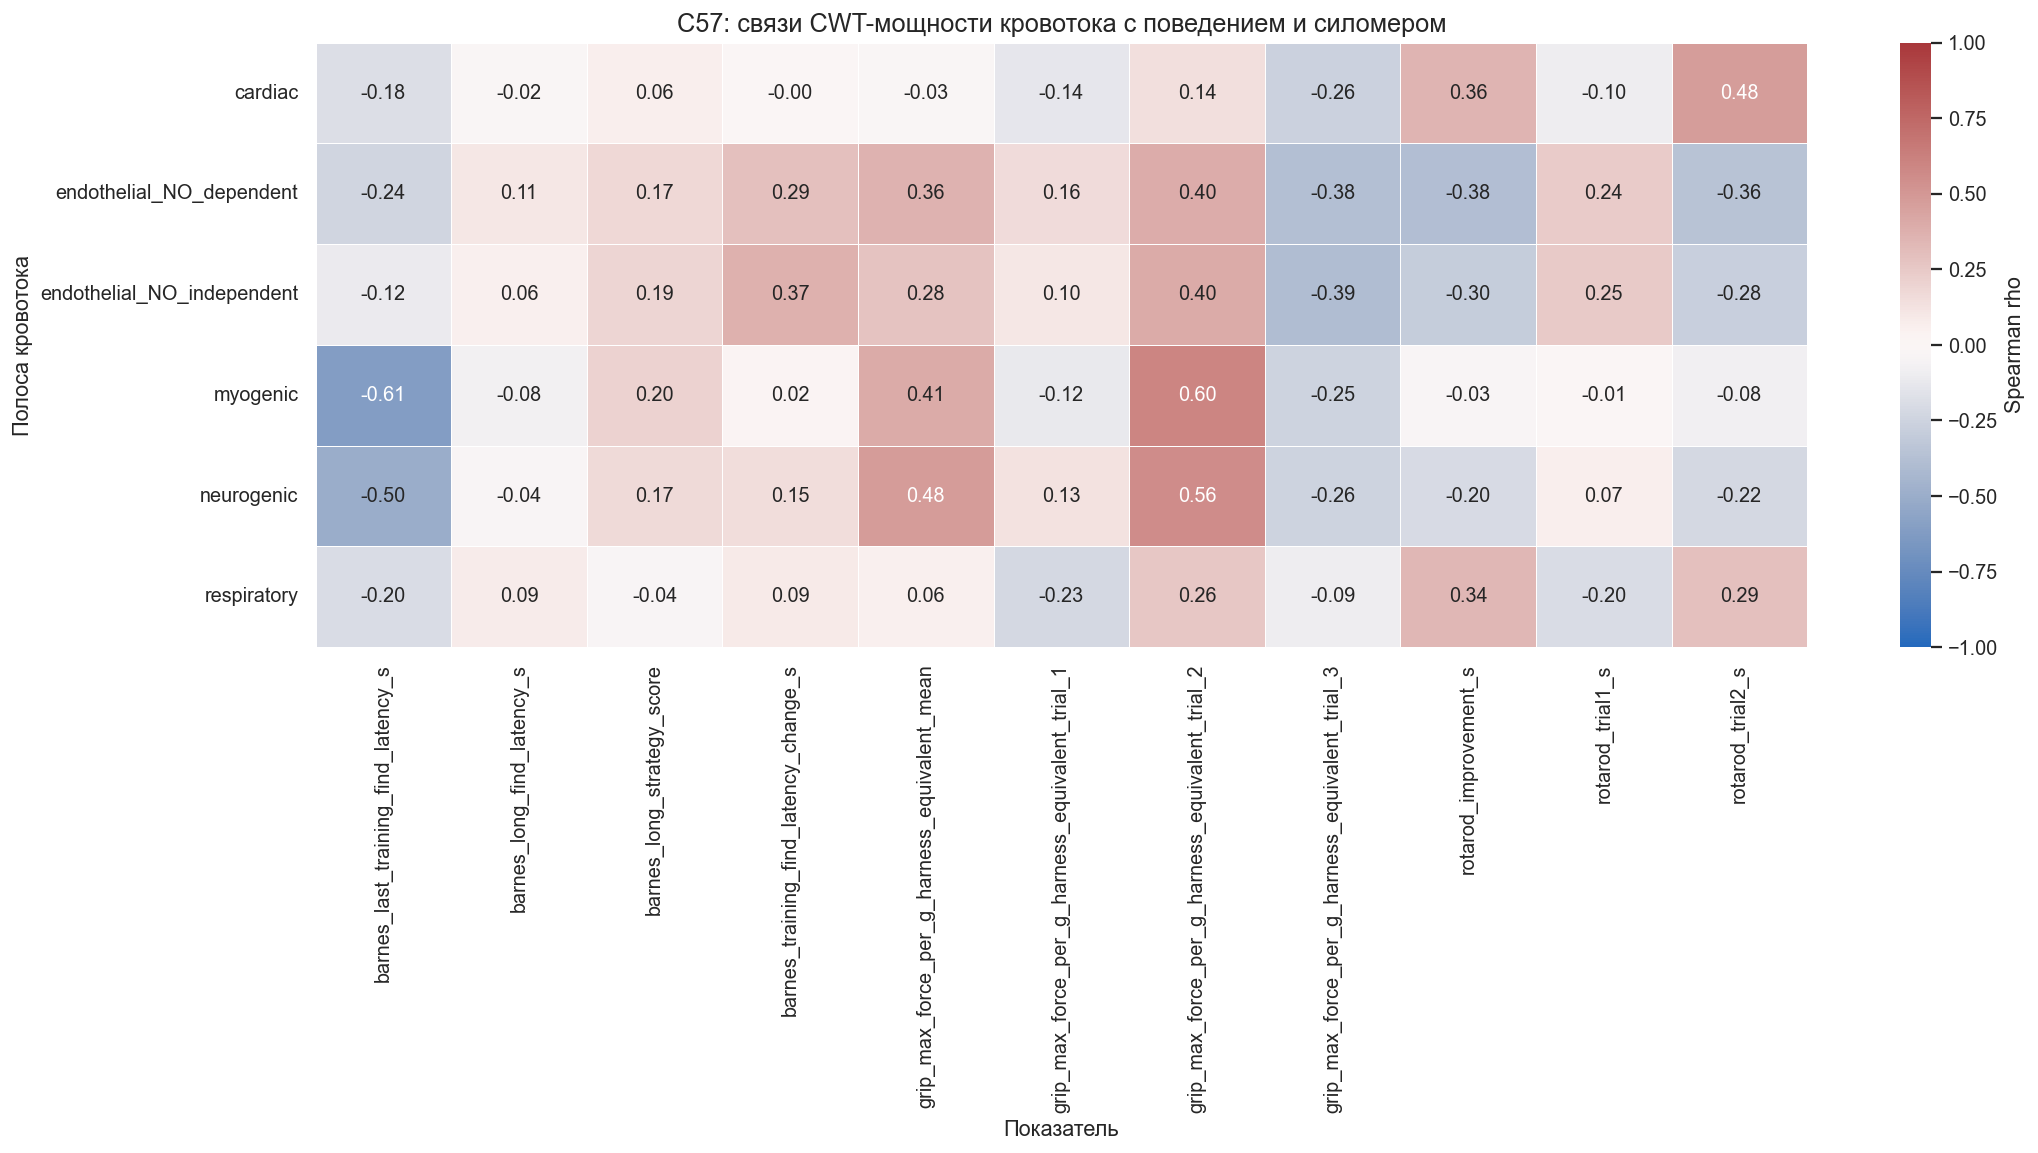

In [33]:
blood_correlation_cols = [col for col in c57_merged.columns if col.startswith('blood_log10_power_')]
outcome_cols = ['barnes_last_training_find_latency_s', 'barnes_training_find_latency_change_s', 'barnes_long_find_latency_s', 'barnes_long_strategy_score', 'rotarod_trial1_s', 'rotarod_trial2_s', 'rotarod_improvement_s'] + grip_correlation_cols
correlation_rows = []
for blood_metric in blood_correlation_cols:
    for outcome in outcome_cols:
        pair_data = c57_merged[[blood_metric, outcome]].dropna()
        if len(pair_data) >= 6:
            rho, p_value = stats.spearmanr(pair_data[blood_metric], pair_data[outcome])
        else:
            rho, p_value = np.nan, np.nan
        correlation_rows.append({'blood_metric': blood_metric, 'outcome_metric': outcome, 'n': len(pair_data), 'spearman_rho': rho, 'p_value': p_value})

c57_correlations = pd.DataFrame(correlation_rows)
c57_correlations['q_value'] = bh_q(c57_correlations['p_value'])
c57_correlations.to_csv(RESULTS_DIR / 'c57_cross_test_spearman_correlations.csv', index=False)
display(c57_correlations.sort_values(['q_value', 'p_value'], na_position='last').head(30))

heatmap_data = c57_correlations.pivot(index='blood_metric', columns='outcome_metric', values='spearman_rho')
heatmap_data.index = heatmap_data.index.str.replace('blood_log10_power_', '', regex=False)
fig, axis = plt.subplots(figsize=(17, 9))
sns.heatmap(heatmap_data, cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Spearman rho'}, ax=axis)
axis.set_title('C57: связи CWT-мощности кровотока с поведением и силомером')
axis.set_xlabel('Показатель')
axis.set_ylabel('Полоса кровотока')
fig.tight_layout()
plt.show()


In [34]:
best_c57_corr = c57_correlations.sort_values(['q_value', 'p_value'], na_position='last').iloc[0]
c57_corr_hits = c57_correlations[c57_correlations['q_value'] < 0.1]
c57_corr_conclusion = f"**Вывод по C57-связям.** Корреляций с q<0.1 после FDR: {len(c57_corr_hits)}. Самая сильная непоправленная связь: {best_c57_corr['blood_metric']} vs {best_c57_corr['outcome_metric']}, rho={best_c57_corr['spearman_rho']:.2f}, p={best_c57_corr['p_value']:.3g}, q={best_c57_corr['q_value']:.3g}, n={int(best_c57_corr['n'])}. При таком n этот блок лучше использовать для генерации гипотез, а не как финальное доказательство."
display(Markdown(c57_corr_conclusion))


**Вывод по C57-связям.** Корреляций с q<0.1 после FDR: 0. Самая сильная непоправленная связь: blood_log10_power_myogenic vs barnes_last_training_find_latency_s, rho=-0.61, p=0.0117, q=0.462, n=16. При таком n этот блок лучше использовать для генерации гипотез, а не как финальное доказательство.

## Связи с массой тела внутри отдельных экспериментов

Масса тела учитывается там, где она относится к тому же эксперименту. Для Acomys не строятся межэкспериментальные связи между кровотоком, силомером и поведением, но внутри каждого набора можно проверить, не объясняется ли показатель массой. Для каждой пары рассчитывается коэффициент ранговой корреляции Спирмена с двусторонним p-value. FDR контролируется методом Benjamini—Hochberg одновременно по всем рассчитанным корреляциям этой таблицы; пропуски без p-value в поправку не входят. Анализ объединяет молодых и старых внутри вида/линии и используется для генерации гипотез.


In [35]:
weight_correlation_specs = []
for species in ['Acomys', 'C57']:
    for metric in ['barnes_last_training_find_latency_s', 'barnes_training_find_latency_change_s', 'barnes_long_find_latency_s', 'barnes_long_strategy_score']:
        weight_correlation_specs.append(('barnes', species, barnes_subject, metric, 'weight_g'))
for species in ['Acomys', 'C57']:
    for endpoint in GRIP_ENDPOINT_ORDER:
        grip_weight_data = grip_primary[(grip_primary['species'] == species) & (grip_primary['endpoint'] == endpoint)]
        weight_correlation_specs.append((f'grip_{endpoint}', species, grip_weight_data, 'max_force_per_g_harness_equivalent', 'weight_g'))
for species in ['Acomys', 'C57']:
    for band in feature_cols:
        weight_correlation_specs.append(('blood_flow', species, blood_power_wide, band, 'weight_g'))

weight_rows = []
for source, species, data, metric, weight_col in weight_correlation_specs:
    if weight_col not in data.columns or metric not in data.columns:
        continue
    part = data[data['species'] == species][[weight_col, metric, 'group']].dropna()
    if len(part) >= 6:
        rho, p_value = stats.spearmanr(part[weight_col], part[metric])
    else:
        rho, p_value = np.nan, np.nan
    weight_rows.append({'source': source, 'species': species, 'metric': metric, 'n': len(part), 'spearman_rho': rho, 'p_value': p_value})

weight_correlations = pd.DataFrame(weight_rows)
weight_correlations['q_value'] = bh_q(weight_correlations['p_value'])
weight_correlations.to_csv(RESULTS_DIR / 'weight_correlations_within_experiment.csv', index=False)
display(weight_correlations.sort_values(['q_value', 'p_value'], na_position='last').head(40))


,source,species,metric,n,spearman_rho,p_value,q_value
13,grip_trial_2,C57,max_force_per_g_harness_equivalent,16,-0.762194,0.000598,0.010387
10,grip_trial_3,Acomys,max_force_per_g_harness_equivalent,16,-0.744291,0.000944,0.010387
15,grip_mean,C57,max_force_per_g_harness_equivalent,16,-0.639885,0.007594,0.055687
12,grip_trial_1,C57,max_force_per_g_harness_equivalent,16,-0.466863,0.068286,0.375571
3,barnes,Acomys,barnes_long_strategy_score,18,0.378324,0.121608,0.535074
11,grip_mean,Acomys,max_force_per_g_harness_equivalent,16,-0.362565,0.167549,0.607554
14,grip_trial_3,C57,max_force_per_g_harness_equivalent,16,0.343062,0.193312,0.607554
16,blood_flow,Acomys,cardiac,16,0.235989,0.378909,0.859383
4,barnes,C57,barnes_last_training_find_latency_s,16,0.229125,0.393328,0.859383
2,barnes,Acomys,barnes_long_find_latency_s,18,0.210744,0.401240,0.859383


## Итоговая сводка

Главный устойчивый сигнал в доступных данных сейчас находится в rotarod: Acomys держатся на вращающемся стержне дольше C57, особенно среди молодых животных, и этот эффект проходит поправку на множественные сравнения. Состав группы `Acomys young` пока не подтверждён: вместо ожидаемых 8 животных доступны 11 строк, поэтому итоговые числа нужно пересчитать после получения списка включения. В Barnes maze сильных плановых различий после FDR не видно; тайм-ауты кодируются как 200 секунд. Нахождение цели и вход в escape box анализируются отдельно как бинарные исходы: вход в укрытие заметно вариативнее, но ни межгрупповые сравнения критерием Фишера, ни зависимые изменения `D1 T1 → D2 T2` критерием Мак-Немара не проходят FDR.

Силомер анализируется по четырём показателям: `Maxvalue` каждой из трёх попыток и среднему трёх `Maxvalue`. Каждый показатель нормируется на массу тела, после чего хвостовые значения C57 переводятся в harness-equivalent шкалу коэффициентом `шлейка / хвост`, рассчитанным отдельно для возраста и показателя. Каждый из восьми коэффициентов основан на двух парных C57, поэтому калибровка остаётся предварительной.

По кровотоку CWT и дополнительные признаки формы рассчитаны в этом ноутбуке непосредственно из EDR-файлов без интерполяционной очистки: резкие провалы сохранены, а их разметка используется как ограничение качества. Попарные сравнения не проходят `q<0.05`, но девять результатов находятся ниже `q<0.1`; факторные модели дают несколько `q<0.05`. Поскольку возможные артефакты сосредоточены в 7 из 8 записей `C57 young`, эти сигналы нельзя отделить от качества записи и следует использовать только как гипотезы.

Межтестовые корреляции строятся только для C57, потому что у них ID сквозные. При n=16 этот блок нужен для поиска направлений: даже сильные rho стоит перепроверять на дополнительных животных или в заранее заданной модели.


In [36]:
result_files = sorted(RESULTS_DIR.glob('*'))
result_table = pd.DataFrame({'file_name': [path.name for path in result_files], 'size_kb': [round(path.stat().st_size / 1024, 1) for path in result_files]})
display(result_table.head(100))


,file_name,size_kb
0,barnes_binary_group_summary.csv,4.8
1,barnes_binary_planned_tests.csv,5.9
2,barnes_binary_within_group_changes.csv,0.7
3,barnes_group_summary.csv,2.7
4,barnes_long_trials.csv,21.7
5,barnes_planned_tests.csv,7.2
6,barnes_subject_metrics.csv,3.1
7,blood_flow_artifact_summary.csv,0.2
8,blood_flow_band_scheme_metrics.csv,80.3
9,blood_flow_band_scheme_planned_tests.csv,16.4
